# Сравнение формы: где свисты и где молнии

Ноутбук смотрит, похожа ли **форма** кривой «где чаще свисты» на форму кривой «где чаще молнии». Высота кривых к сравнению не относится: каждая поделена на свой максимум.

**Свист** — вистлер. `verdict = 1` — на этой секунде свист отмечен. Доля `verdict=1` — доля таких секунд среди тех, что спутник провёл в бине.

**Что видно на сохранённых рисунках.** Общее окно ka1, ka2 и AE — 255 суток, 20.01.2025–31.10.2025. У ka4 в этих рисунках 10 суток, 21–31 августа 2025. Точное окно печатает ячейка загрузки.

**Разделы**

1. Сравнение формы вдоль широты и вдоль долготы. Сетка — сезон × полушарие, ночь и день отдельно, ka1 и ka2, затем те же рисунки для ka4.
2. Что стоит за одной точкой широтного графика: почасовой ход в четырёх квадратах 2°×2° за март и разрез по долготе в фиксированной широтной полосе за конкретные сутки.
3. Доза от магнитного следа (footprint), а не от точки под спутником: число молний в радиусе 1500 км за 120 с до сэмпла, против доли свистов, по широте и по долготе.
4. Тот же разрез без радиуса: просто сколько разрядов WWLLN попало в широтный или долготный бин.

**Итог.** На суммах за длинный период и по сетке сезон × полушарие формы доли свистов и молний устойчиво не сравниваются. Следующий шаг — отдельные полуорбиты в `wwlln_orbit_profiles.ipynb`.


In [2]:
import gzip
import os
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io


In [3]:
import wwlln_common as wc

PATHS = wc.resolve_paths()
path = PATHS['a']          # A-файлы: координаты разрядов
path_ae = PATHS['ae']      # AE-файлы: координаты + энергия VLF
path_pred = PATHS['pred']  # предсказания свистов ka1..ka4

print(f'Корень:   {PATHS["root"]}')
print(f'Afiles:   {path} ({len(list(path.glob("*.loc.gz"))) if path.exists() else 0} файлов)')
print(f'AEfiles:  {path_ae} ({len(list(path_ae.glob("*.loc.gz"))) if path_ae.exists() else 0} файлов)')
print(
    f'predictions: {path_pred} '
    f'(ka1={len(list((path_pred / "ka1").glob("predictions_ka1_fl_*.csv"))) if (path_pred / "ka1").exists() else 0}, '
    f'ka2={len(list((path_pred / "ka2").glob("predictions_ka2_fl_*.csv"))) if (path_pred / "ka2").exists() else 0}, '
    f'ka4={len(list((path_pred / "ka4").glob("predictions_ka4_fl_*.csv"))) if (path_pred / "ka4").exists() else 0})'
)

BASE_DIR: /Users/user/Downloads/wwlln/WWLLN
Afiles:   /Users/user/Downloads/wwlln/WWLLN/Afiles (365 файлов)
AEfiles:  /Users/user/Downloads/wwlln/WWLLN/AEfiles (365 файлов)
predictions: /Users/user/Downloads/wwlln/whistler_binary (ka1=255, ka2=273, ka4=10)


## Предсказания свистов

Файлы `predictions/whistler_binary`. Время в файле — МСК, при загрузке переводится в UTC (минус 3 часа). Читаем `timestamp, geo_lat, geo_lon, is_night, solar_zenith_angle, prob_whistle, verdict`. Магнитные координаты в файле есть; footprint ниже считается отдельно, через `mag_coords`.

ka1 и ka2 грузятся в `df_pred`. ka4 — в отдельный `df_pred_ka4`, чтобы не затереть уже построенные графики. В сохранённом выводе у ka4 десять файлов, 21–31 августа 2025.


In [7]:
%%time
from concurrent.futures import ThreadPoolExecutor

PRED_DIR = path_pred if 'path_pred' in dir() else (Path('.').resolve() / 'predictions' / 'whistler_binary')
PRED_MSK_OFFSET_HOURS = 3  # MSK = UTC+3
SC_LIST = ('ka1', 'ka2')  # бывшие sc1/sc2


def _read_pred_csv(filepath, sc: str):
    # mag_lat/mag_lon в файлах есть — пока не читаем.
    # prob_whistle нужен как непрерывный отклик: verdict = (prob >= 0.5), порог произвольный.
    d = pd.read_csv(
        filepath,
        usecols=['timestamp', 'geo_lat', 'geo_lon', 'is_night', 'solar_zenith_angle',
                 'prob_whistle', 'verdict'],
        dtype={
            'geo_lat': 'float32',
            'geo_lon': 'float32',
            'is_night': 'int8',
            'solar_zenith_angle': 'float32',
            'prob_whistle': 'float32',
            'verdict': 'int8',
        },
    )
    # файл в МСК → UTC
    d['timestamp'] = pd.to_datetime(d['timestamp'], utc=False) - pd.Timedelta(hours=PRED_MSK_OFFSET_HOURS)
    d['sc'] = sc
    return d


def load_predictions(sc_list=SC_LIST, n_jobs=8, max_files=None):
    parts = []
    for sc in sc_list:
        files = sorted((PRED_DIR / sc).glob(f'predictions_{sc}_fl_*.csv'))
        if max_files is not None:
            files = files[:max_files]
        print(f'{sc}: {len(files)} файлов из {PRED_DIR / sc}')
        if not files:
            continue
        with ThreadPoolExecutor(max_workers=n_jobs) as ex:
            frames = list(ex.map(lambda f, sc=sc: _read_pred_csv(f, sc), files))
        parts.append(pd.concat(frames, ignore_index=True))
        del frames
    if not parts:
        return pd.DataFrame()
    out = pd.concat(parts, ignore_index=True)
    out['sc'] = out['sc'].astype('category')
    return out





CPU times: user 12 μs, sys: 1e+03 ns, total: 13 μs
Wall time: 13.6 μs


In [ ]:
df_pred = load_predictions(sc_list=SC_LIST, n_jobs=8)
print(f'Загружено: {len(df_pred):,} строк (timestamp уже UTC)')
print(df_pred.groupby('sc', observed=True).size().rename('n').to_string())
print(f'Период UTC: {df_pred["timestamp"].min()} … {df_pred["timestamp"].max()}')
rate_by_sc = df_pred.groupby('sc', observed=True)[['verdict', 'prob_whistle']].mean()
print('Доля verdict=1 и средняя prob_whistle по КА:')
print(rate_by_sc.to_string())
df_pred.head()

#### ka4 — загрузка

Отдельный кадр `df_pred_ka4`. В сохранённом выводе — 10 суток, 21–31 августа 2025.


In [8]:
%%time
# ka4 отдельно — не трогаем df_pred (ka1/ka2) и уже построенные графики
SC_LIST_KA4 = ('ka4',)
df_pred_ka4 = load_predictions(sc_list=SC_LIST_KA4, n_jobs=8)
if df_pred_ka4 is None or getattr(df_pred_ka4, 'empty', True):
    raise ValueError('ka4: нет файлов predictions в ' + str(PRED_DIR / 'ka4'))
print(f'ka4 загружено: {len(df_pred_ka4):,} строк (timestamp уже UTC)')
print(f'Период UTC: {df_pred_ka4["timestamp"].min()} … {df_pred_ka4["timestamp"].max()}')
rate_ka4 = df_pred_ka4.groupby('sc', observed=True)[['verdict', 'prob_whistle']].mean()
print('Доля verdict=1 и средняя prob_whistle (ka4):')
print(rate_ka4.to_string())
df_pred_ka4.head()


ka4: 10 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka4
ka4 загружено: 693,512 строк (timestamp уже UTC)
Период UTC: 2025-08-21 15:39:41 … 2025-08-31 20:59:58
Доля verdict=1 и средняя prob_whistle (ka4):
      verdict  prob_whistle
sc                         
ka4  0.231798      0.251541
CPU times: user 644 ms, sys: 163 ms, total: 807 ms
Wall time: 594 ms


,timestamp,geo_lat,geo_lon,is_night,solar_zenith_angle,prob_whistle,verdict,sc
0,2025-08-21 15:39:41,-27.448999,169.190002,1,136.580002,0.006,0,ka4
1,2025-08-21 15:39:42,-27.500000,169.175995,1,136.580002,0.017,0,ka4
2,2025-08-21 15:39:43,-27.548000,169.162994,1,136.580002,0.001,0,ka4
3,2025-08-21 15:39:44,-27.594000,169.149994,1,136.580002,0.010,0,ka4
4,2025-08-21 15:39:45,-27.639000,169.138000,1,136.570007,0.048,0,ka4


## Молнии и доля свистов — сравнение формы

Совпадает ли форма кривой доли свистов с формой плотности молний вдоль широты и вдоль долготы.

| | Доля свистов | Молнии |
|---|---|---|
| метрика | `verdict=1 / exposure` | число разрядов на площадь бина |
| выборка | секунды на орбите | разряды в те же дни этого аппарата и в бинах, где экспозиция не ниже `MIN_EXP` |
| ночь/день | солнечный зенитный угол на поверхности `SZA > 98°` | тот же порог |
| ось Y | каждая кривая к своему максимуму | то же |

`is_night` в файле — тень самого спутника (`SZA > 117.6°`, высота орбиты около 800 км). Для свиста важна освещённость ионосферы под аппаратом, поэтому ночь считается по зенитному углу на поверхности, порог 98°.

Молния и свист здесь не сопоставляются по секундам: сравниваются климатические кривые. На рисунке долготы молнии берутся из тех широт, где у спутника есть экспозиция. Полушария и порог энергии `ENERGY_MIN_J` разведены по разным кривым. Сетка панели — 4 сезона × 2 полушария.

Сначала агрегация и рисунки ka1 и ka2 (широта, затем долгота). Подзаголовки ka4 повторяют то же на его 10 сутках.


In [113]:
# --- параметры сравнения формы ---
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
importlib.reload(wc)

MIN_EXP = 200          # мин. секунд экспозиции в бине
ENERGY_MIN_J = 1000    # вторая кривая молний
SC_LIST_CMP = ('ka1', 'ka2')
# Ночь — солнечный зенитный угол НА ПОВЕРХНОСТИ, одинаково для КА и молний и
# одинаково во всех блоках ноутбука (wwlln_common.NIGHT_SZA_DEG = 98°).
# Колонка is_night в файлах — это другое: тень Земли на высоте орбиты (SZA>117.6°),
# т.е. «спутник не освещён», а не «под спутником темно».
NIGHT_SZA_DEG = wc.NIGHT_SZA_DEG

_paths_cmp = wc.resolve_paths()
# Один и тот же период для ka1 и ka2, иначе разница между аппаратами смешана
# с разницей дат (ka1 стартует 20 января).
CMP_DAYS = wc.analysis_days(_paths_cmp['pred'], _paths_cmp['ae'], SC_LIST_CMP)
CMP_DAYCODES = wc.day_codes(CMP_DAYS)
print(f'Общий период: {len(CMP_DAYS)} суток ({CMP_DAYS[0]} … {CMP_DAYS[-1]})')

df, df_pred = wc.ensure_data(globals(), days=CMP_DAYS)
if 'energy' not in df.columns:
    raise ValueError('В df нет energy')

season_order = list(wc.SEASON_ORDER)
season_to_i = dict(wc.SEASON_TO_I)
sc_to_i = {s: i for i, s in enumerate(SC_LIST_CMP)}

lat_edges = np.arange(-90, 91, 5)
lon_edges = np.arange(-180, 181, 10)
lat_centers = 0.5 * (lat_edges[:-1] + lat_edges[1:])
lon_centers = 0.5 * (lon_edges[:-1] + lon_edges[1:])
n_lat = len(lat_edges) - 1
n_lon = len(lon_edges) - 1
lat_area = np.abs(np.sin(np.radians(lat_edges[1:])) - np.sin(np.radians(lat_edges[:-1])))
lat_area = np.maximum(lat_area, 1e-12)
lon_width = np.maximum(np.diff(lon_edges).astype(np.float64), 1e-12)

n_sc, n_hem, n_sea, n_night = len(SC_LIST_CMP), 2, 4, 2
n_g = n_hem * n_sea * n_night
shp_lat = (n_hem, n_sea, n_night, n_lat)
shp_lon = (n_hem, n_sea, n_night, n_lon)
exp_lat = np.zeros((n_sc, n_hem, n_sea, n_night, n_lat), dtype=np.float64)
pos_lat = np.zeros_like(exp_lat)
exp_lon = np.zeros((n_sc, n_hem, n_sea, n_night, n_lon), dtype=np.float64)
pos_lon = np.zeros_like(exp_lon)
# energy_mode: 0=all, 1=filtered
flash_lat = np.zeros((2, n_sc, n_hem, n_sea, n_night, n_lat), dtype=np.float64)
flash_lon = np.zeros((2, n_sc, n_hem, n_sea, n_night, n_lon), dtype=np.float64)

solar_zenith_deg = wc.solar_zenith_deg
_season_idx = wc.season_index


def _day_key(dt64):
    """Номер суток целым числом. strftime('%Y%m%d') на 250М строк стоит десятки минут."""
    return np.asarray(dt64, dtype='datetime64[D]').astype(np.int64)


# дни coverage по КА
_pred_day = _day_key(df_pred['timestamp'].values)
_pred_sc = df_pred['sc'].astype(str).to_numpy()
_in_period = np.isin(_pred_day, CMP_DAYCODES)
pred_days = {sc: np.unique(_pred_day[(_pred_sc == sc) & _in_period]) for sc in SC_LIST_CMP}
for sc in SC_LIST_CMP:
    print(f'{sc}: {len(pred_days[sc])} дней predictions в общем периоде')
print(f'Отброшено сэмплов вне общего периода: {100 * (~_in_period).mean():.1f}%')

# --- predictions ---
plat = df_pred['geo_lat'].to_numpy(dtype=np.float64, copy=False)
plon = df_pred['geo_lon'].to_numpy(dtype=np.float64, copy=False)
pver = df_pred['verdict'].to_numpy(dtype=np.int8, copy=False)
pmonth = df_pred['timestamp'].dt.month.to_numpy()
psza = solar_zenith_deg(df_pred['timestamp'].values, plat, plon)
pnight = (psza > NIGHT_SZA_DEG).astype(np.int8)
if 'solar_zenith_angle' in df_pred.columns:
    err = np.abs(psza - df_pred['solar_zenith_angle'].to_numpy(dtype=np.float64))
    print(f'Проверка SZA против колонки файла: среднее |Δ| = {err.mean():.2f}° '
          f'(подтверждает, что MSK→UTC сделан верно)')
if 'is_night' in df_pred.columns:
    fn = df_pred['is_night'].to_numpy(dtype=np.int8, copy=False)
    print(f'Ночь по SZA>{NIGHT_SZA_DEG:.0f}°: {100 * pnight.mean():.1f}% сэмплов; '
          f'is_night из файла (тень на орбите): {100 * fn.mean():.1f}%')

for sc in SC_LIST_CMP:
    si = sc_to_i[sc]
    m_sc = (_pred_sc == sc) & _in_period
    if not m_sc.any():
        continue
    lat, lon = plat[m_sc], plon[m_sc]
    ver, night = pver[m_sc], pnight[m_sc]
    hem, sea = _season_idx(lat, pmonth[m_sc])
    g = (hem.astype(np.int64) * n_sea + sea) * n_night + night  # 16 групп hem×season×night
    lb = np.digitize(lat, lat_edges) - 1
    lo = np.digitize(lon, lon_edges) - 1
    ok = (lb >= 0) & (lb < n_lat) & (lo >= 0) & (lo < n_lon)
    hit = ok & (ver == 1)
    exp_lat[si] += np.bincount(g[ok] * n_lat + lb[ok], minlength=n_g * n_lat).reshape(shp_lat)
    pos_lat[si] += np.bincount(g[hit] * n_lat + lb[hit], minlength=n_g * n_lat).reshape(shp_lat)
    exp_lon[si] += np.bincount(g[ok] * n_lon + lo[ok], minlength=n_g * n_lon).reshape(shp_lon)
    pos_lon[si] += np.bincount(g[hit] * n_lon + lo[hit], minlength=n_g * n_lon).reshape(shp_lon)

# маски «спутник бывал в бине» — для фильтра молний по ортогональной оси
ok_lat = exp_lat >= MIN_EXP  # (sc,hem,sea,night,lat)
ok_lon = exp_lon >= MIN_EXP

# --- молнии: дни КА + та же ночь по SZA ---
CHUNK = 5_000_000
n = len(df)
print(f'Молнии: агрегация {n:,}...')
for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    dt = df['datetime'].iloc[start:stop]
    month = dt.dt.month.to_numpy()
    day_key = _day_key(dt.values)
    night = (solar_zenith_deg(dt.values, lat, lon) > NIGHT_SZA_DEG).astype(np.int8)
    hem, sea = _season_idx(lat, month)
    g = (hem.astype(np.int64) * n_sea + sea) * n_night + night
    lat_bin = np.digitize(lat, lat_edges) - 1
    lon_bin = np.digitize(lon, lon_edges) - 1
    valid = (lat_bin >= 0) & (lat_bin < n_lat) & (lon_bin >= 0) & (lon_bin < n_lon)

    m_e = e >= float(ENERGY_MIN_J)
    for sc in SC_LIST_CMP:
        si = sc_to_i[sc]
        # общий период → маска дней одинакова для ka1 и ka2
        base = valid & np.isin(day_key, CMP_DAYCODES)
        if not base.any():
            continue
        ok_lon_g = ok_lon[si].reshape(n_g, n_lon)
        ok_lat_g = ok_lat[si].reshape(n_g, n_lat)
        for ei, m0 in enumerate((base, base & m_e)):
            if not m0.any():
                continue
            gg, lb, lo = g[m0], lat_bin[m0], lon_bin[m0]
            # взаимная маска: в lat-профиль — только вспышки в lon с экспозицией;
            # в lon-профиль — только вспышки в lat с экспозицией
            sel = ok_lon_g[gg, lo]
            if sel.any():
                flash_lat[ei, si] += np.bincount(
                    gg[sel] * n_lat + lb[sel], minlength=n_g * n_lat
                ).reshape(shp_lat)
            sel = ok_lat_g[gg, lb]
            if sel.any():
                flash_lon[ei, si] += np.bincount(
                    gg[sel] * n_lon + lo[sel], minlength=n_g * n_lon
                ).reshape(shp_lon)
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')

print('MIN_EXP =', MIN_EXP, '| ENERGY_MIN_J =', ENERGY_MIN_J,
      f'| ночь = SZA > {NIGHT_SZA_DEG:.0f}° (общая для КА и молний)')


def _rate_masked(pos, exp, min_exp=MIN_EXP):
    out = np.full_like(exp, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = pos[ok] / exp[ok]
    return out


def _dens_masked(counts, area, exp, min_exp=MIN_EXP):
    out = np.full_like(counts, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = counts[ok] / area[ok]
    return out


def _maxn(x):
    """Нормализация формы: каждая кривая на свой max. Амплитуды несравнимы."""
    x = np.asarray(x, dtype=np.float64)
    m = np.nanmax(x) if np.isfinite(x).any() else np.nan
    if not np.isfinite(m) or m <= 0:
        return np.full_like(x, np.nan)
    return x / m


Общий период: 255 суток (20250120 … 20251031)
ka1: 255 дней predictions в общем периоде
ka2: 255 дней predictions в общем периоде
Отброшено сэмплов вне общего периода: 2.8%
Проверка SZA против колонки файла: среднее |Δ| = 0.26° (подтверждает, что MSK→UTC сделан верно)
Ночь по SZA>98°: 43.5% сэмплов; is_night из файла (тень на орбите): 26.6%
Молнии: агрегация 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337
MIN_EXP = 200 | ENERGY_MIN_J = 1000 | ночь = SZA > 98° (общая для КА и молний)


#### ka4 — агрегация

Те же пороги и та же ночь по `SZA > 98°`, только ka4 и его 10 суток. Массивы ka1 и ka2 сохраняются.


In [12]:
# --- параметры сравнения формы (ka4) ---
# не затираем навсегда массивы ka1/ka2 из ячейки выше
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
importlib.reload(wc)

_BACKUP_CMP = {k: globals()[k] for k in (
    'SC_LIST_CMP', 'sc_to_i', 'exp_lat', 'pos_lat', 'exp_lon', 'pos_lon',
    'flash_lat', 'flash_lon', 'CMP_DAYS', 'CMP_DAYCODES',
) if k in globals()}
_DF_PRED_BACKUP = globals().get('df_pred')


MIN_EXP = 200          # мин. секунд экспозиции в бине
ENERGY_MIN_J = 1000    # вторая кривая молний
SC_LIST_CMP = ('ka4',)
# Ночь — солнечный зенитный угол НА ПОВЕРХНОСТИ, одинаково для КА и молний и
# одинаково во всех блоках ноутбука (wwlln_common.NIGHT_SZA_DEG = 98°).
# Колонка is_night в файлах — это другое: тень Земли на высоте орбиты (SZA>117.6°),
# т.е. «спутник не освещён», а не «под спутником темно».
NIGHT_SZA_DEG = wc.NIGHT_SZA_DEG

_paths_cmp = wc.resolve_paths()
# Свои сутки ka4 (пересечения с ka1/ka2 не требуем)
CMP_DAYS = wc.sc_days(_paths_cmp['pred'], _paths_cmp['ae'], 'ka4')
CMP_DAYCODES = wc.day_codes(CMP_DAYS)
print(f'Период ka4∩AE: {len(CMP_DAYS)} суток ({CMP_DAYS[0]} … {CMP_DAYS[-1]})')

df, _ = wc.ensure_data(globals(), days=CMP_DAYS, need_pred=False)
if 'df_pred_ka4' not in dir() or df_pred_ka4 is None or getattr(df_pred_ka4, 'empty', True):
    raise ValueError('Нет df_pred_ka4 — загрузите ka4 выше')
df_pred = df_pred_ka4  # локально для этого блока; ka1/ka2 в ячейке выше не трогаем
if 'energy' not in df.columns:
    raise ValueError('В df нет energy')

season_order = list(wc.SEASON_ORDER)
season_to_i = dict(wc.SEASON_TO_I)
sc_to_i = {s: i for i, s in enumerate(SC_LIST_CMP)}

lat_edges = np.arange(-90, 91, 5)
lon_edges = np.arange(-180, 181, 10)
lat_centers = 0.5 * (lat_edges[:-1] + lat_edges[1:])
lon_centers = 0.5 * (lon_edges[:-1] + lon_edges[1:])
n_lat = len(lat_edges) - 1
n_lon = len(lon_edges) - 1
lat_area = np.abs(np.sin(np.radians(lat_edges[1:])) - np.sin(np.radians(lat_edges[:-1])))
lat_area = np.maximum(lat_area, 1e-12)
lon_width = np.maximum(np.diff(lon_edges).astype(np.float64), 1e-12)

n_sc, n_hem, n_sea, n_night = len(SC_LIST_CMP), 2, 4, 2
n_g = n_hem * n_sea * n_night
shp_lat = (n_hem, n_sea, n_night, n_lat)
shp_lon = (n_hem, n_sea, n_night, n_lon)
exp_lat = np.zeros((n_sc, n_hem, n_sea, n_night, n_lat), dtype=np.float64)
pos_lat = np.zeros_like(exp_lat)
exp_lon = np.zeros((n_sc, n_hem, n_sea, n_night, n_lon), dtype=np.float64)
pos_lon = np.zeros_like(exp_lon)
# energy_mode: 0=all, 1=filtered
flash_lat = np.zeros((2, n_sc, n_hem, n_sea, n_night, n_lat), dtype=np.float64)
flash_lon = np.zeros((2, n_sc, n_hem, n_sea, n_night, n_lon), dtype=np.float64)

solar_zenith_deg = wc.solar_zenith_deg
_season_idx = wc.season_index


def _day_key(dt64):
    """Номер суток целым числом. strftime('%Y%m%d') на 250М строк стоит десятки минут."""
    return np.asarray(dt64, dtype='datetime64[D]').astype(np.int64)


# дни coverage по КА
_pred_day = _day_key(df_pred['timestamp'].values)
_pred_sc = df_pred['sc'].astype(str).to_numpy()
_in_period = np.isin(_pred_day, CMP_DAYCODES)
pred_days = {sc: np.unique(_pred_day[(_pred_sc == sc) & _in_period]) for sc in SC_LIST_CMP}
for sc in SC_LIST_CMP:
    print(f'{sc}: {len(pred_days[sc])} дней predictions в общем периоде')
print(f'Отброшено сэмплов вне общего периода: {100 * (~_in_period).mean():.1f}%')

# --- predictions ---
plat = df_pred['geo_lat'].to_numpy(dtype=np.float64, copy=False)
plon = df_pred['geo_lon'].to_numpy(dtype=np.float64, copy=False)
pver = df_pred['verdict'].to_numpy(dtype=np.int8, copy=False)
pmonth = df_pred['timestamp'].dt.month.to_numpy()
psza = solar_zenith_deg(df_pred['timestamp'].values, plat, plon)
pnight = (psza > NIGHT_SZA_DEG).astype(np.int8)
if 'solar_zenith_angle' in df_pred.columns:
    err = np.abs(psza - df_pred['solar_zenith_angle'].to_numpy(dtype=np.float64))
    print(f'Проверка SZA против колонки файла: среднее |Δ| = {err.mean():.2f}° '
          f'(подтверждает, что MSK→UTC сделан верно)')
if 'is_night' in df_pred.columns:
    fn = df_pred['is_night'].to_numpy(dtype=np.int8, copy=False)
    print(f'Ночь по SZA>{NIGHT_SZA_DEG:.0f}°: {100 * pnight.mean():.1f}% сэмплов; '
          f'is_night из файла (тень на орбите): {100 * fn.mean():.1f}%')

for sc in SC_LIST_CMP:
    si = sc_to_i[sc]
    m_sc = (_pred_sc == sc) & _in_period
    if not m_sc.any():
        continue
    lat, lon = plat[m_sc], plon[m_sc]
    ver, night = pver[m_sc], pnight[m_sc]
    hem, sea = _season_idx(lat, pmonth[m_sc])
    g = (hem.astype(np.int64) * n_sea + sea) * n_night + night  # 16 групп hem×season×night
    lb = np.digitize(lat, lat_edges) - 1
    lo = np.digitize(lon, lon_edges) - 1
    ok = (lb >= 0) & (lb < n_lat) & (lo >= 0) & (lo < n_lon)
    hit = ok & (ver == 1)
    exp_lat[si] += np.bincount(g[ok] * n_lat + lb[ok], minlength=n_g * n_lat).reshape(shp_lat)
    pos_lat[si] += np.bincount(g[hit] * n_lat + lb[hit], minlength=n_g * n_lat).reshape(shp_lat)
    exp_lon[si] += np.bincount(g[ok] * n_lon + lo[ok], minlength=n_g * n_lon).reshape(shp_lon)
    pos_lon[si] += np.bincount(g[hit] * n_lon + lo[hit], minlength=n_g * n_lon).reshape(shp_lon)

# маски «спутник бывал в бине» — для фильтра молний по ортогональной оси
ok_lat = exp_lat >= MIN_EXP  # (sc,hem,sea,night,lat)
ok_lon = exp_lon >= MIN_EXP

# --- молнии: дни КА + та же ночь по SZA ---
CHUNK = 5_000_000
n = len(df)
print(f'Молнии: агрегация {n:,}...')
for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    dt = df['datetime'].iloc[start:stop]
    month = dt.dt.month.to_numpy()
    day_key = _day_key(dt.values)
    night = (solar_zenith_deg(dt.values, lat, lon) > NIGHT_SZA_DEG).astype(np.int8)
    hem, sea = _season_idx(lat, month)
    g = (hem.astype(np.int64) * n_sea + sea) * n_night + night
    lat_bin = np.digitize(lat, lat_edges) - 1
    lon_bin = np.digitize(lon, lon_edges) - 1
    valid = (lat_bin >= 0) & (lat_bin < n_lat) & (lon_bin >= 0) & (lon_bin < n_lon)

    m_e = e >= float(ENERGY_MIN_J)
    for sc in SC_LIST_CMP:
        si = sc_to_i[sc]
        # общий период → маска дней одинакова для ka1 и ka2
        base = valid & np.isin(day_key, CMP_DAYCODES)
        if not base.any():
            continue
        ok_lon_g = ok_lon[si].reshape(n_g, n_lon)
        ok_lat_g = ok_lat[si].reshape(n_g, n_lat)
        for ei, m0 in enumerate((base, base & m_e)):
            if not m0.any():
                continue
            gg, lb, lo = g[m0], lat_bin[m0], lon_bin[m0]
            # взаимная маска: в lat-профиль — только вспышки в lon с экспозицией;
            # в lon-профиль — только вспышки в lat с экспозицией
            sel = ok_lon_g[gg, lo]
            if sel.any():
                flash_lat[ei, si] += np.bincount(
                    gg[sel] * n_lat + lb[sel], minlength=n_g * n_lat
                ).reshape(shp_lat)
            sel = ok_lat_g[gg, lb]
            if sel.any():
                flash_lon[ei, si] += np.bincount(
                    gg[sel] * n_lon + lo[sel], minlength=n_g * n_lon
                ).reshape(shp_lon)
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')

print('MIN_EXP =', MIN_EXP, '| ENERGY_MIN_J =', ENERGY_MIN_J,
      f'| ночь = SZA > {NIGHT_SZA_DEG:.0f}° (общая для КА и молний)')


def _rate_masked(pos, exp, min_exp=MIN_EXP):
    out = np.full_like(exp, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = pos[ok] / exp[ok]
    return out


def _dens_masked(counts, area, exp, min_exp=MIN_EXP):
    out = np.full_like(counts, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = counts[ok] / area[ok]
    return out


def _maxn(x):
    """Нормализация формы: каждая кривая на свой max. Амплитуды несравнимы."""
    x = np.asarray(x, dtype=np.float64)
    m = np.nanmax(x) if np.isfinite(x).any() else np.nan
    if not np.isfinite(m) or m <= 0:
        return np.full_like(x, np.nan)
    return x / m

# сохранить массивы ka4 отдельно и вернуть ka1/ka2, если они были посчитаны выше
SC_LIST_CMP_KA4 = SC_LIST_CMP
sc_to_i_ka4 = dict(sc_to_i)
exp_lat_ka4, pos_lat_ka4 = exp_lat.copy(), pos_lat.copy()
exp_lon_ka4, pos_lon_ka4 = exp_lon.copy(), pos_lon.copy()
flash_lat_ka4, flash_lon_ka4 = flash_lat.copy(), flash_lon.copy()
if _BACKUP_CMP:
    globals().update(_BACKUP_CMP)
if _DF_PRED_BACKUP is not None:
    df_pred = _DF_PRED_BACKUP
print('ka4: массивы (*_ka4) сохранены'
      + ('; ka1/ka2 восстановлены' if _BACKUP_CMP else ' (ячейка ka1/ka2 ещё не запускалась)'))


Период ka4∩AE: 10 суток (20250821 … 20250831)
df не найден — загружаю молнии
AE из кэша: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet
ka4: 10 дней predictions в общем периоде
Отброшено сэмплов вне общего периода: 0.0%
Проверка SZA против колонки файла: среднее |Δ| = 0.32° (подтверждает, что MSK→UTC сделан верно)
Ночь по SZA>98°: 44.2% сэмплов; is_night из файла (тень на орбите): 27.7%
Молнии: агрегация 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337
MIN_EXP = 200 | ENERGY_MIN_J = 1000 | ночь = SZA > 98° (общая для КА и молний)
ka4: массивы (*_ka4) сохранены; ka1/ka2 восстановлены


#### Широта, ka1 и ka2

Ночь и день — отдельные фигуры. На панели форма доли свистов и форма плотности молний, сетка сезон × полушарие.


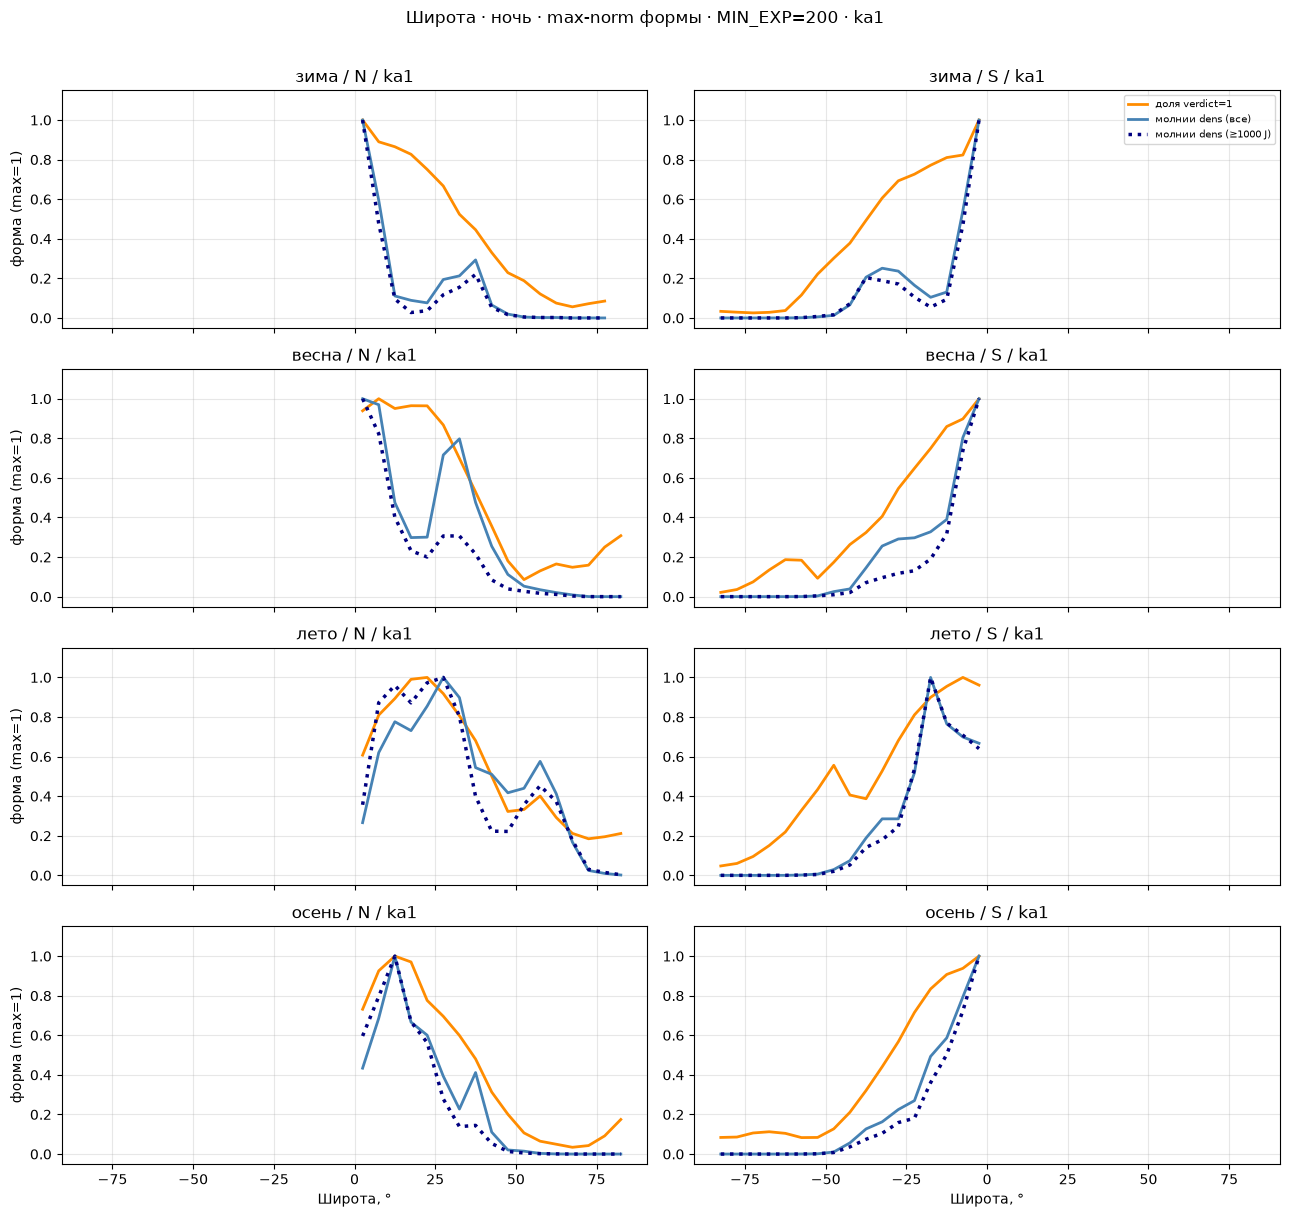

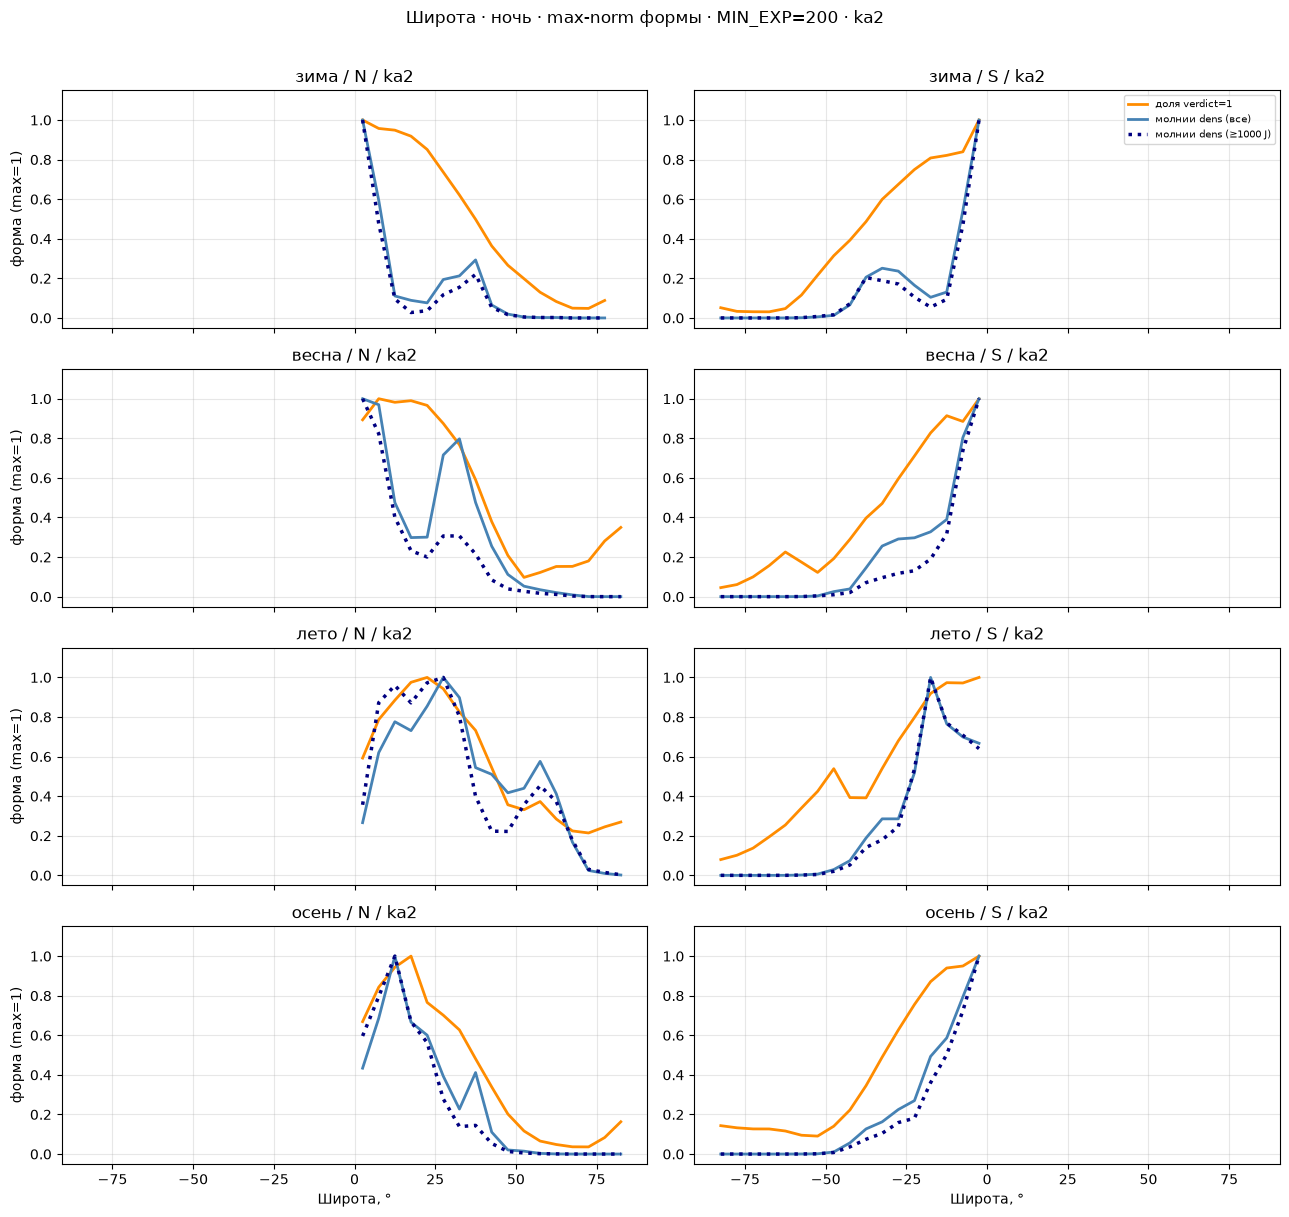

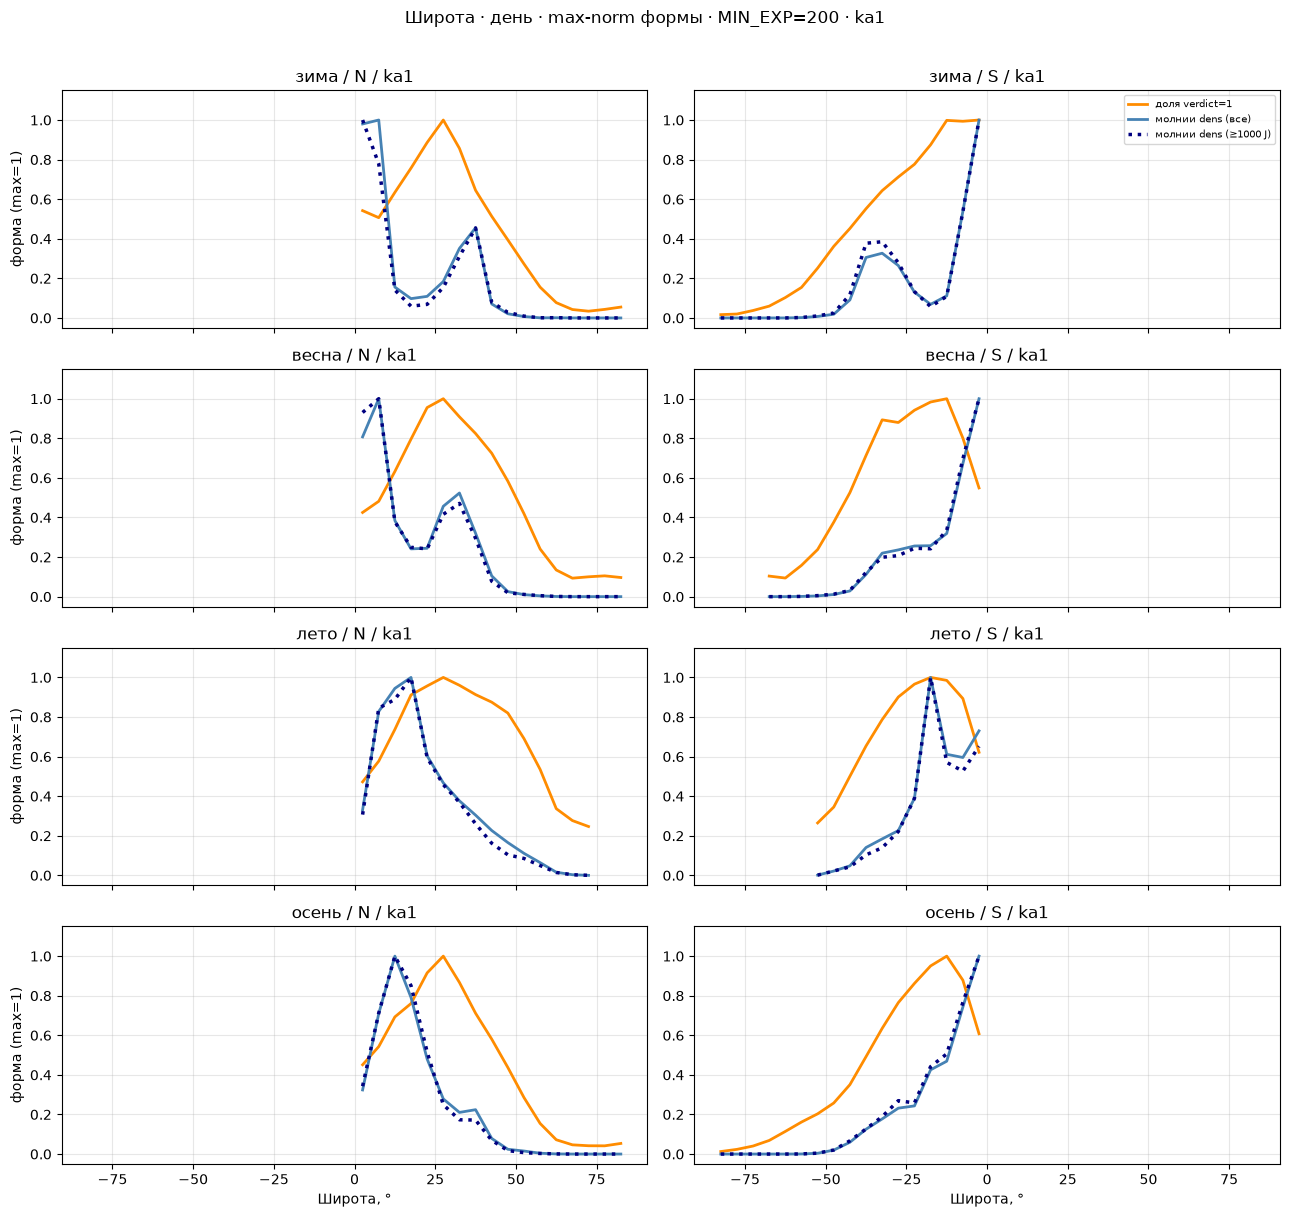

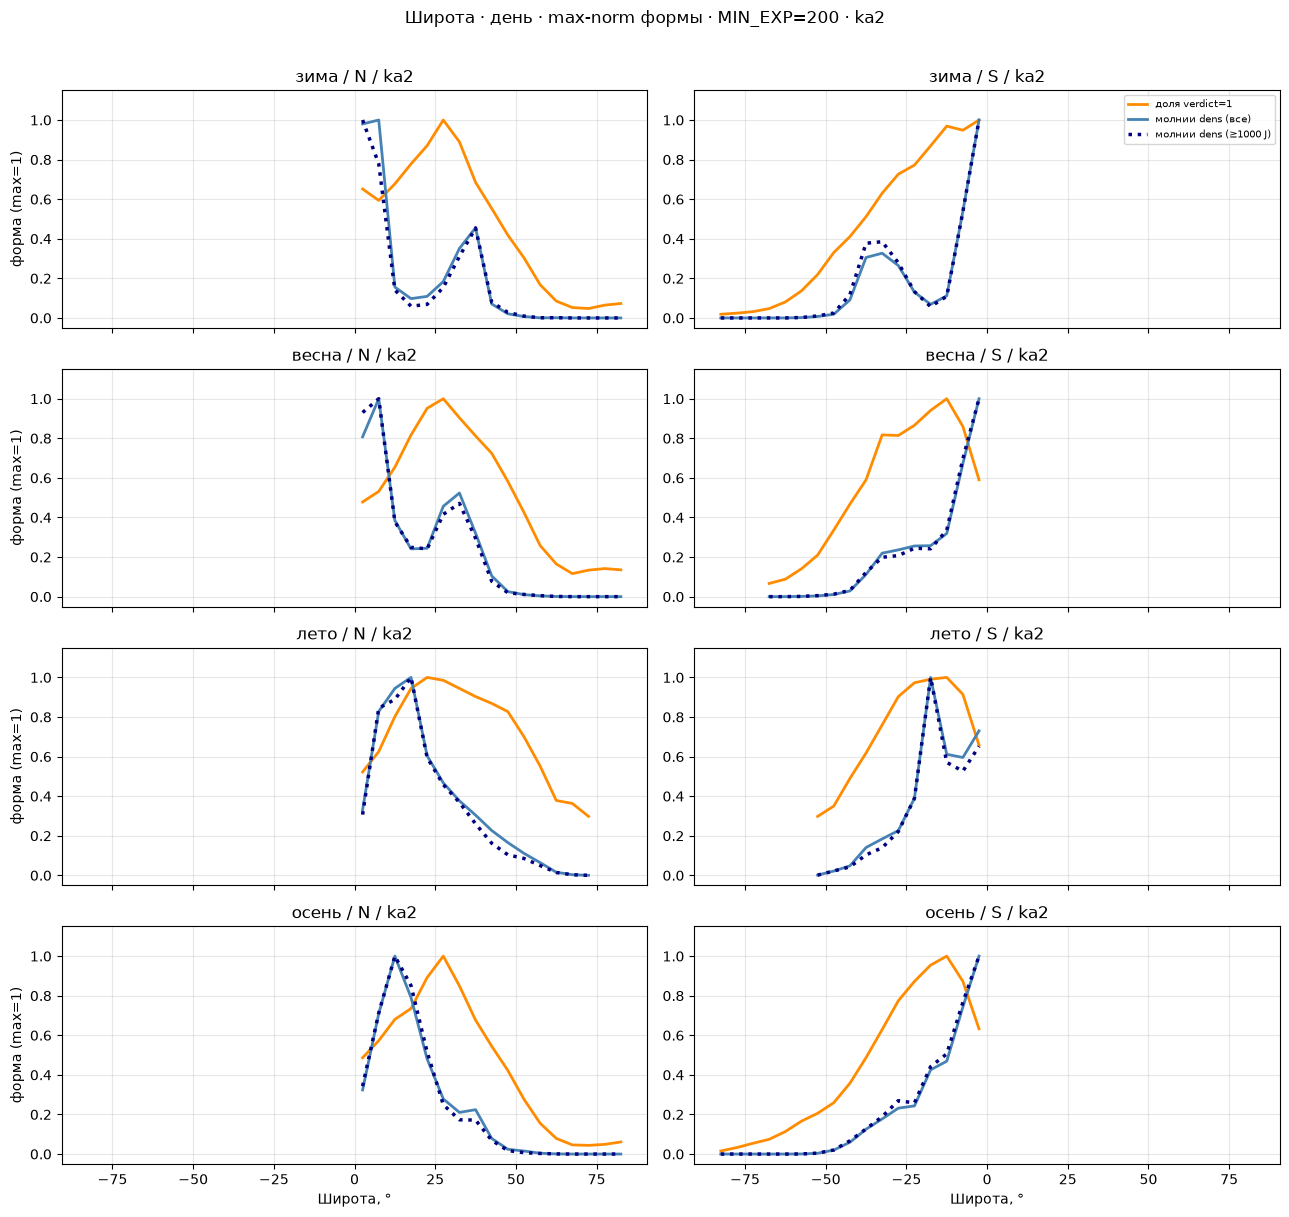

In [114]:
import matplotlib.pyplot as plt

# Широта: отдельные фигуры ночь / день (не мешаем разные режимы на одной оси).
# В панели: доля (maxn) + плотность молний all / ≥E (maxn) — только форма.

for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in SC_LIST_CMP:
        si = sc_to_i[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lat[si, hi, sei, night_i]
                rate = _rate_masked(pos_lat[si, hi, sei, night_i], exp)
                dens0 = _dens_masked(flash_lat[0, si, hi, sei, night_i], lat_area, exp)
                dens1 = _dens_masked(flash_lat[1, si, hi, sei, night_i], lat_area, exp)

                ln1, = ax.plot(lat_centers, _maxn(rate), color='darkorange', lw=2, label='доля verdict=1')
                ln2, = ax.plot(lat_centers, _maxn(dens0), color='steelblue', lw=2, label='молнии dens (все)')
                ln3, = ax.plot(
                    lat_centers, _maxn(dens1), color='navy', ls=':', lw=2.5,
                    label=f'молнии dens (≥{ENERGY_MIN_J:g} J)',
                )
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2, ln3], [l.get_label() for l in (ln1, ln2, ln3)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Широта, °')
        fig.suptitle(
            f'Широта · {night_lab} · max-norm формы · MIN_EXP={MIN_EXP} · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


#### ka4 — широта

Форма доли свистов и форма плотности молний вдоль широты. Ночь и день отдельными фигурами.


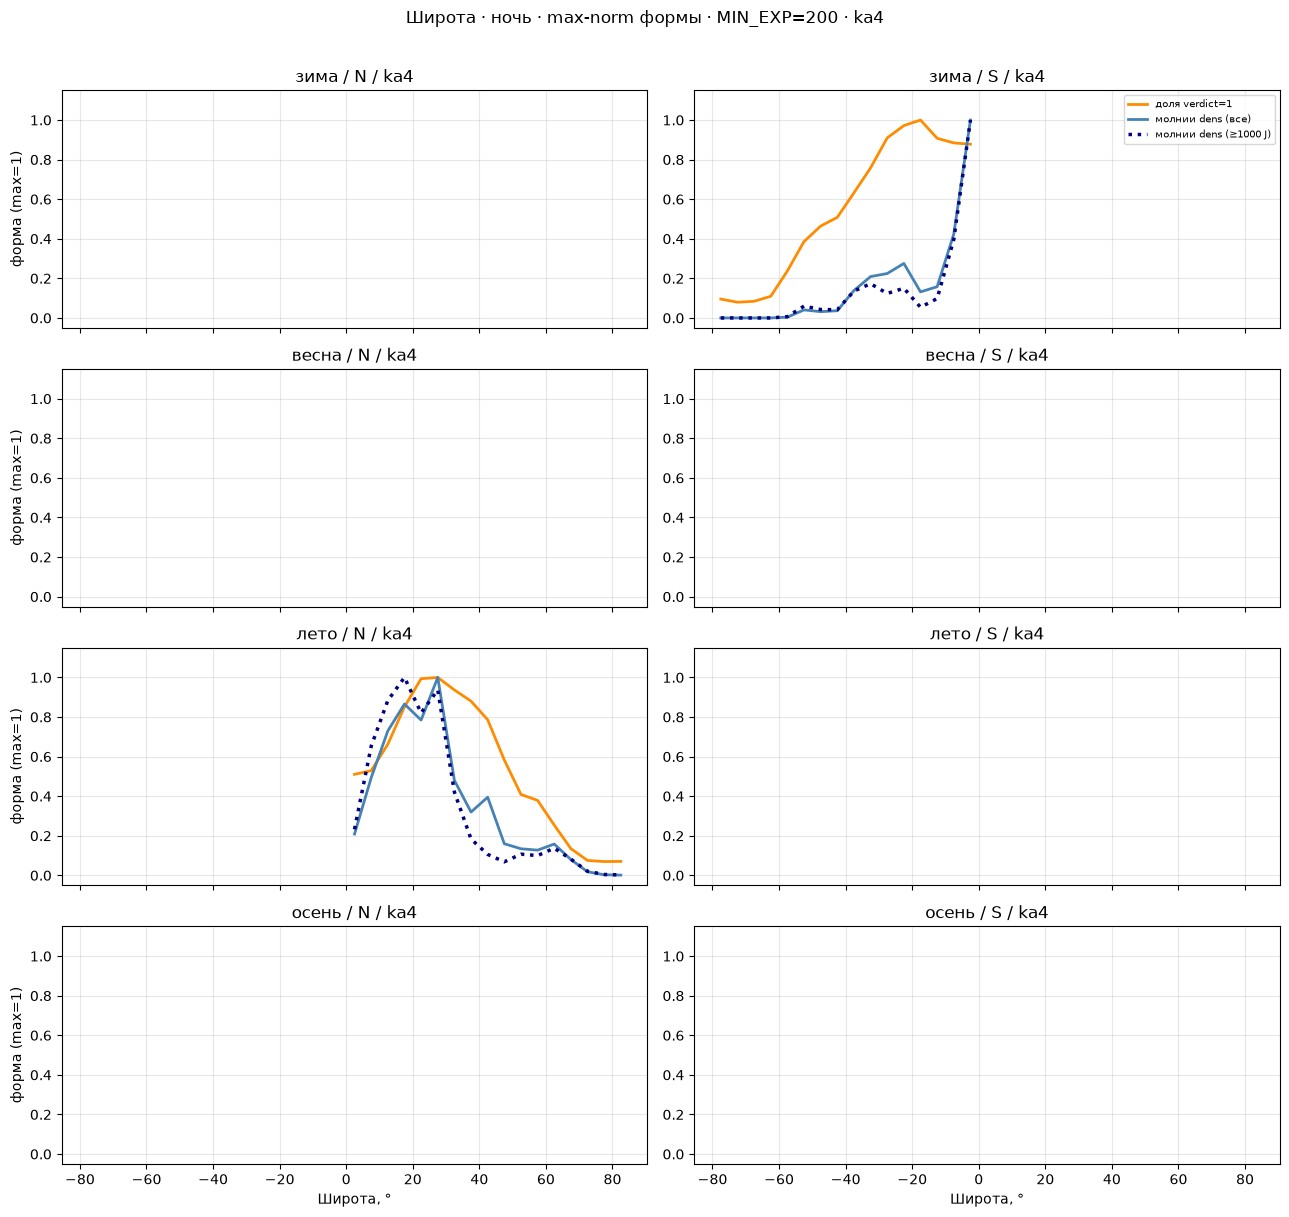

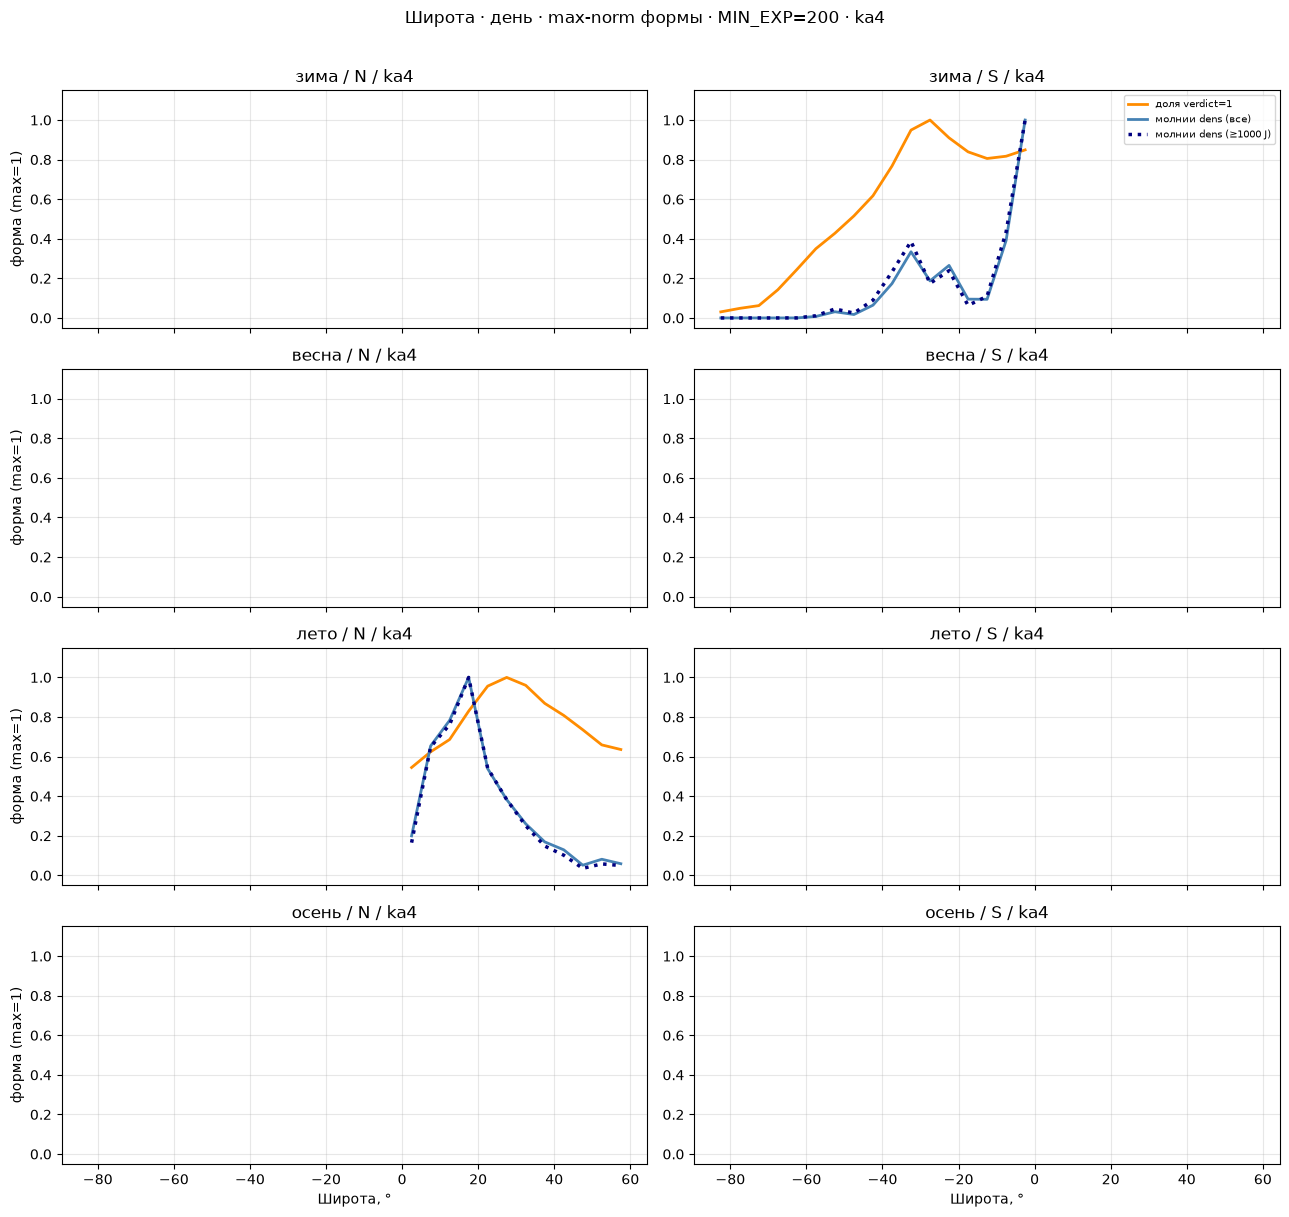

In [13]:
import matplotlib.pyplot as plt

# Широта: отдельные фигуры ночь / день (не мешаем разные режимы на одной оси).
# В панели: доля (maxn) + плотность молний all / ≥E (maxn) — только форма.

for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in SC_LIST_CMP_KA4:
        si = sc_to_i_ka4[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lat_ka4[si, hi, sei, night_i]
                rate = _rate_masked(pos_lat_ka4[si, hi, sei, night_i], exp)
                dens0 = _dens_masked(flash_lat_ka4[0, si, hi, sei, night_i], lat_area, exp)
                dens1 = _dens_masked(flash_lat_ka4[1, si, hi, sei, night_i], lat_area, exp)

                ln1, = ax.plot(lat_centers, _maxn(rate), color='darkorange', lw=2, label='доля verdict=1')
                ln2, = ax.plot(lat_centers, _maxn(dens0), color='steelblue', lw=2, label='молнии dens (все)')
                ln3, = ax.plot(
                    lat_centers, _maxn(dens1), color='navy', ls=':', lw=2.5,
                    label=f'молнии dens (≥{ENERGY_MIN_J:g} J)',
                )
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2, ln3], [l.get_label() for l in (ln1, ln2, ln3)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Широта, °')
        fig.suptitle(
            f'Широта · {night_lab} · max-norm формы · MIN_EXP={MIN_EXP} · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


#### Долгота, ka1 и ka2

То же сравнение формы вдоль долготы. Молнии взяты из широт, где у аппарата есть экспозиция.


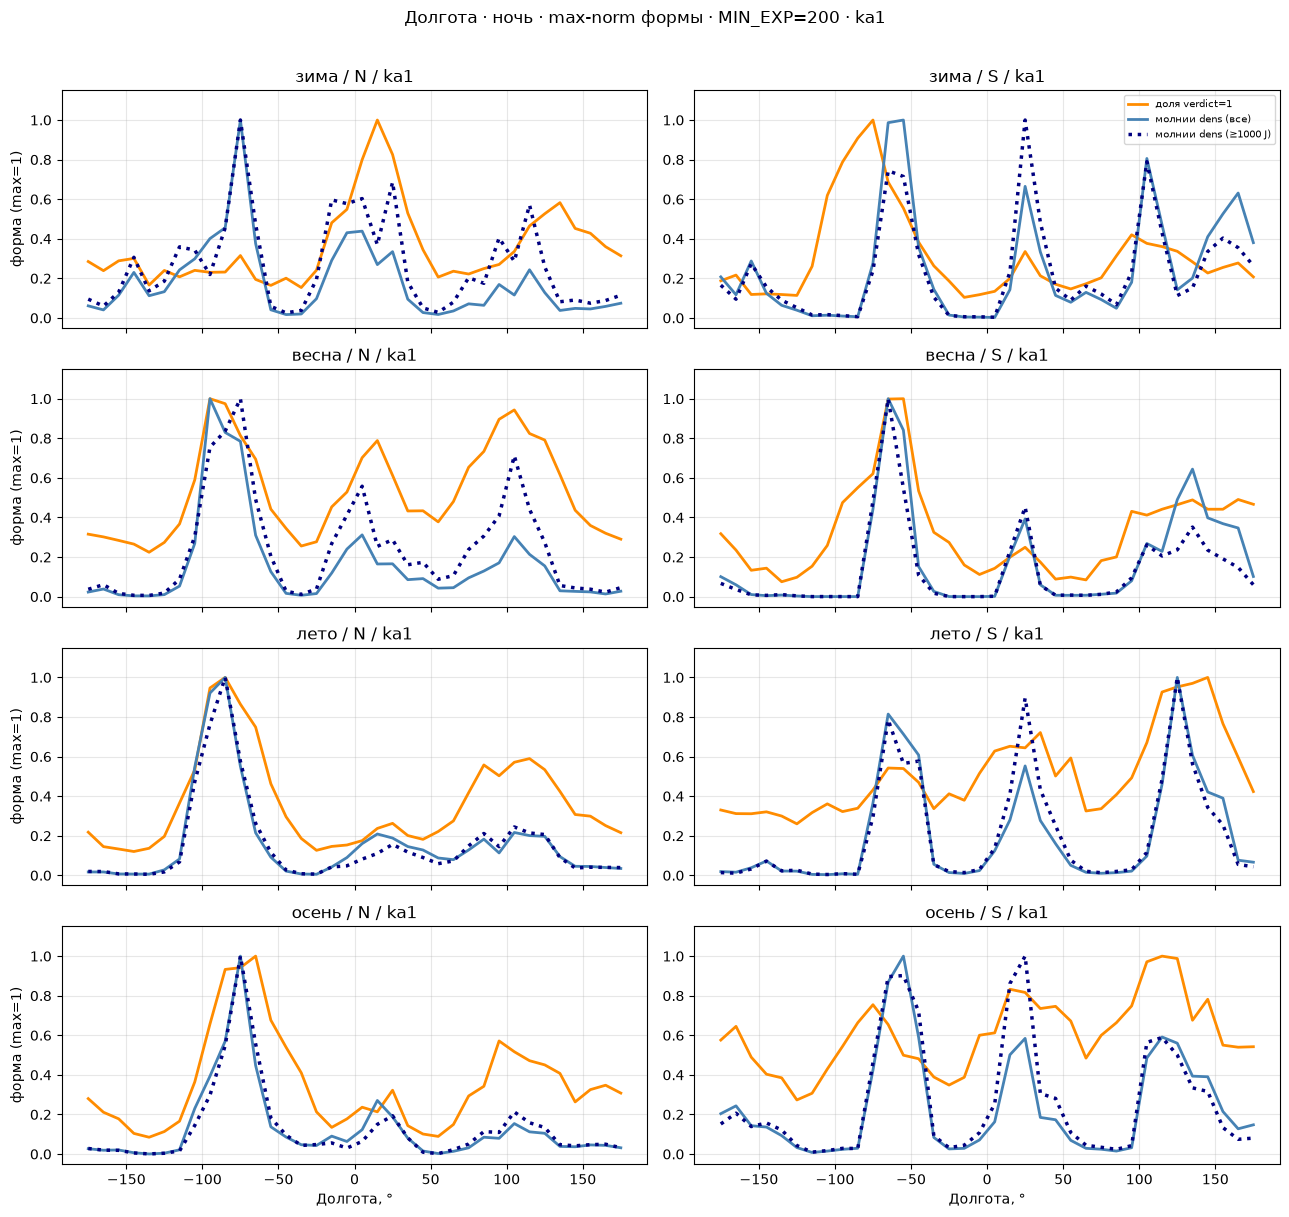

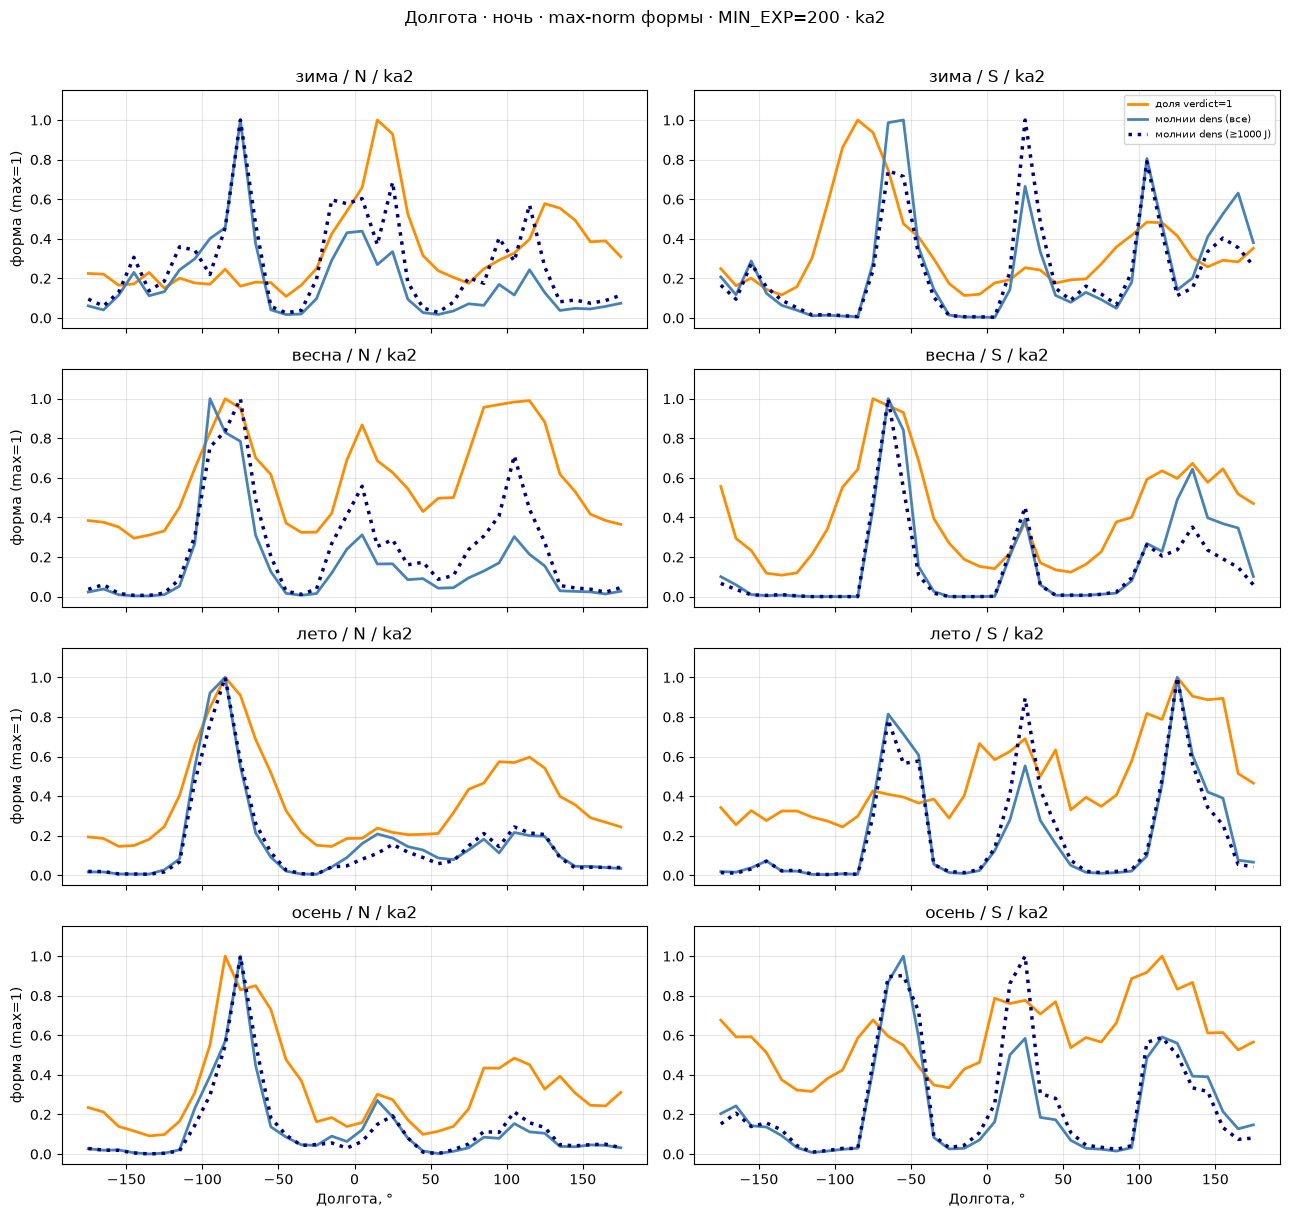

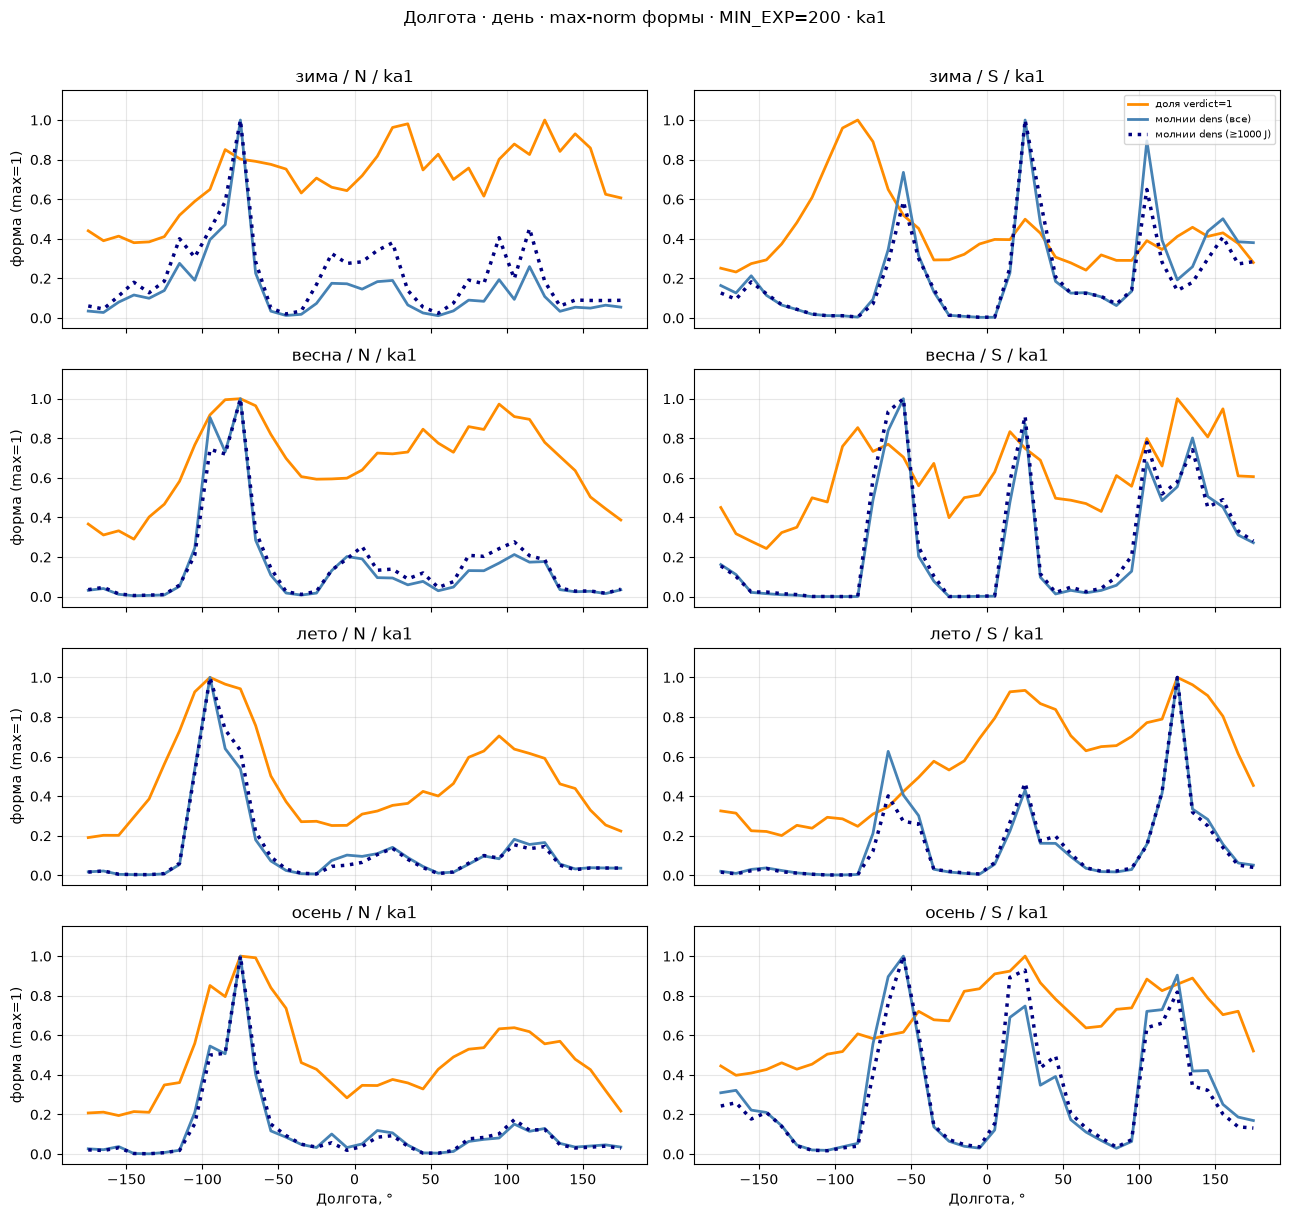

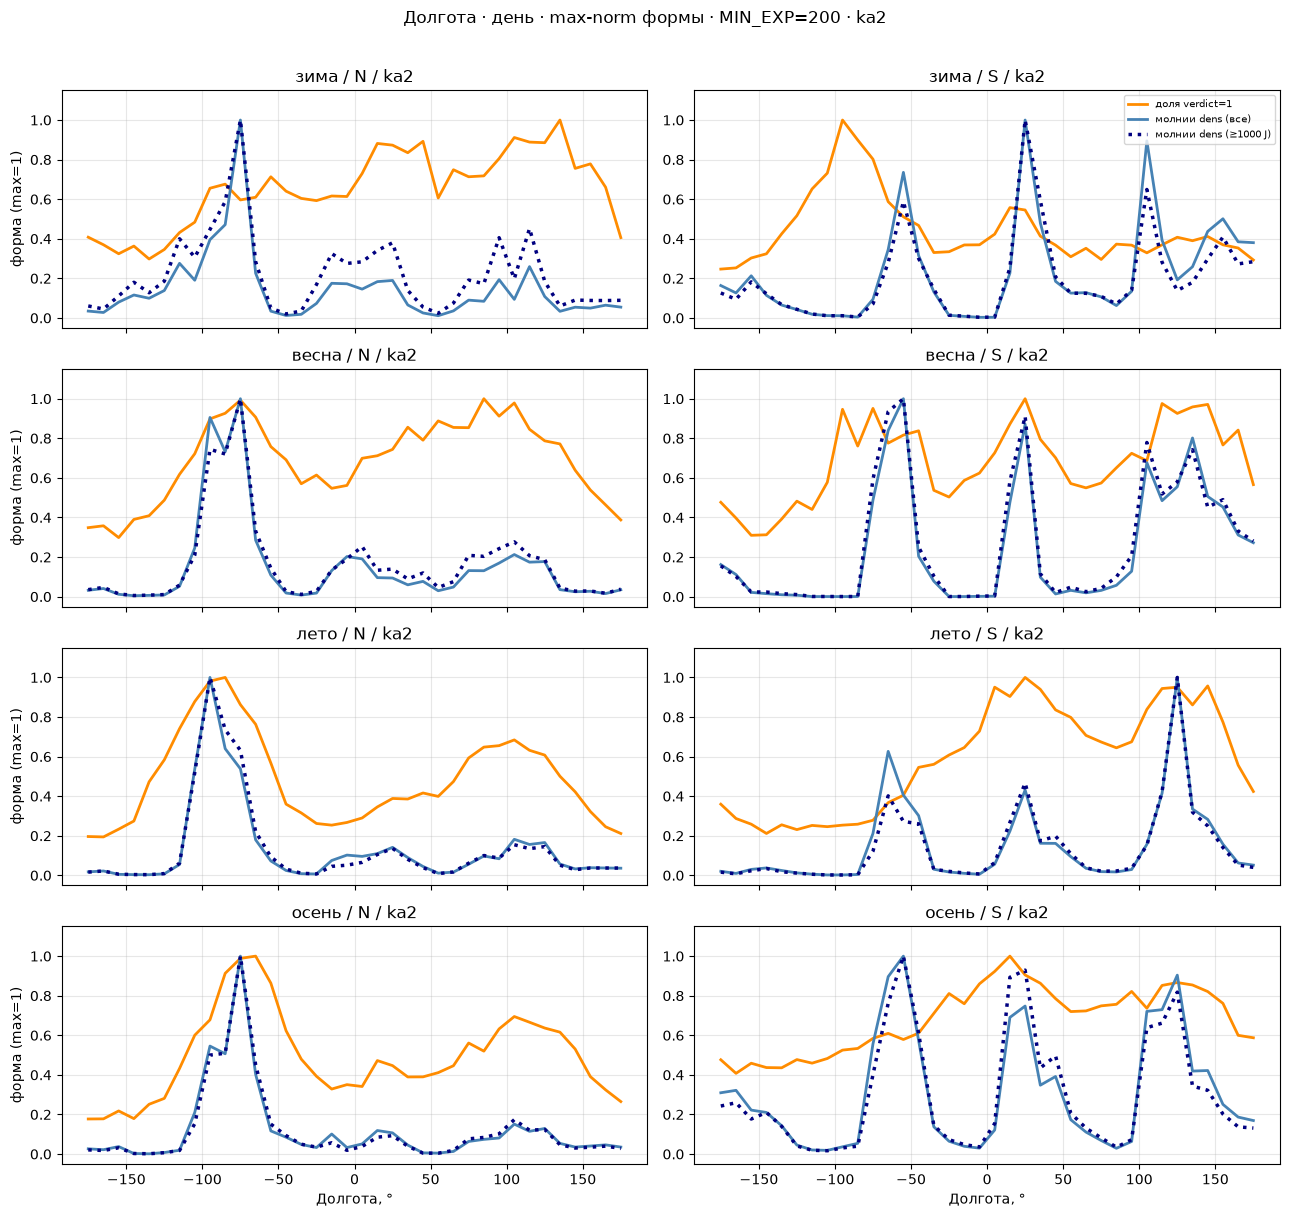

In [115]:
import matplotlib.pyplot as plt

# Долгота: ночь/день отдельно; молнии уже ограничены lat-бинами с экспозицией
for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in SC_LIST_CMP:
        si = sc_to_i[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lon[si, hi, sei, night_i]
                rate = _rate_masked(pos_lon[si, hi, sei, night_i], exp)
                dens0 = _dens_masked(flash_lon[0, si, hi, sei, night_i], lon_width, exp)
                dens1 = _dens_masked(flash_lon[1, si, hi, sei, night_i], lon_width, exp)

                ln1, = ax.plot(lon_centers, _maxn(rate), color='darkorange', lw=2, label='доля verdict=1')
                ln2, = ax.plot(lon_centers, _maxn(dens0), color='steelblue', lw=2, label='молнии dens (все)')
                ln3, = ax.plot(
                    lon_centers, _maxn(dens1), color='navy', ls=':', lw=2.5,
                    label=f'молнии dens (≥{ENERGY_MIN_J:g} J)',
                )
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2, ln3], [l.get_label() for l in (ln1, ln2, ln3)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Долгота, °')
        fig.suptitle(
            f'Долгота · {night_lab} · max-norm формы · MIN_EXP={MIN_EXP} · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


#### ka4 — долгота

То же сравнение формы вдоль долготы.


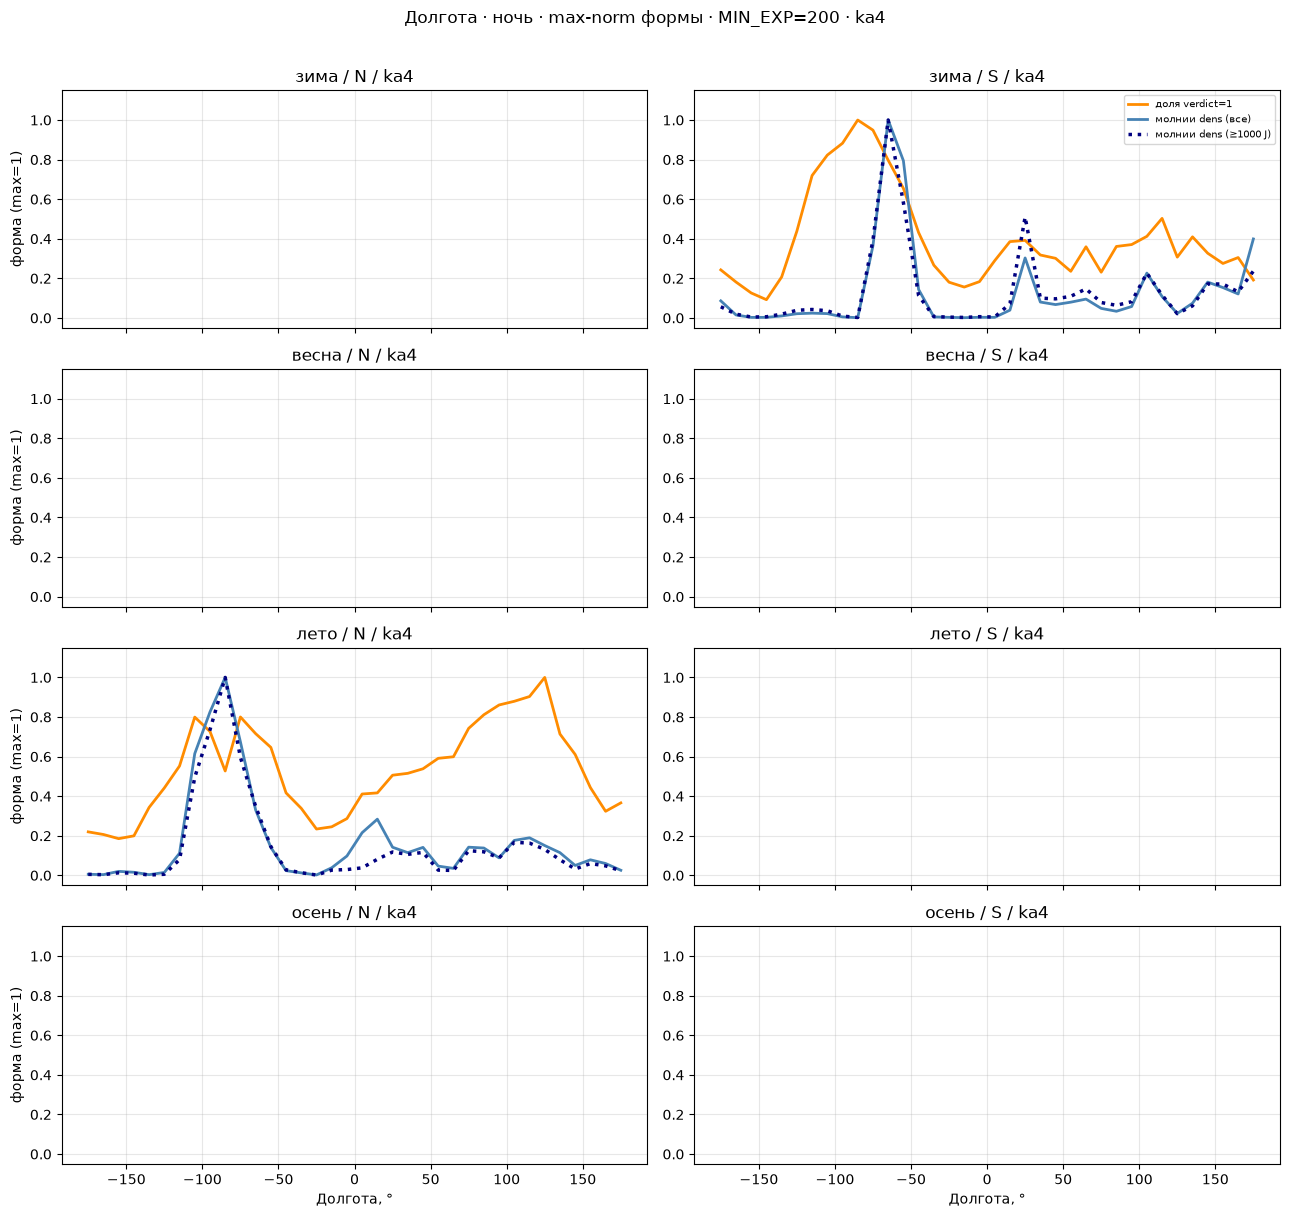

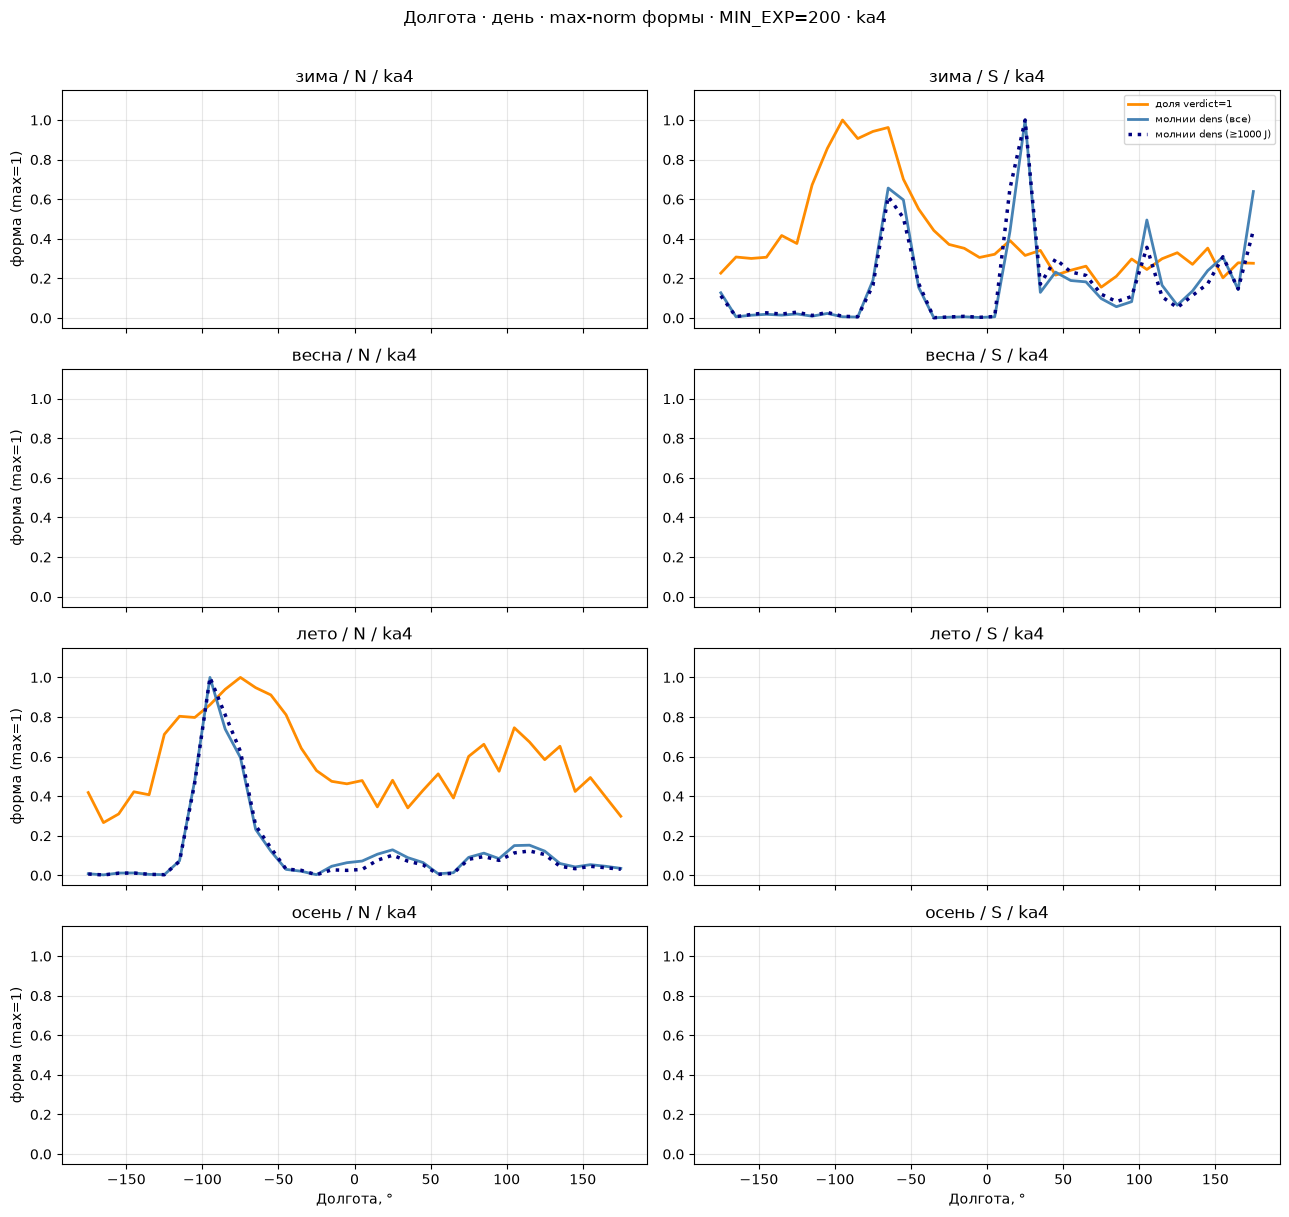

In [14]:
import matplotlib.pyplot as plt

# Долгота: ночь/день отдельно; молнии уже ограничены lat-бинами с экспозицией
for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in SC_LIST_CMP_KA4:
        si = sc_to_i_ka4[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lon_ka4[si, hi, sei, night_i]
                rate = _rate_masked(pos_lon_ka4[si, hi, sei, night_i], exp)
                dens0 = _dens_masked(flash_lon_ka4[0, si, hi, sei, night_i], lon_width, exp)
                dens1 = _dens_masked(flash_lon_ka4[1, si, hi, sei, night_i], lon_width, exp)

                ln1, = ax.plot(lon_centers, _maxn(rate), color='darkorange', lw=2, label='доля verdict=1')
                ln2, = ax.plot(lon_centers, _maxn(dens0), color='steelblue', lw=2, label='молнии dens (все)')
                ln3, = ax.plot(
                    lon_centers, _maxn(dens1), color='navy', ls=':', lw=2.5,
                    label=f'молнии dens (≥{ENERGY_MIN_J:g} J)',
                )
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2, ln3], [l.get_label() for l in (ln1, ln2, ln3)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Долгота, °')
        fig.suptitle(
            f'Долгота · {night_lab} · max-norm формы · MIN_EXP={MIN_EXP} · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


## Что стоит за одной точкой широтного графика

Четыре квадрата 2°×2° с разным уровнем гроз в марте: умеренно (4…6°N, 110…112°E), почти без молний (59…61°N, 44…46°E), очень много (12…14°S, 128…130°E) и максимум марта у побережья Колумбии (4…6°N, 78…76°W). Для каждого — почасовой ход молний и доля `verdict=1` у ka1 за март 2025. Точка доли есть только в те часы, когда спутник реально был в этом квадрате.

Так видно разницу покрытия: молнии в бине есть круглые сутки, спутник за месяц проходит квадрат отдельными часами.


ka1: 31 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka1
AE из кэша: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet


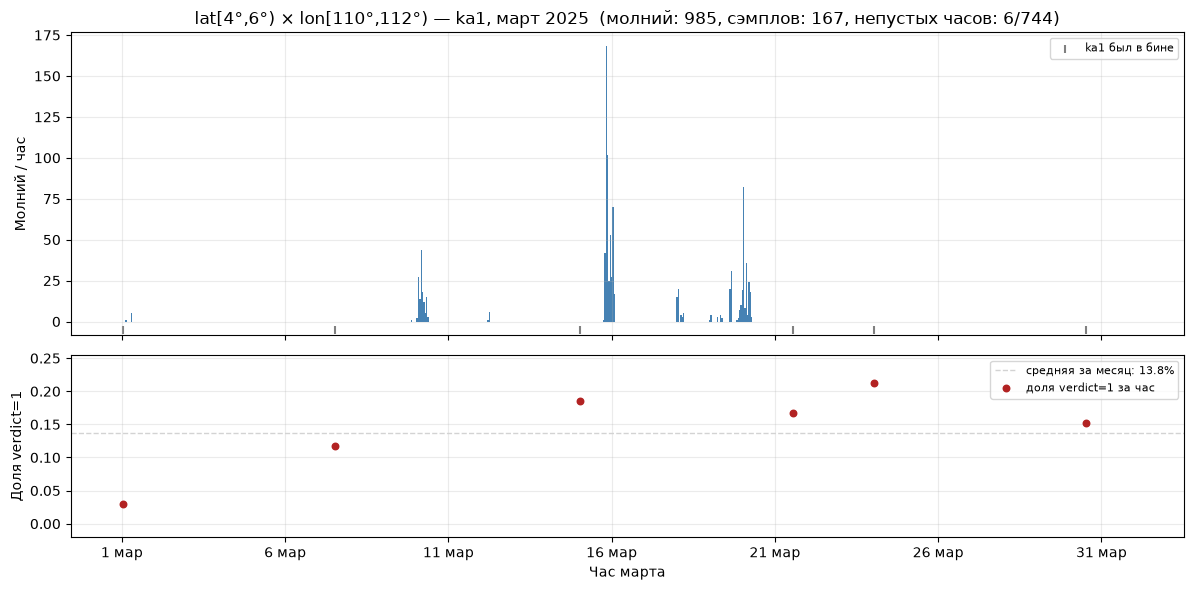

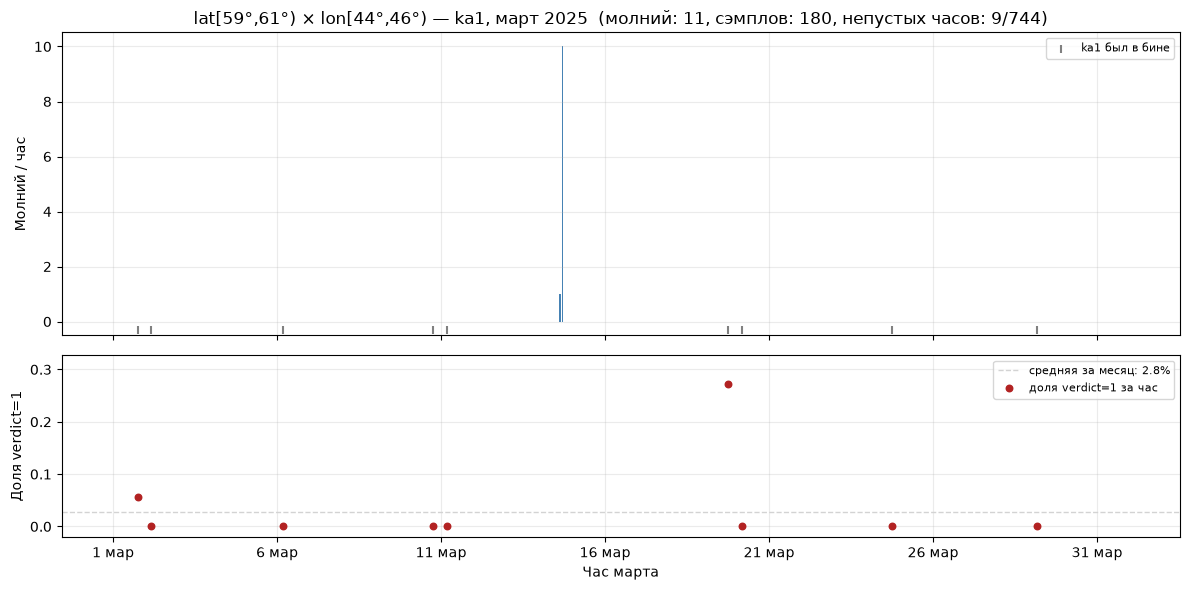

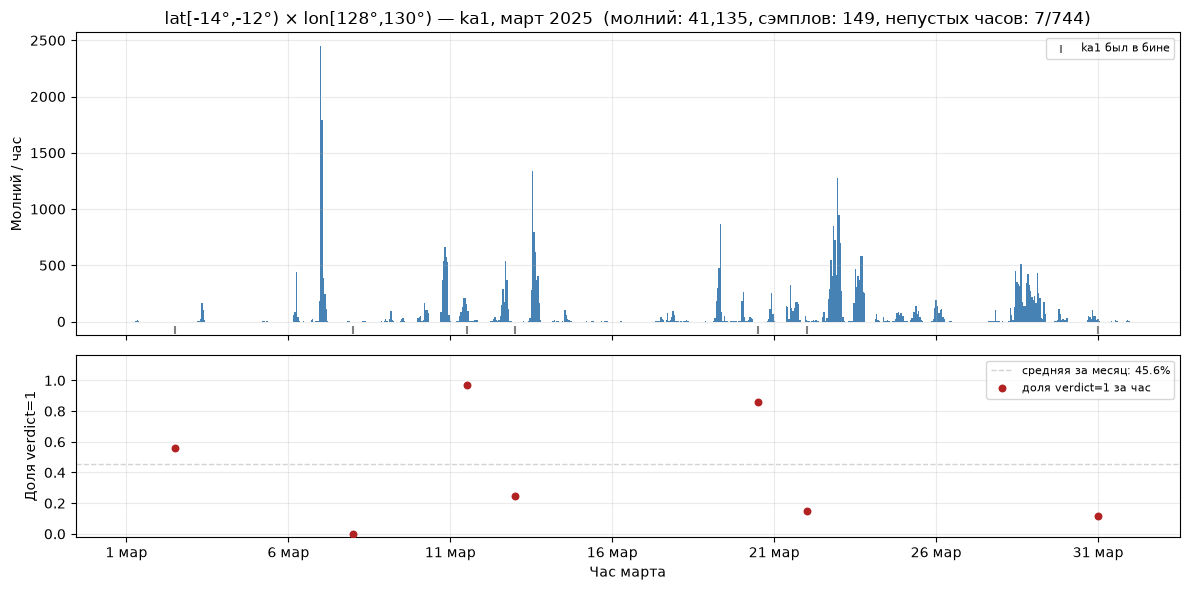

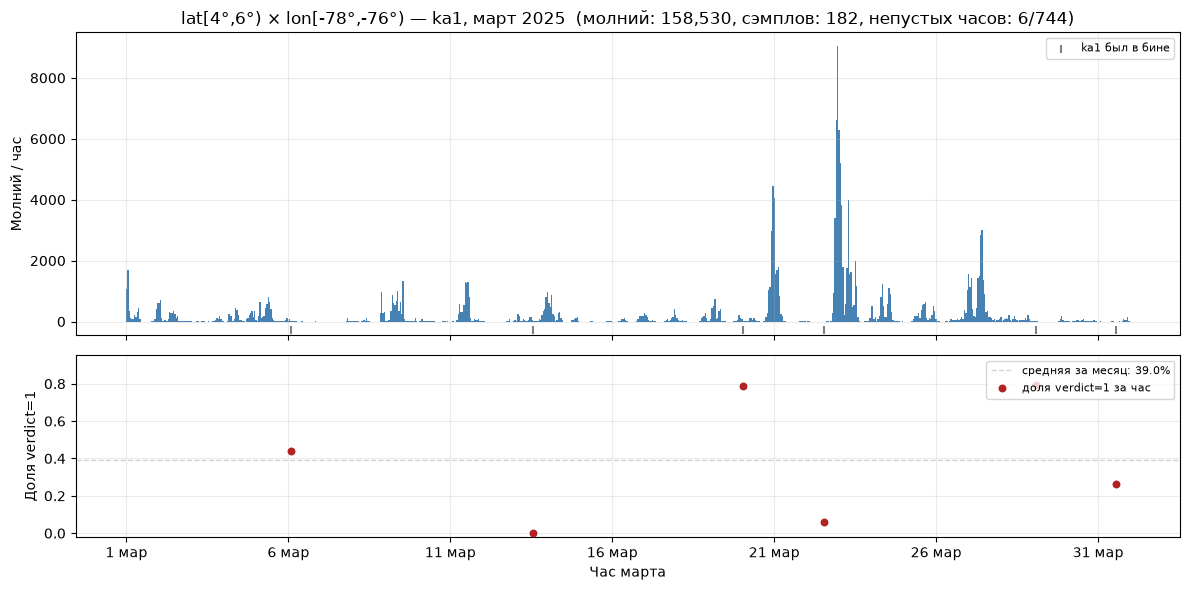

In [3]:
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
importlib.reload(wc)

# === Молнии и доля verdict=1 по часам месяца для конкретного бина широта×долгота ===
# Иллюстрация того, что реально стоит за одной точкой на графике "по широте":
# спутник в конкретном 2°×2° бине присутствует лишь единичные часы за весь месяц,
# а не непрерывно (в отличие от молний, которые считаются круглосуточно).

HOURLY_SC = 'ka1'
HOURLY_MONTH_START = pd.Timestamp('2025-03-01')
HOURLY_N_HOURS = 31 * 24  # март

_paths_h = wc.resolve_paths()
_hourly_days = [d for d in wc.analysis_days(_paths_h['pred'], _paths_h['ae'], (HOURLY_SC,))
                if d.startswith('202503')]
# отдельные переменные (не df/df_pred) — чтобы не зависеть от того, что осталось
# в ядре после блока ka4 выше
df_pred_hourly = wc.load_predictions(_paths_h['pred'], sc_list=(HOURLY_SC,), days=_hourly_days)
df_ae_hourly = wc.load_ae(ae_dir=_paths_h['ae'],
                           cache_path=_paths_h['cache'] / 'AE_20250101_20251231.parquet',
                           days=_hourly_days)


def hourly_bin_arrays(lat_lo, lat_hi, lon_lo, lon_hi):
    cell_pred = df_pred_hourly[
        (df_pred_hourly['geo_lat'] >= lat_lo) & (df_pred_hourly['geo_lat'] < lat_hi) &
        (df_pred_hourly['geo_lon'] >= lon_lo) & (df_pred_hourly['geo_lon'] < lon_hi)
    ]
    cell_ae = df_ae_hourly[
        (df_ae_hourly['lat'] >= lat_lo) & (df_ae_hourly['lat'] < lat_hi) &
        (df_ae_hourly['lon'] >= lon_lo) & (df_ae_hourly['lon'] < lon_hi)
    ]
    h_pred = ((cell_pred['timestamp'] - HOURLY_MONTH_START) // pd.Timedelta(hours=1)).to_numpy()
    h_ae = ((cell_ae['datetime'] - HOURLY_MONTH_START) // pd.Timedelta(hours=1)).to_numpy()
    ok_pred = (h_pred >= 0) & (h_pred < HOURLY_N_HOURS)
    ok_ae = (h_ae >= 0) & (h_ae < HOURLY_N_HOURS)
    h_pred, verdict = h_pred[ok_pred], cell_pred['verdict'].to_numpy()[ok_pred]
    h_ae = h_ae[ok_ae]

    light_hourly = np.bincount(h_ae, minlength=HOURLY_N_HOURS)
    sc_n_hourly = np.bincount(h_pred, minlength=HOURLY_N_HOURS)
    sc_v1_hourly = np.bincount(h_pred[verdict == 1], minlength=HOURLY_N_HOURS)
    return light_hourly, sc_n_hourly, sc_v1_hourly


def plot_lat_lon_hourly(lat_lo, lat_hi, lon_lo, lon_hi, sc=HOURLY_SC):
    light_hourly, sc_n_hourly, sc_v1_hourly = hourly_bin_arrays(lat_lo, lat_hi, lon_lo, lon_hi)
    hours = np.arange(HOURLY_N_HOURS)
    nonempty = np.where(sc_n_hourly > 0)[0]
    rate = np.divide(sc_v1_hourly[nonempty], sc_n_hourly[nonempty])
    avg_rate = sc_v1_hourly.sum() / max(sc_n_hourly.sum(), 1)

    # два разных по масштабу графика — общий X, разные Y (не twin-axis)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                                    gridspec_kw={'height_ratios': [2, 1.2]})
    ax1.bar(hours, light_hourly, width=1.0, color='steelblue', linewidth=0)
    ax1.set_ylabel('Молний / час')
    ax1.set_title(
        f'lat[{lat_lo}°,{lat_hi}°) × lon[{lon_lo}°,{lon_hi}°) — {sc}, март 2025  '
        f'(молний: {light_hourly.sum():,}, сэмплов: {sc_n_hourly.sum():,}, '
        f'непустых часов: {len(nonempty)}/{HOURLY_N_HOURS})'
    )
    ymax = light_hourly.max() if light_hourly.max() > 0 else 1
    ax1.scatter(nonempty, np.full(len(nonempty), -0.03 * ymax), marker='|', color='gray',
                s=40, clip_on=False, label=f'{sc} был в бине')
    ax1.set_ylim(bottom=-0.05 * ymax)
    ax1.legend(loc='upper right', fontsize=8)

    ax2.axhline(avg_rate, color='lightgray', linestyle='--', linewidth=1,
                label=f'средняя за месяц: {avg_rate:.1%}')
    ax2.scatter(nonempty, rate, color='firebrick', s=22, zorder=3, label='доля verdict=1 за час')
    ax2.set_ylabel('Доля verdict=1')
    ax2.set_xlabel('Час марта')
    ax2.set_ylim(-0.02, max(rate.max() if len(rate) else 0.1, avg_rate) * 1.2)
    ax2.legend(loc='upper right', fontsize=8)

    xt = np.arange(0, HOURLY_N_HOURS, 5 * 24)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f'{d + 1} мар' for d in xt // 24])
    for ax in (ax1, ax2):
        ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


# три максимально разных бина 2°×2°:
plot_lat_lon_hourly(4, 6, 110, 112)       # тропики N (Азия/Тихий океан) — умеренно много молний
plot_lat_lon_hourly(59, 61, 44, 46)       # высокие широты — молний почти нет (11 за месяц)
plot_lat_lon_hourly(-14, -12, 128, 130)   # тропики S, летний сезон юж. полушария — очень много молний

plot_lat_lon_hourly(4, 6, -78, -76)      # тропики S.America (побережье Колумбии) — абсолютный максимум молний за март


## Долгота при фиксированных сутках и широтной полосе

Та же идея, ось X — долгота. Фиксируется полоса широты 2° и конкретные сутки марта. Молнии раскладываются по долготе. Доля `verdict=1` у ka1 ставится только там, где спутник в эти сутки пересёк полосу: за день таких коротких пересечений несколько, на разных долготах.


ka1: 31 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka1
AE из кэша: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet


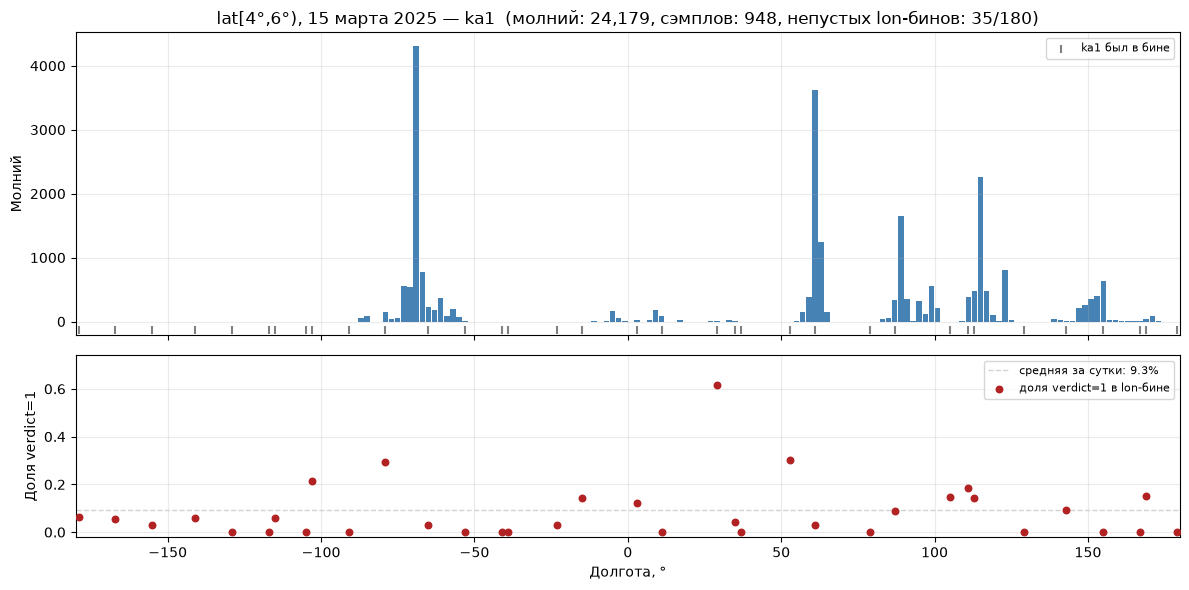

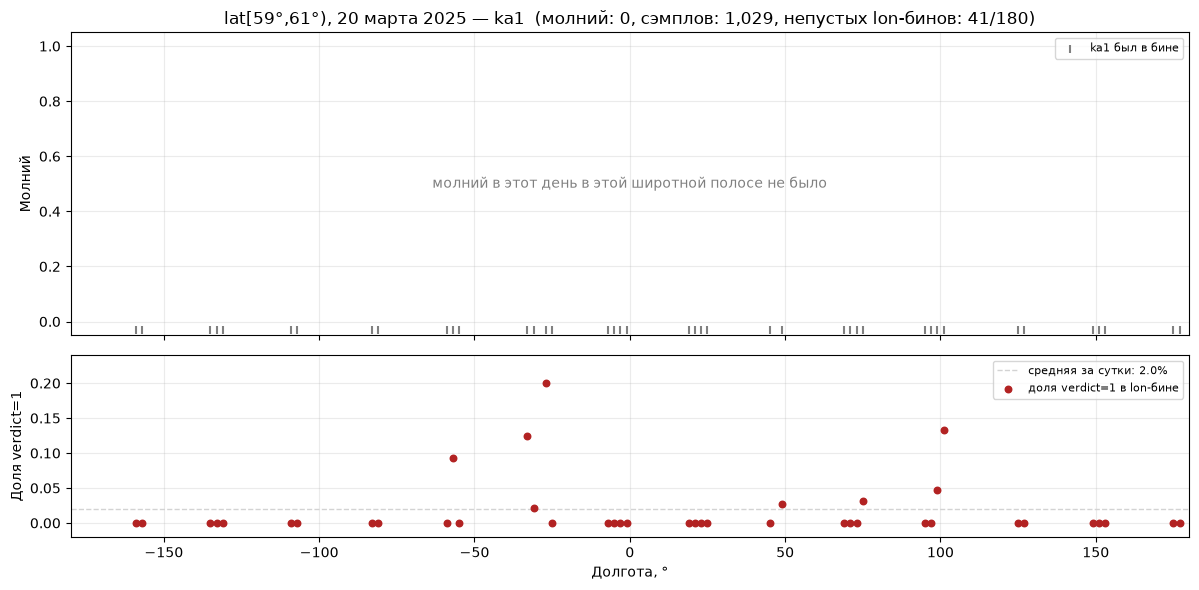

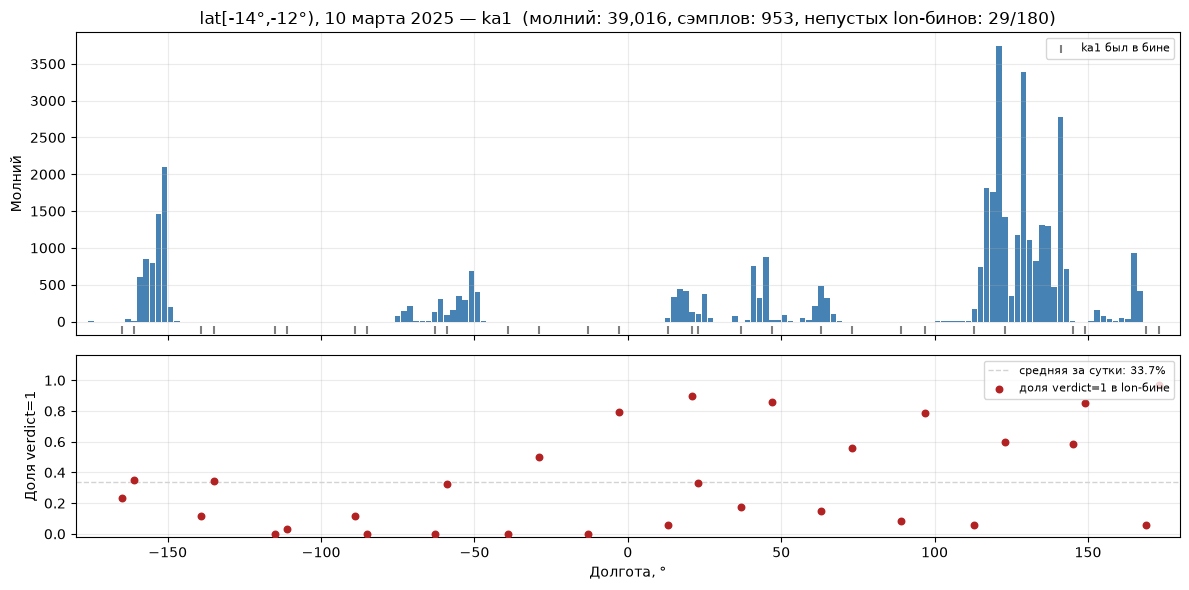

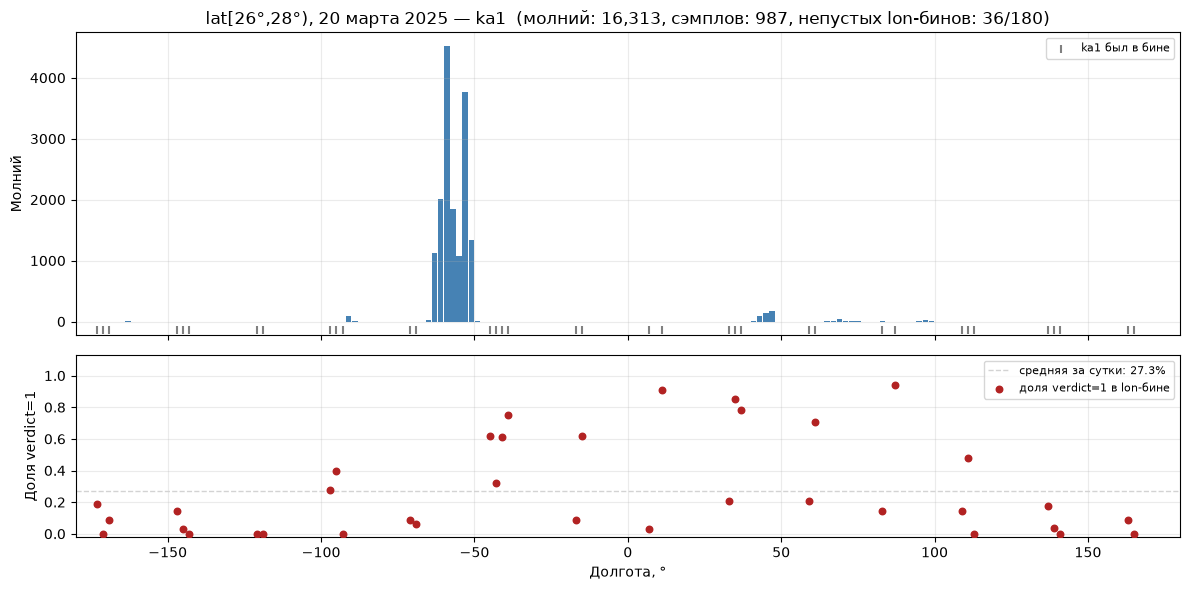

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wwlln_common as wc
import importlib
importlib.reload(wc)

LONDAY_SC = 'ka1'
LONDAY_MONTH_START = pd.Timestamp('2025-03-01')

_paths_ld = wc.resolve_paths()
_londay_days = [d for d in wc.analysis_days(_paths_ld['pred'], _paths_ld['ae'], (LONDAY_SC,))
                if d.startswith('202503')]
df_pred_londay = wc.load_predictions(_paths_ld['pred'], sc_list=(LONDAY_SC,), days=_londay_days)
df_ae_londay = wc.load_ae(ae_dir=_paths_ld['ae'],
                           cache_path=_paths_ld['cache'] / 'AE_20250101_20251231.parquet',
                           days=_londay_days)

LON_EDGES = np.arange(-180, 181, 2)
N_LON = len(LON_EDGES) - 1


def lon_bin_arrays(lat_lo, lat_hi, day):
    day_start = LONDAY_MONTH_START + pd.Timedelta(days=day - 1)
    day_end = day_start + pd.Timedelta(days=1)

    band_pred = df_pred_londay[
        (df_pred_londay['geo_lat'] >= lat_lo) & (df_pred_londay['geo_lat'] < lat_hi) &
        (df_pred_londay['timestamp'] >= day_start) & (df_pred_londay['timestamp'] < day_end)
    ]
    band_ae = df_ae_londay[
        (df_ae_londay['lat'] >= lat_lo) & (df_ae_londay['lat'] < lat_hi) &
        (df_ae_londay['datetime'] >= day_start) & (df_ae_londay['datetime'] < day_end)
    ]

    light_lon, _ = np.histogram(band_ae['lon'], bins=LON_EDGES)
    sc_n_lon, _ = np.histogram(band_pred['geo_lon'], bins=LON_EDGES)
    v1_lon, _ = np.histogram(band_pred.loc[band_pred['verdict'] == 1, 'geo_lon'], bins=LON_EDGES)
    return light_lon, sc_n_lon, v1_lon


def plot_lat_day_lon(lat_lo, lat_hi, day, sc=LONDAY_SC):
    light_lon, sc_n_lon, sc_v1_lon = lon_bin_arrays(lat_lo, lat_hi, day)
    lon_centers = (LON_EDGES[:-1] + LON_EDGES[1:]) / 2
    nonempty = np.where(sc_n_lon > 0)[0]
    rate = np.divide(sc_v1_lon[nonempty], sc_n_lon[nonempty])
    avg_rate = sc_v1_lon.sum() / max(sc_n_lon.sum(), 1)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                                    gridspec_kw={'height_ratios': [2, 1.2]})
    ax1.bar(lon_centers, light_lon, width=1.8, color='steelblue', linewidth=0)
    ax1.set_ylabel('Молний')
    ax1.set_title(
        f'lat[{lat_lo}°,{lat_hi}°), {day} марта 2025 — {sc}  '
        f'(молний: {light_lon.sum():,}, сэмплов: {sc_n_lon.sum():,}, '
        f'непустых lon-бинов: {len(nonempty)}/{N_LON})'
    )
    ymax = light_lon.max() if light_lon.max() > 0 else 1
    ax1.scatter(lon_centers[nonempty], np.full(len(nonempty), -0.03 * ymax), marker='|',
                color='gray', s=40, clip_on=False, label=f'{sc} был в бине')
    ax1.set_ylim(-0.05 * ymax, ymax * 1.05)
    if light_lon.max() == 0:
        ax1.text(0.5, 0.5, 'молний в этот день в этой широтной полосе не было',
                  transform=ax1.transAxes, ha='center', va='center', color='gray', fontsize=10)
    ax1.set_xlim(-180, 180)
    ax1.legend(loc='upper right', fontsize=8)

    ax2.axhline(avg_rate, color='lightgray', linestyle='--', linewidth=1,
                label=f'средняя за сутки: {avg_rate:.1%}')
    ax2.scatter(lon_centers[nonempty], rate, color='firebrick', s=22, zorder=3,
                label='доля verdict=1 в lon-бине')
    ax2.set_ylabel('Доля verdict=1')
    ax2.set_xlabel('Долгота, °')
    ax2.set_ylim(-0.02, max(rate.max() if len(rate) else 0.1, avg_rate) * 1.2)
    ax2.set_xlim(-180, 180)
    ax2.legend(loc='upper right', fontsize=8)
    for ax in (ax1, ax2):
        ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()
    plt.close(fig)



plot_lat_day_lon(4, 6, 15)  # 4-6°N, 15 марта 2025
plot_lat_day_lon(59, 61, 20)   # высокие широты — 0 молний в этот день
plot_lat_day_lon(-14, -12, 10) # южные тропики, пик активности
plot_lat_day_lon(26, 28, 20)   # северный вторичный пик широты


## Доза (число молний) от магнитного следа (footprint)

`geo_lat` и `geo_lon` в предсказаниях — точка под спутником. Footprint — куда силовая линия от аппарата приходит в ионосферу. Считается через `mag_coords.footprint_conjugate_arr`, коэффициенты AACGM-v2, высота спутника 827 км, опорная высота 100 км. И доза, и широта, полушарие, сезон и ночь берутся в этой точке, а не под спутником.

Радиус 1500 км, окно 120 с до сэмпла. Период сохранённого прогона — 255 суток, 20.01.2025–31.10.2025. Широта и долгота считаются за один проход. Ниже два рисунка: сначала широта, затем долгота. Ночь и день отдельно, сетка сезон × полушарие, кривые приведены к своему максимуму.


In [6]:
%%time
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
import mag_coords as mc
importlib.reload(wc)
importlib.reload(mc)

# Радиус-доза по footprint: сезон, полушарие, ночь и день, ka1 и ka2.
# Доза и страта сэмпла считаются в одной точке — footprint. Туда силовая линия
# от спутника (SAT_HEIGHT_KM) приходит на опорную высоту TARGET_H_KM = 100 км.
# В dose_pipeline.py это geometry="footprint" и strata_by_geometry=True;
# в wwlln_reader_dose_rt_footprint.ipynb то же называется footprint-согласованными стратами.
#
# footprint_conjugate_arr берёт коэффициенты AACGM-v2 и принимает одну дату на вызов,
# поэтому footprint считается внутри цикла по суткам. По суткам читаются и молнии:
# в память не берётся весь период сразу, от предыдущих суток остаётся хвост
# длиной DOSE_WINDOW_S.
#
# Широта и долгота считаются в одном проходе: одна footprint-точка и один поиск
# молний по радиусу, для долготы только вторая пара бинов.

DOSE_RADIUS_KM = 1500.0
DOSE_WINDOW_S = 120
DOSE_SC_LIST = ('ka1', 'ka2')
DOSE_SUBSAMPLE_STEP = 15
R_EARTH_KM = 6371.0
NIGHT_SZA_DEG_D = wc.NIGHT_SZA_DEG
SAT_HEIGHT_KM = 827.0
TARGET_H_KM = 100.0

_paths_fp = wc.resolve_paths()
CMP_DAYS_FP = wc.analysis_days(_paths_fp['pred'], _paths_fp['ae'], DOSE_SC_LIST)
print(f'период: {len(CMP_DAYS_FP)} суток ({CMP_DAYS_FP[0]} … {CMP_DAYS_FP[-1]})')

df_pred_fp = wc.load_predictions(_paths_fp['pred'], sc_list=DOSE_SC_LIST, days=CMP_DAYS_FP)
df_pred_fp = df_pred_fp.sort_values('timestamp').reset_index(drop=True)
print(f'сэмплов ka1+ka2: {len(df_pred_fp):,}')

season_order = list(wc.SEASON_ORDER)
season_to_i = dict(wc.SEASON_TO_I)
sc_to_i_fp = {s: i for i, s in enumerate(DOSE_SC_LIST)}
_season_idx = wc.season_index

lat_edges_fp = np.arange(-90, 91, 5)
lat_centers_fp = 0.5 * (lat_edges_fp[:-1] + lat_edges_fp[1:])
n_lat_fp = len(lat_edges_fp) - 1
lon_edges_fp = np.arange(-180, 181, 10)
lon_centers_fp = 0.5 * (lon_edges_fp[:-1] + lon_edges_fp[1:])
n_lon_fp = len(lon_edges_fp) - 1
n_sc_fp, n_hem_fp, n_sea_fp, n_night_fp = len(DOSE_SC_LIST), 2, 4, 2
n_g_fp = n_hem_fp * n_sea_fp * n_night_fp

exp_lat_fp = np.zeros((n_sc_fp, n_hem_fp, n_sea_fp, n_night_fp, n_lat_fp))
pos_lat_fp = np.zeros_like(exp_lat_fp)
dose_sum_lat_fp = np.zeros_like(exp_lat_fp)
dose_n_lat_fp = np.zeros_like(exp_lat_fp)

exp_lon_fp = np.zeros((n_sc_fp, n_hem_fp, n_sea_fp, n_night_fp, n_lon_fp))
pos_lon_fp = np.zeros_like(exp_lon_fp)
dose_sum_lon_fp = np.zeros_like(exp_lon_fp)
dose_n_lon_fp = np.zeros_like(exp_lon_fp)

pred_day_key_fp = df_pred_fp['timestamp'].values.astype('datetime64[D]').astype(np.int64)
prev_tail = None

for day_i, day in enumerate(CMP_DAYS_FP):
    day_code = int(wc.day_codes([day])[0])
    day_mask = pred_day_key_fp == day_code
    if not day_mask.any():
        continue
    day_all = df_pred_fp.loc[day_mask]
    day_date = np.datetime64(day_code, 'D').astype('datetime64[s]').astype(object)

    # --- footprint для ВСЕХ сэмплов суток (дёшево, ~секунды/сутки) ---
    lat_all = day_all['geo_lat'].to_numpy(dtype=np.float64)
    lon_all = day_all['geo_lon'].to_numpy(dtype=np.float64)
    fp_lat_all, fp_lon_all, _, _ = mc.footprint_conjugate_arr(lat_all, lon_all, SAT_HEIGHT_KM, day_date)
    ok_fp = np.isfinite(fp_lat_all) & np.isfinite(fp_lon_all)

    month_all = day_all['timestamp'].dt.month.to_numpy()
    sc_all = day_all['sc'].astype(str).to_numpy()
    ver_all = day_all['verdict'].to_numpy(dtype=np.int8)
    # ночь/день — SZA НАД FOOTPRINT (затенение ионосферы там, где волна входит), не под КА
    sza_all = wc.solar_zenith_deg(day_all['timestamp'].values, fp_lat_all, fp_lon_all)
    night_all = (sza_all > NIGHT_SZA_DEG_D).astype(np.int8)
    hem_all, sea_all = _season_idx(fp_lat_all, month_all)
    lb_all = np.digitize(fp_lat_all, lat_edges_fp) - 1
    lo_all = np.digitize(fp_lon_all, lon_edges_fp) - 1
    # Сэмпл входит и в широтную, и в долготную агрегацию только с валидным бином по обеим осям.
    ok_bin_all = ok_fp & (lb_all >= 0) & (lb_all < n_lat_fp) & (lo_all >= 0) & (lo_all < n_lon_fp)

    for sc in DOSE_SC_LIST:
        si = sc_to_i_fp[sc]
        m = ok_bin_all & (sc_all == sc)
        if not m.any():
            continue
        g = (hem_all[m].astype(np.int64) * n_sea_fp + sea_all[m]) * n_night_fp + night_all[m]
        lb, lo = lb_all[m], lo_all[m]
        hit = ver_all[m] == 1
        exp_lat_fp[si] += np.bincount(g * n_lat_fp + lb, minlength=n_g_fp * n_lat_fp).reshape(
            n_hem_fp, n_sea_fp, n_night_fp, n_lat_fp)
        pos_lat_fp[si] += np.bincount((g * n_lat_fp + lb)[hit], minlength=n_g_fp * n_lat_fp).reshape(
            n_hem_fp, n_sea_fp, n_night_fp, n_lat_fp)
        exp_lon_fp[si] += np.bincount(g * n_lon_fp + lo, minlength=n_g_fp * n_lon_fp).reshape(
            n_hem_fp, n_sea_fp, n_night_fp, n_lon_fp)
        pos_lon_fp[si] += np.bincount((g * n_lon_fp + lo)[hit], minlength=n_g_fp * n_lon_fp).reshape(
            n_hem_fp, n_sea_fp, n_night_fp, n_lon_fp)

    # --- доза: подвыборка, поиск молний вокруг footprint ---
    day_pred = day_all.iloc[::DOSE_SUBSAMPLE_STEP]
    if day_pred.empty:
        continue
    sub_idx = np.arange(0, len(day_all), DOSE_SUBSAMPLE_STEP)
    fp_lat_sub, fp_lon_sub = fp_lat_all[sub_idx], fp_lon_all[sub_idx]
    ok_sub = ok_fp[sub_idx]

    ae_today = wc.read_ae_file(wc.ae_path_for_day(_paths_fp['ae'], day))
    ae_all = pd.concat([prev_tail, ae_today], ignore_index=True) if prev_tail is not None else ae_today
    ae_all = ae_all.sort_values('datetime')
    ae_t = ae_all['datetime'].values.astype('datetime64[s]').astype(np.int64)
    ae_lat_r = np.radians(ae_all['lat'].to_numpy(dtype=np.float64))
    ae_lon_r = np.radians(ae_all['lon'].to_numpy(dtype=np.float64))

    if len(ae_today):
        day_end_t = ae_today['datetime'].max()
        prev_tail = ae_today[ae_today['datetime'] >= day_end_t - pd.Timedelta(seconds=DOSE_WINDOW_S)]

    s_t = day_pred['timestamp'].values.astype('datetime64[s]').astype(np.int64)
    s_lat_r = np.radians(fp_lat_sub)
    s_lon_r = np.radians(fp_lon_sub)

    dose = np.zeros(len(day_pred), dtype=np.int32)
    for k in range(len(day_pred)):
        if not ok_sub[k]:
            continue
        t_hi = s_t[k]
        i_lo = np.searchsorted(ae_t, t_hi - DOSE_WINDOW_S, side='left')
        i_hi = np.searchsorted(ae_t, t_hi, side='right')
        if i_hi <= i_lo:
            continue
        lat2v, lon2v = ae_lat_r[i_lo:i_hi], ae_lon_r[i_lo:i_hi]
        dlat = lat2v - s_lat_r[k]
        dlon = lon2v - s_lon_r[k]
        a = np.sin(dlat / 2) ** 2 + np.cos(s_lat_r[k]) * np.cos(lat2v) * np.sin(dlon / 2) ** 2
        dist = 2 * R_EARTH_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        dose[k] = np.sum(dist <= DOSE_RADIUS_KM)

    sc_sub = day_pred['sc'].astype(str).to_numpy()
    hem_sub, sea_sub = hem_all[sub_idx], sea_all[sub_idx]
    night_sub, lb_sub, lo_sub = night_all[sub_idx], lb_all[sub_idx], lo_all[sub_idx]
    ok_sub_bin = ok_sub & (lb_sub >= 0) & (lb_sub < n_lat_fp) & (lo_sub >= 0) & (lo_sub < n_lon_fp)

    for sc in DOSE_SC_LIST:
        si = sc_to_i_fp[sc]
        m2 = ok_sub_bin & (sc_sub == sc)
        if not m2.any():
            continue
        np.add.at(dose_sum_lat_fp[si], (hem_sub[m2], sea_sub[m2], night_sub[m2], lb_sub[m2]), dose[m2])
        np.add.at(dose_n_lat_fp[si], (hem_sub[m2], sea_sub[m2], night_sub[m2], lb_sub[m2]), 1)
        np.add.at(dose_sum_lon_fp[si], (hem_sub[m2], sea_sub[m2], night_sub[m2], lo_sub[m2]), dose[m2])
        np.add.at(dose_n_lon_fp[si], (hem_sub[m2], sea_sub[m2], night_sub[m2], lo_sub[m2]), 1)

    if (day_i + 1) % 50 == 0:
        print(f'  {day_i + 1}/{len(CMP_DAYS_FP)} суток обработано')

with np.errstate(invalid='ignore', divide='ignore'):
    avg_dose_lat_fp = np.where(dose_n_lat_fp > 0, dose_sum_lat_fp / dose_n_lat_fp, np.nan)
    avg_dose_lon_fp = np.where(dose_n_lon_fp > 0, dose_sum_lon_fp / dose_n_lon_fp, np.nan)

print(f'готово. Всего сэмплов дозы (после прореживания x{DOSE_SUBSAMPLE_STEP}): {int(dose_n_lat_fp.sum()):,}')


период: 255 суток (20250120 … 20251031)
ka1: 255 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka1
ka2: 255 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka2
сэмплов ka1+ka2: 42,017,431
  50/255 суток обработано
  100/255 суток обработано
  150/255 суток обработано
  200/255 суток обработано
  250/255 суток обработано
готово. Всего сэмплов дозы (после прореживания x15): 2,799,125
CPU times: user 9min 19s, sys: 31.8 s, total: 9min 51s
Wall time: 9min 43s


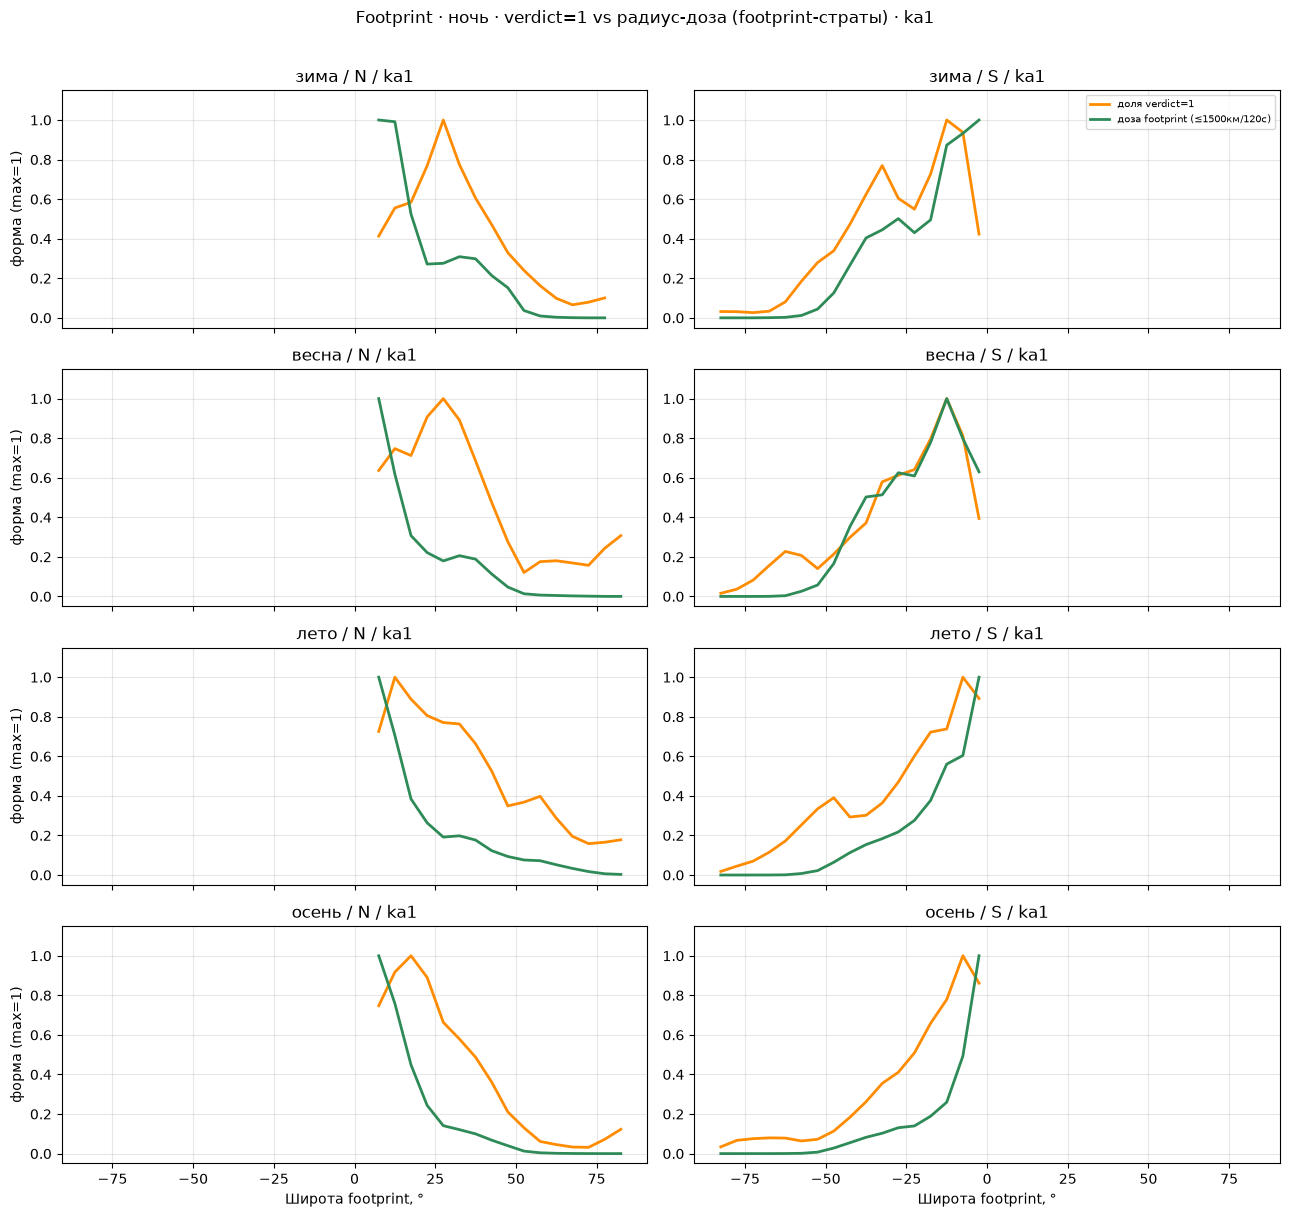

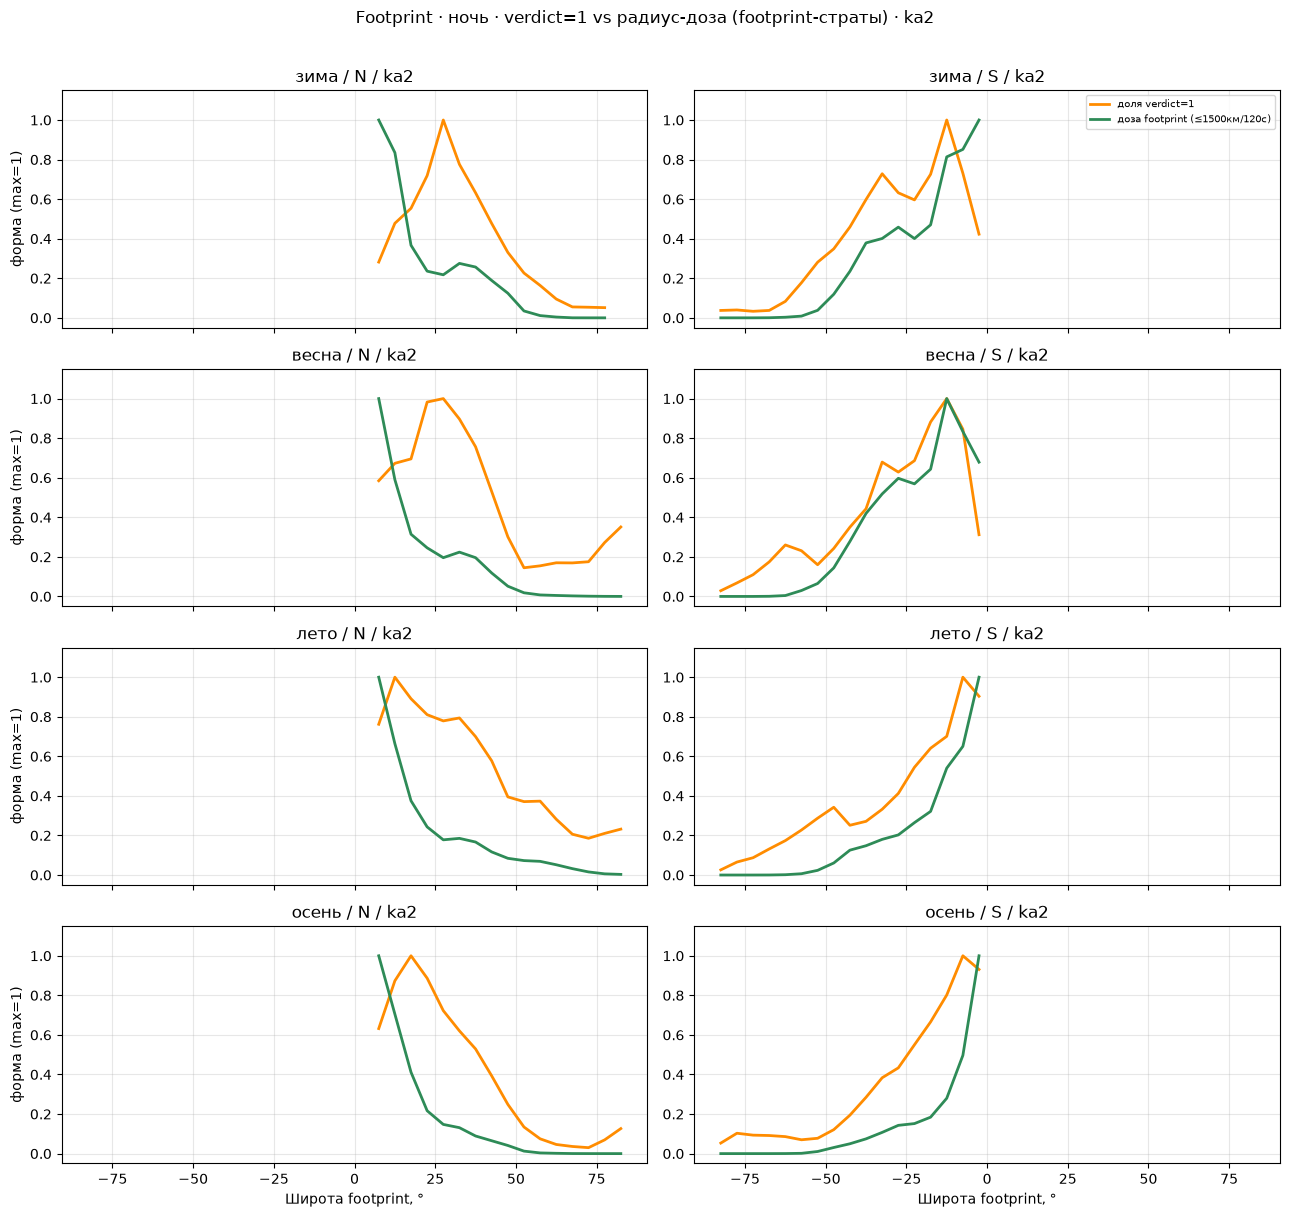

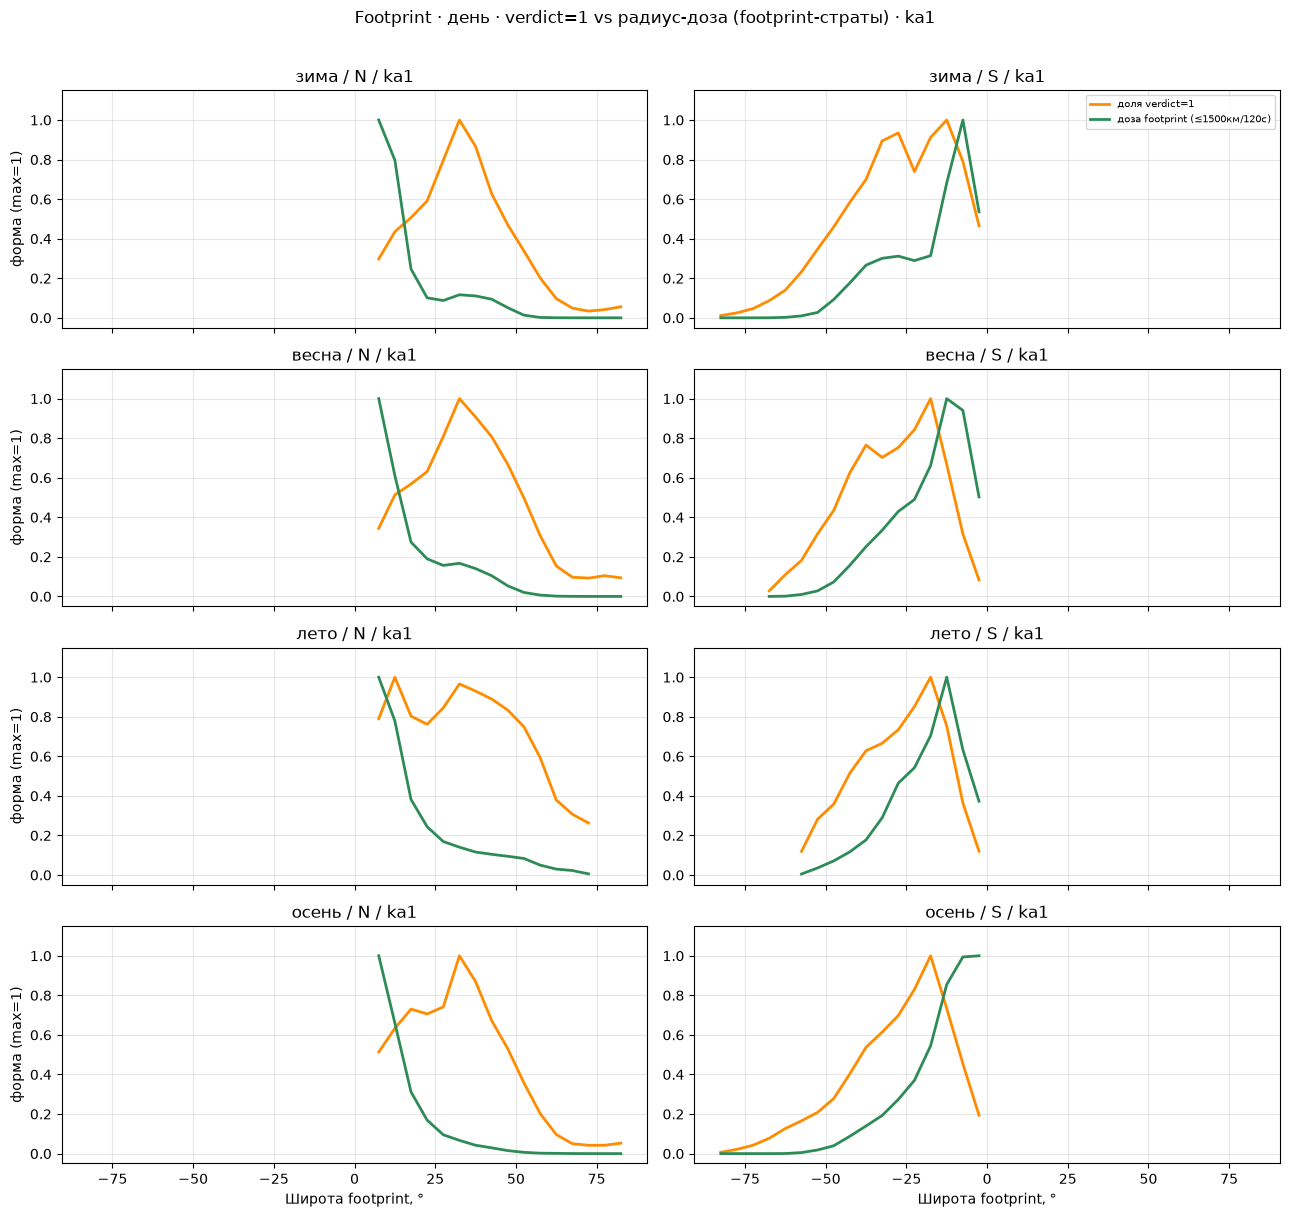

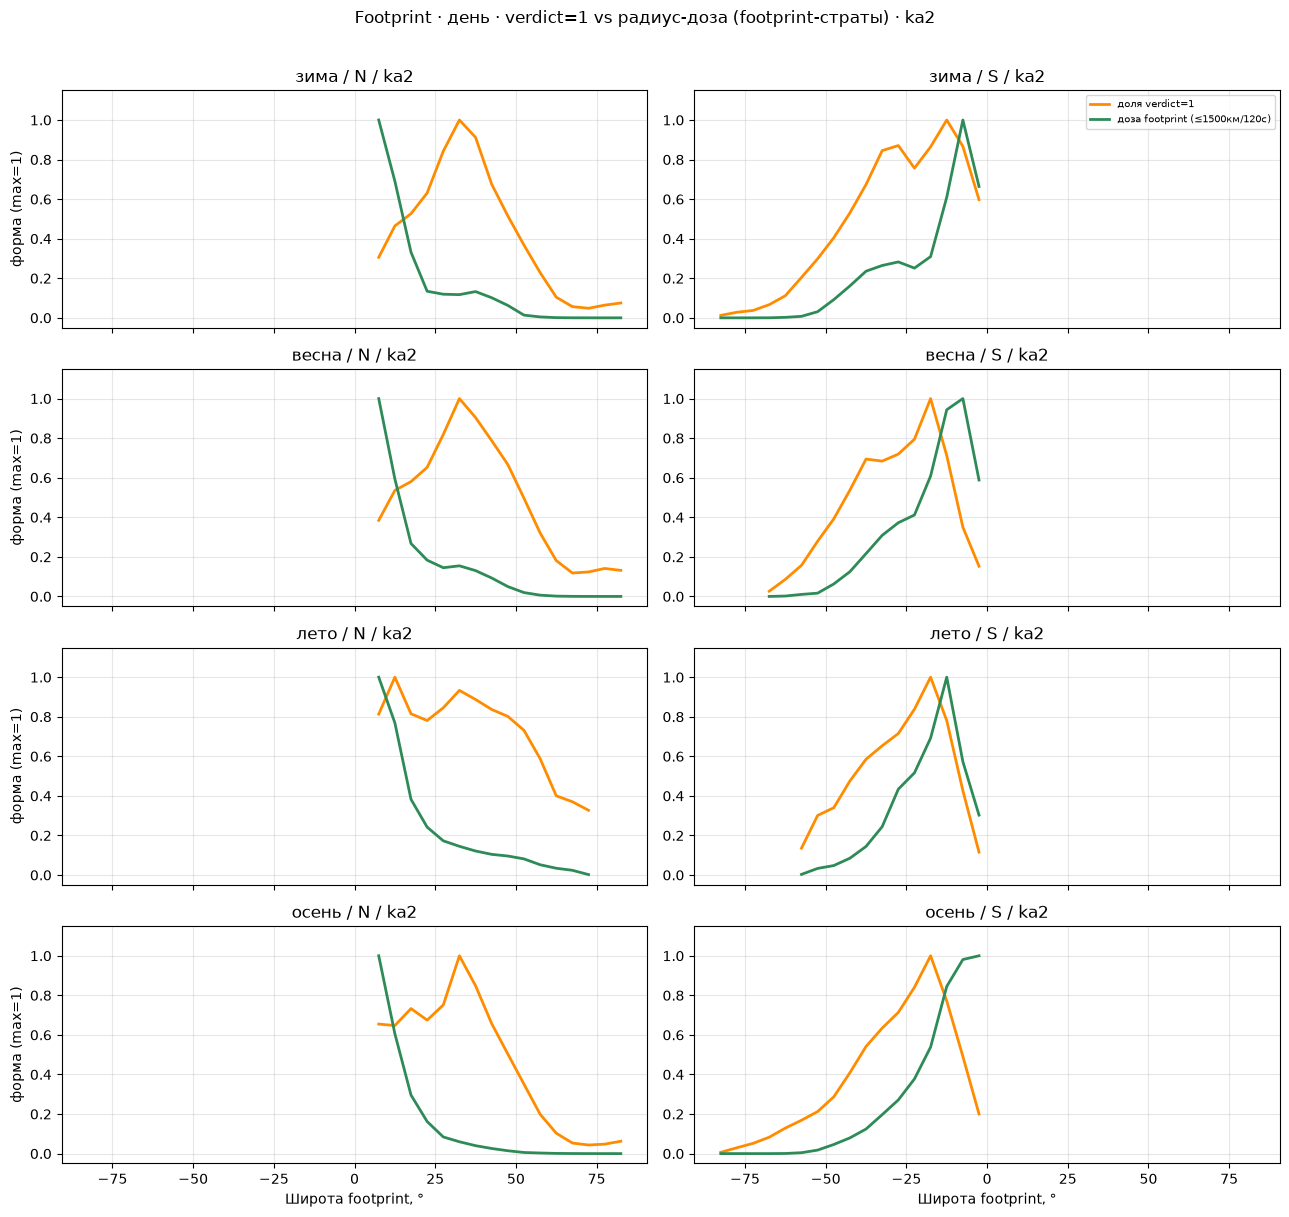

In [4]:
import matplotlib.pyplot as plt


def _maxn(x):
    x = np.asarray(x, dtype=np.float64)
    m = np.nanmax(x) if np.isfinite(x).any() else np.nan
    if not np.isfinite(m) or m <= 0:
        return np.full_like(x, np.nan)
    return x / m


def _rate_masked_fp(pos, exp, min_exp=200):
    out = np.full_like(exp, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = pos[ok] / exp[ok]
    return out


# Широта (footprint), сезон, полушарие, ночь и день, спутник.
# Доля verdict=1 и доза считаются в одной и той же точке footprint.
for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in DOSE_SC_LIST:
        si = sc_to_i_fp[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lat_fp[si, hi, sei, night_i]
                rate = _rate_masked_fp(pos_lat_fp[si, hi, sei, night_i], exp)
                dose_curve = avg_dose_lat_fp[si, hi, sei, night_i]

                ln1, = ax.plot(lat_centers_fp, _maxn(rate), color='darkorange', lw=2,
                                label='доля verdict=1')
                ln2, = ax.plot(lat_centers_fp, _maxn(dose_curve), color='seagreen', lw=2,
                                label=f'доза footprint (≤{DOSE_RADIUS_KM:.0f}км/{DOSE_WINDOW_S}с)')
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2], [l.get_label() for l in (ln1, ln2)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Широта footprint, °')
        fig.suptitle(
            f'Footprint · {night_lab} · verdict=1 vs радиус-доза (footprint-страты) · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


### Долгота, footprint

Та же сетка и те же массивы, что на рисунке широты выше. Ось X — долгота footprint.


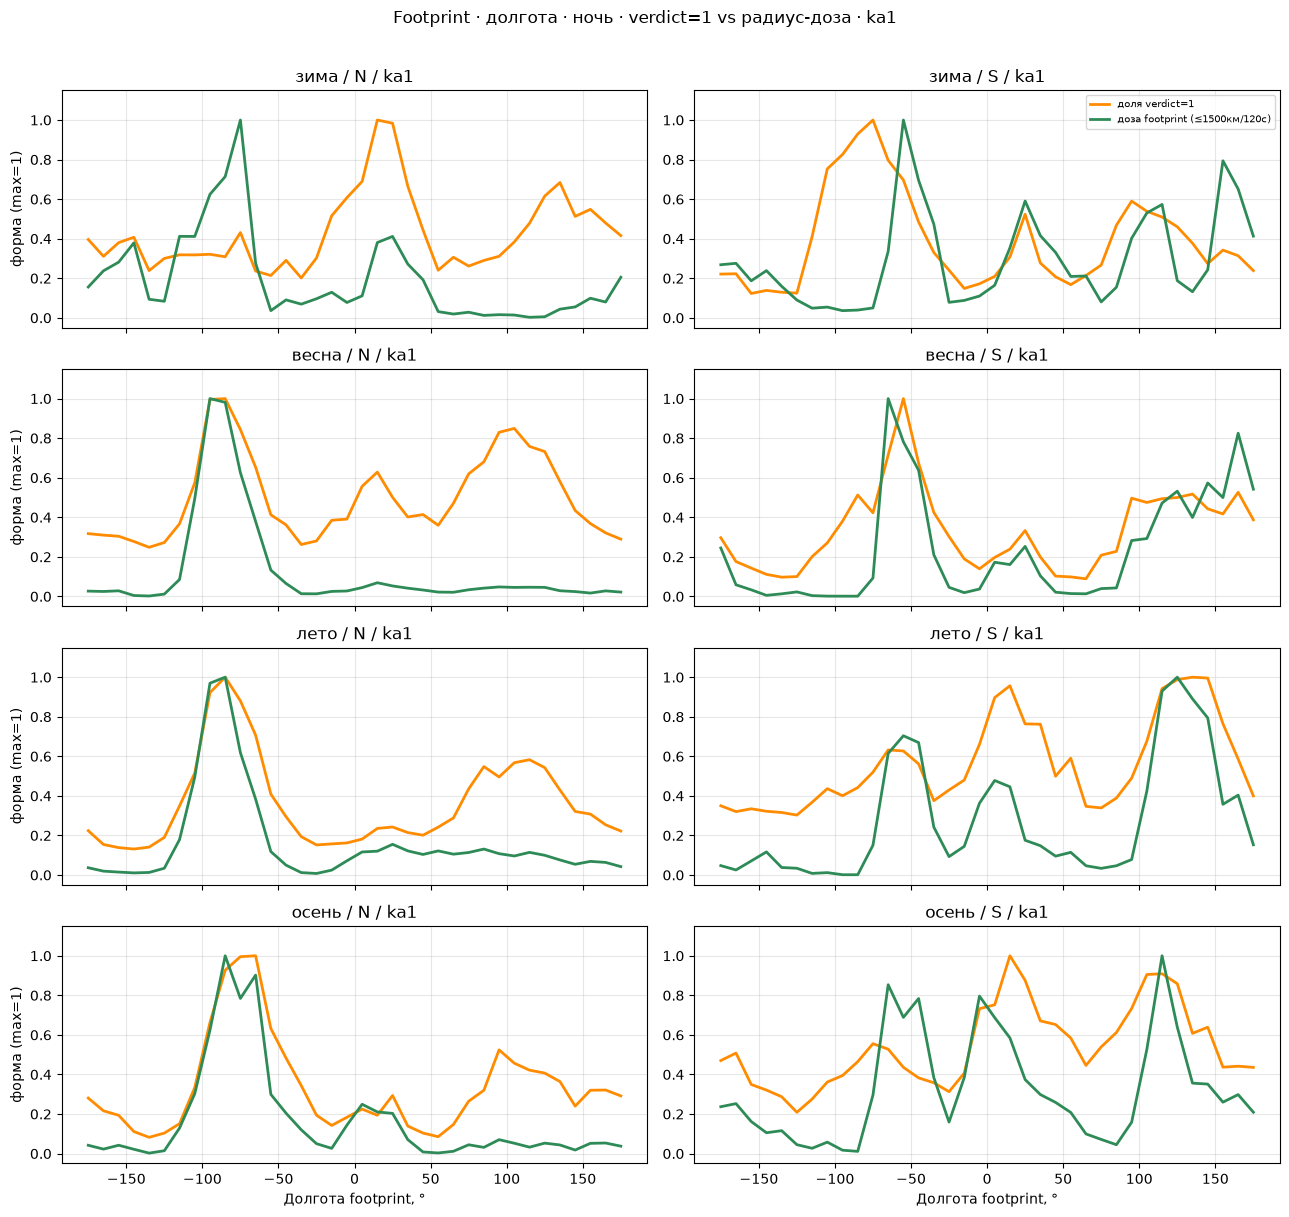

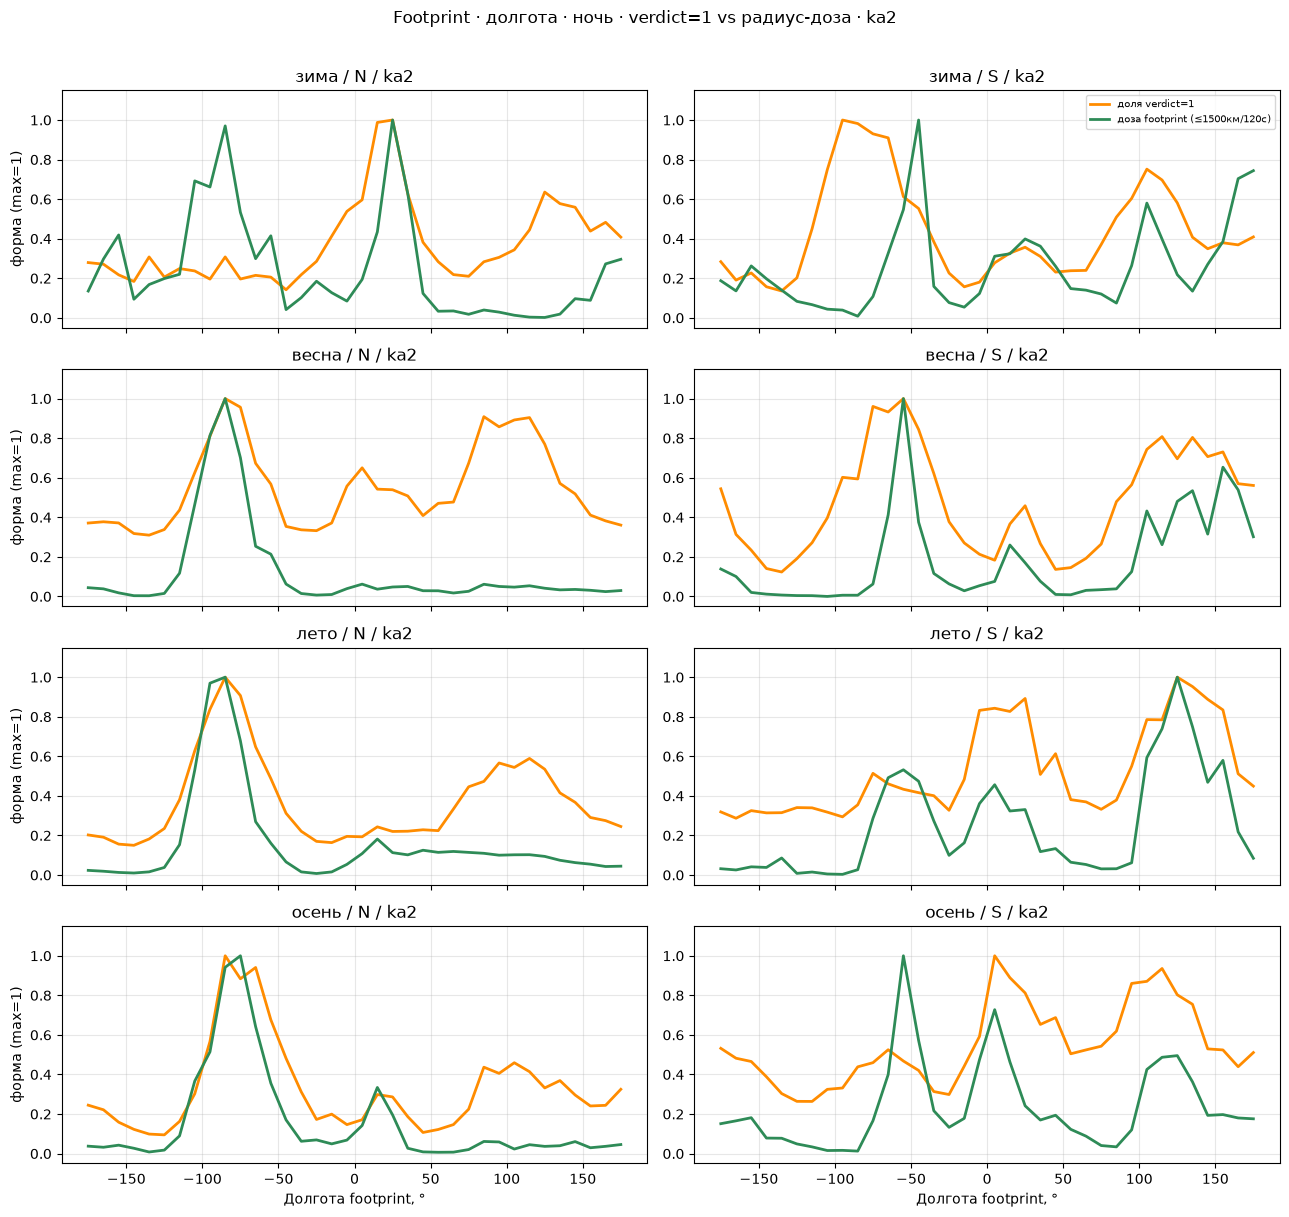

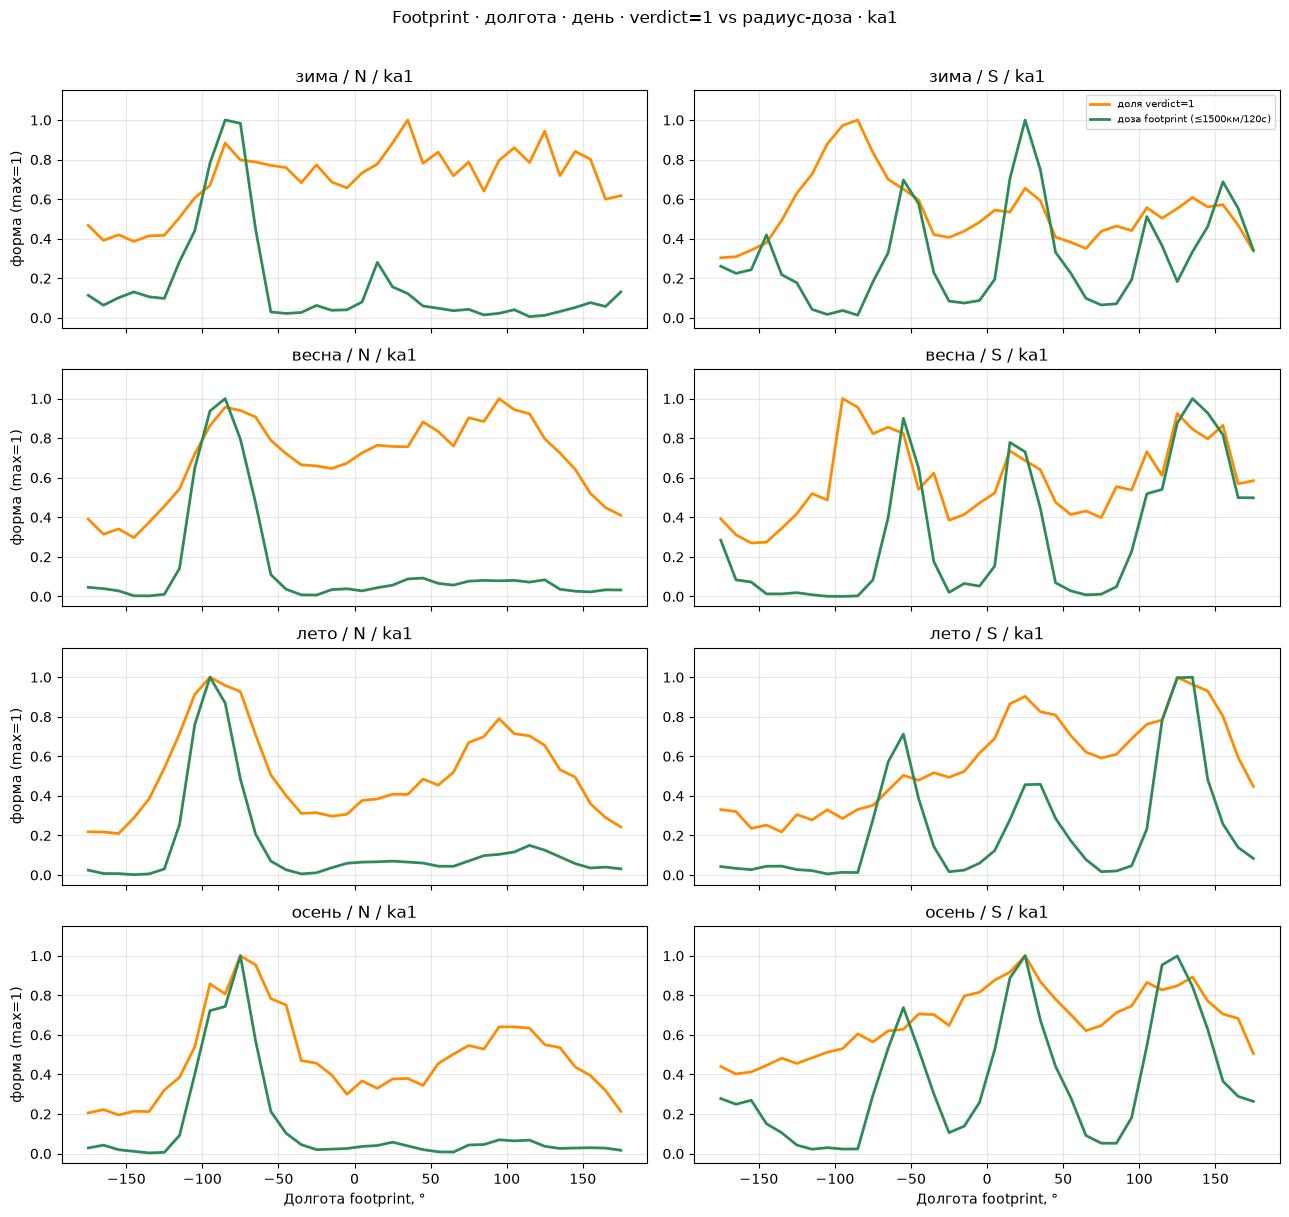

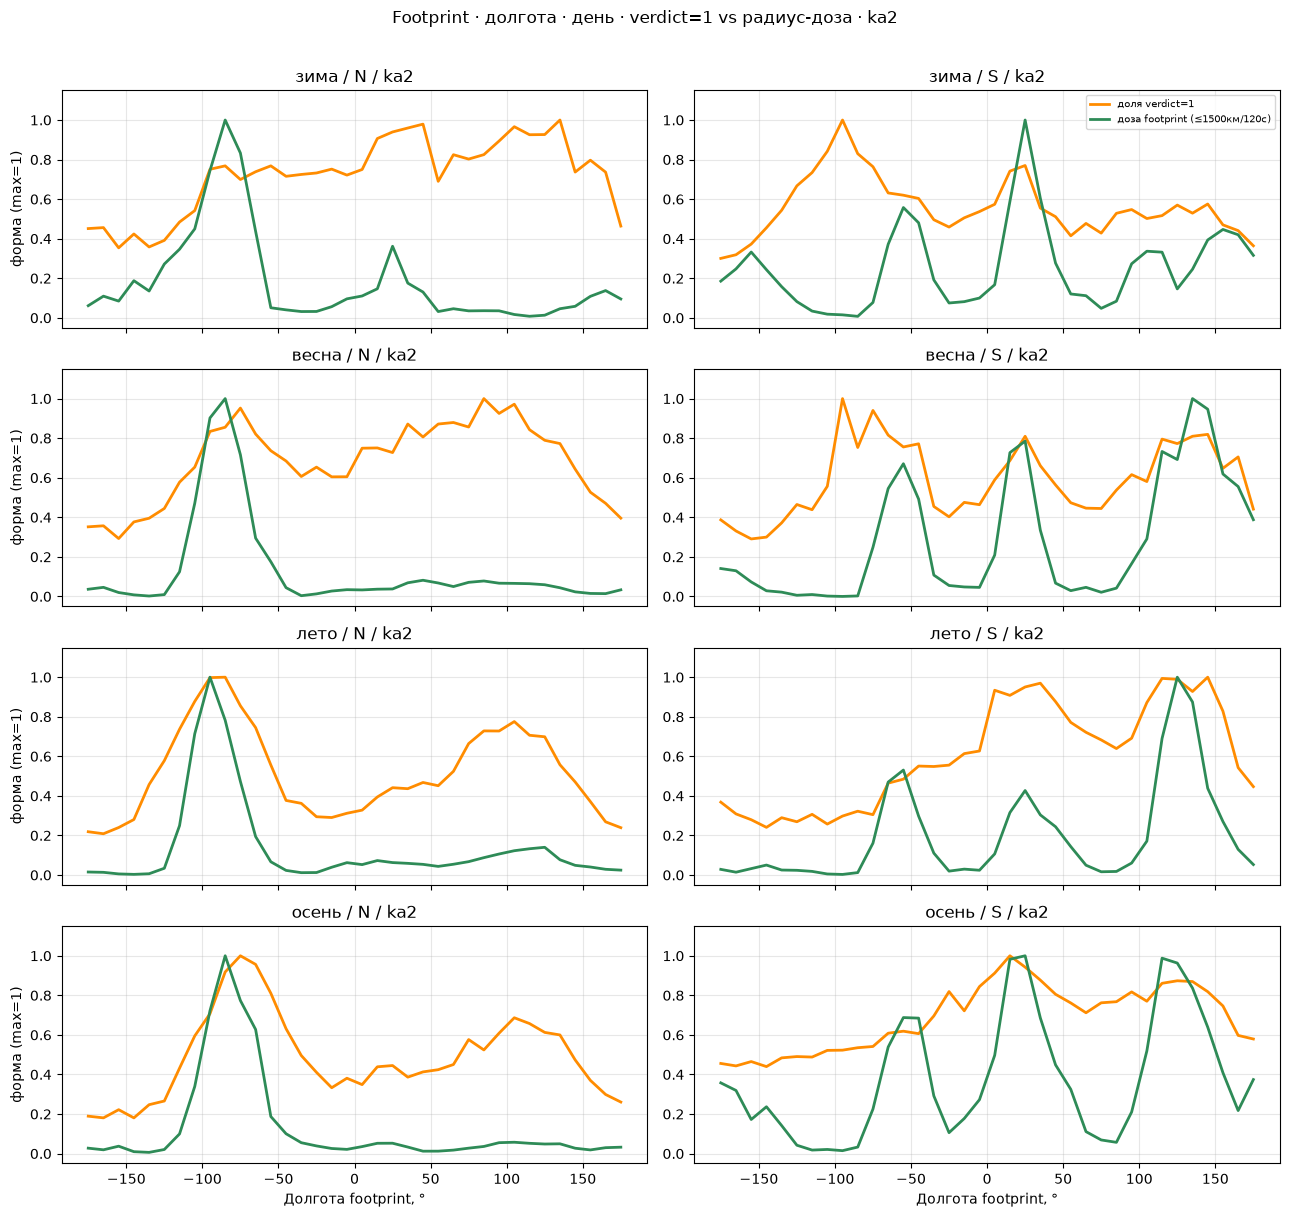

In [7]:
import matplotlib.pyplot as plt


def _maxn(x):
    x = np.asarray(x, dtype=np.float64)
    m = np.nanmax(x) if np.isfinite(x).any() else np.nan
    if not np.isfinite(m) or m <= 0:
        return np.full_like(x, np.nan)
    return x / m


def _rate_masked_fp(pos, exp, min_exp=200):
    out = np.full_like(exp, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = pos[ok] / exp[ok]
    return out


# Долгота (footprint), сезон, полушарие, ночь и день, спутник.
# Те же массивы, что на рисунке широты; ось X — долгота footprint.
# В агрегацию входит сэмпл с валидным бином по обеим осям (маска ok_bin_all).
for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in DOSE_SC_LIST:
        si = sc_to_i_fp[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lon_fp[si, hi, sei, night_i]
                rate = _rate_masked_fp(pos_lon_fp[si, hi, sei, night_i], exp)
                dose_curve = avg_dose_lon_fp[si, hi, sei, night_i]

                ln1, = ax.plot(lon_centers_fp, _maxn(rate), color='darkorange', lw=2,
                                label='доля verdict=1')
                ln2, = ax.plot(lon_centers_fp, _maxn(dose_curve), color='seagreen', lw=2,
                                label=f'доза footprint (≤{DOSE_RADIUS_KM:.0f}км/{DOSE_WINDOW_S}с)')
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2], [l.get_label() for l in (ln1, ln2)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Долгота footprint, °')
        fig.suptitle(
            f'Footprint · долгота · {night_lab} · verdict=1 vs радиус-доза · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


## Число молний в бине, без радиуса

Та же сетка, тот же период и те же страты, что у дозы от footprint. Радиусного поиска нет: считается, сколько разрядов WWLLN попало в этот широтный или долготный бин за эти сутки. У молнии своей точки footprint нет, страта берётся по её координатам и времени. Кривая молний одна на оба спутника: период общий, набор разрядов один и тот же.

Так видно, меняется ли сравнение формы, если вместо «молнии рядом с трассой за 2 минуты» взять просто «молнии в этом бине за сутки».


In [8]:
%%time
import numpy as np
import wwlln_common as wc

# === Просто число молний в том же бине (без радиуса/окна), для сравнения с footprint-
# графиками выше === Та же сетка (lat_edges_fp/lon_edges_fp), тот же период (CMP_DAYS_FP)
# и та же стратификация (полушарие/сезон/ночь-день), что и footprint-доза — но без
# радиус-поиска: просто сколько разрядов WWLLN попало в этот широтный/долготный бин.
# У молнии нет "footprint" (она уже на земле) — страты считаются по её собственным
# координатам и времени, не по спутнику. Поэтому кривая одна на оба спутника (период
# общий — CMP_DAYS_FP).

flash_lat_fp = np.zeros((n_hem_fp, n_sea_fp, n_night_fp, n_lat_fp))
flash_lon_fp = np.zeros((n_hem_fp, n_sea_fp, n_night_fp, n_lon_fp))

for day_i, day in enumerate(CMP_DAYS_FP):
    ae_today = wc.read_ae_file(wc.ae_path_for_day(_paths_fp['ae'], day))
    if ae_today.empty:
        continue
    lat_e = ae_today['lat'].to_numpy(dtype=np.float64)
    lon_e = ae_today['lon'].to_numpy(dtype=np.float64)
    month_e = ae_today['datetime'].dt.month.to_numpy()
    sza_e = wc.solar_zenith_deg(ae_today['datetime'].values, lat_e, lon_e)
    night_e = (sza_e > NIGHT_SZA_DEG_D).astype(np.int8)
    hem_e, sea_e = _season_idx(lat_e, month_e)
    lb_e = np.digitize(lat_e, lat_edges_fp) - 1
    lo_e = np.digitize(lon_e, lon_edges_fp) - 1
    ok_e = (lb_e >= 0) & (lb_e < n_lat_fp) & (lo_e >= 0) & (lo_e < n_lon_fp)

    g_e = (hem_e[ok_e].astype(np.int64) * n_sea_fp + sea_e[ok_e]) * n_night_fp + night_e[ok_e]
    flash_lat_fp += np.bincount(g_e * n_lat_fp + lb_e[ok_e], minlength=n_g_fp * n_lat_fp).reshape(
        n_hem_fp, n_sea_fp, n_night_fp, n_lat_fp)
    flash_lon_fp += np.bincount(g_e * n_lon_fp + lo_e[ok_e], minlength=n_g_fp * n_lon_fp).reshape(
        n_hem_fp, n_sea_fp, n_night_fp, n_lon_fp)

    if (day_i + 1) % 50 == 0:
        print(f'  {day_i + 1}/{len(CMP_DAYS_FP)} суток обработано')

print(f'готово. Всего молний учтено: {int(flash_lat_fp.sum()):,}')


  50/255 суток обработано
  100/255 суток обработано
  150/255 суток обработано
  200/255 суток обработано
  250/255 суток обработано
готово. Всего молний учтено: 179,488,121
CPU times: user 3min 59s, sys: 21.3 s, total: 4min 20s
Wall time: 4min 25s


### Широта, число молний в бине

Форма доли свистов и форма числа разрядов в широтном бине. Ночь и день отдельно.


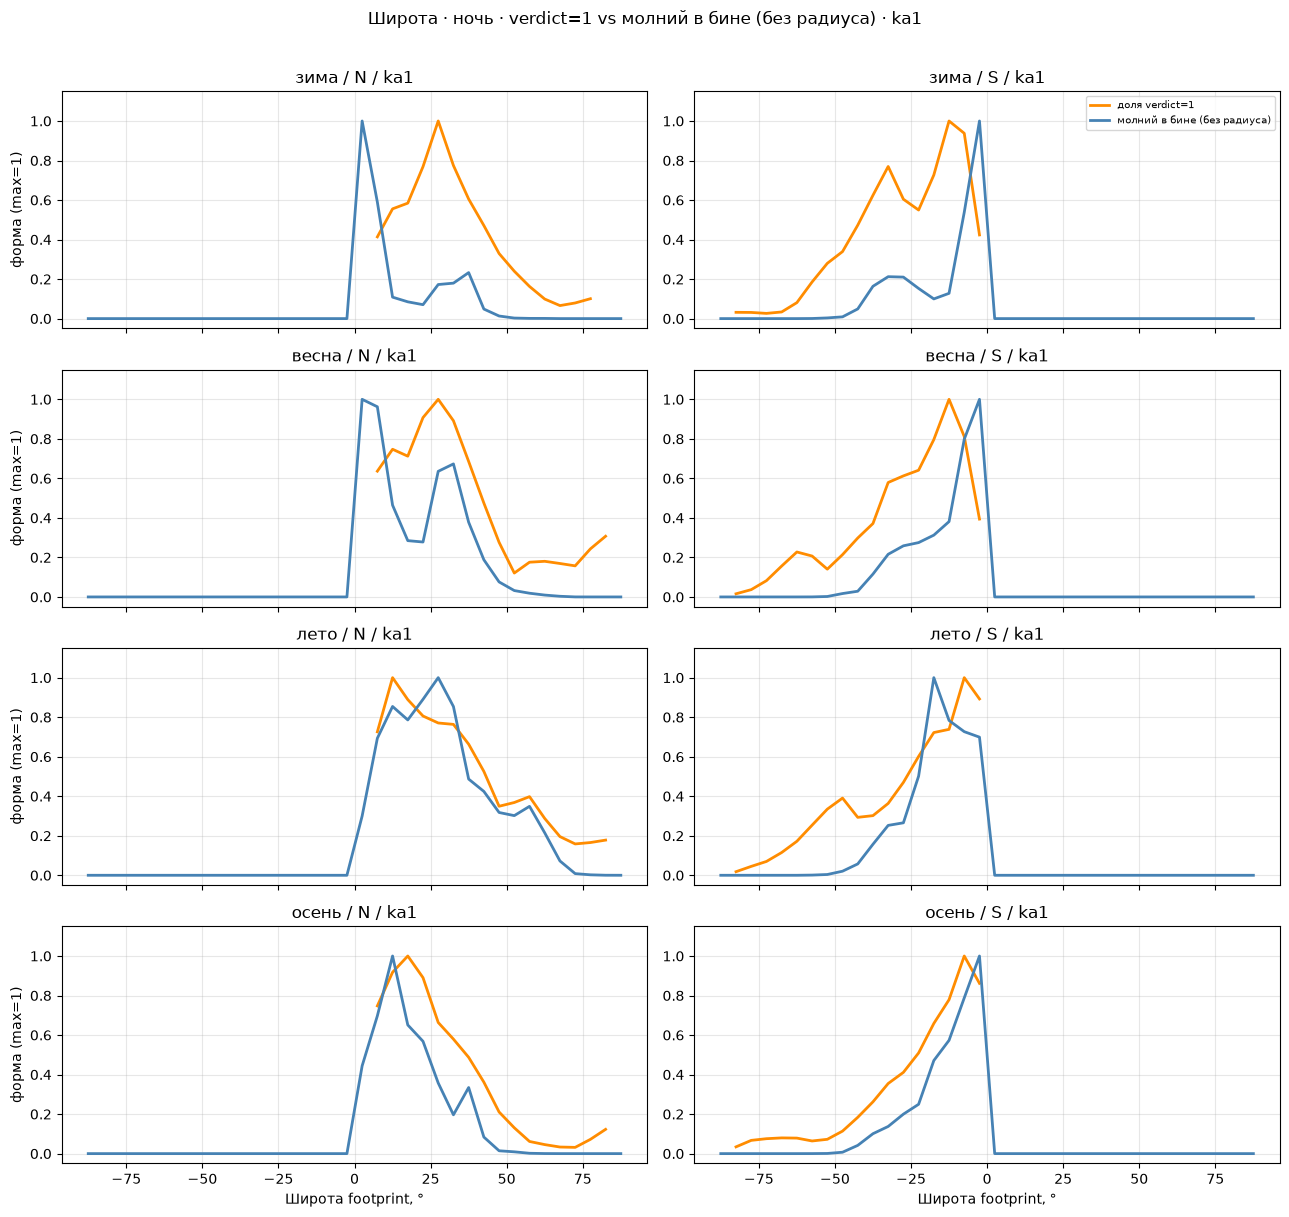

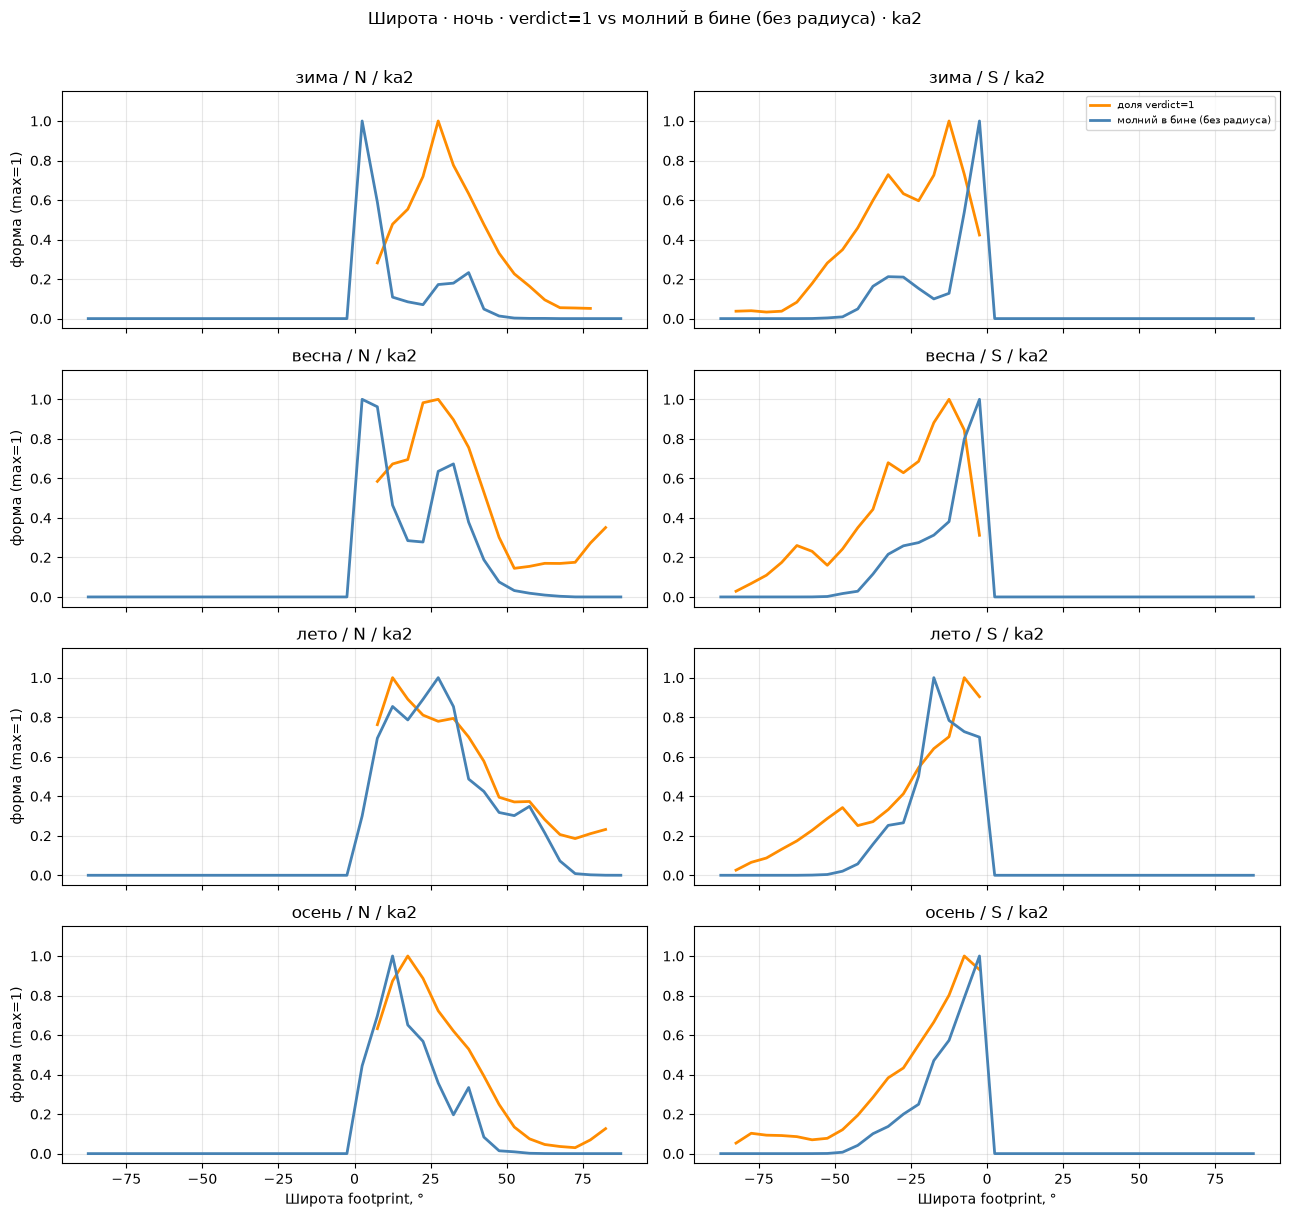

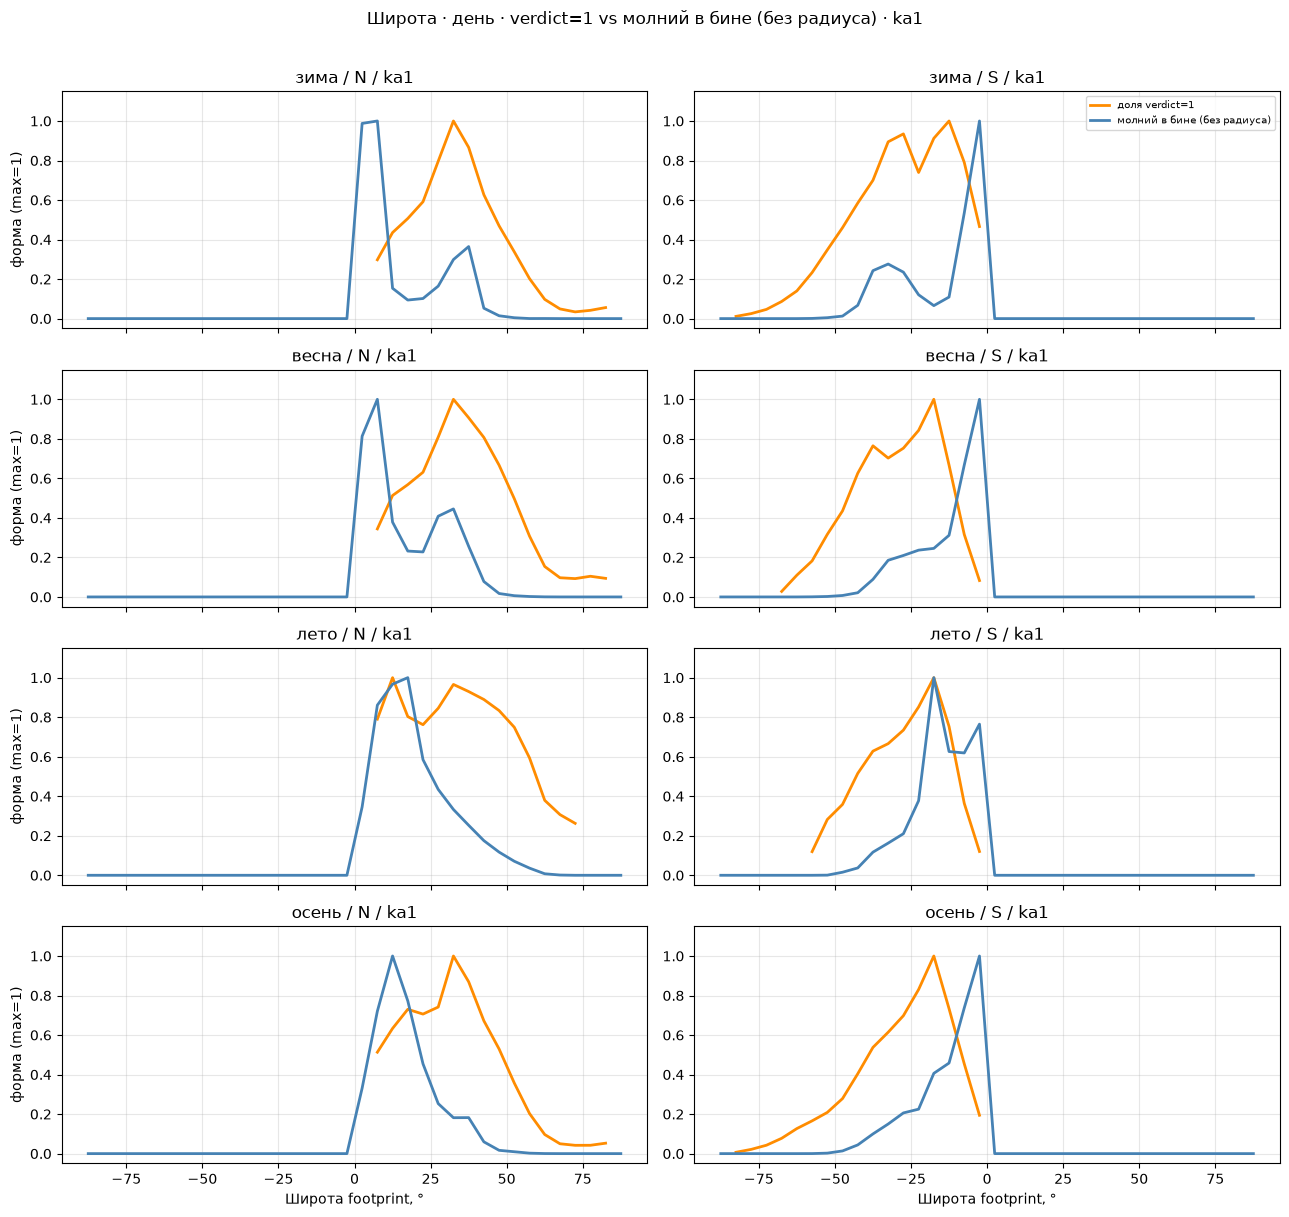

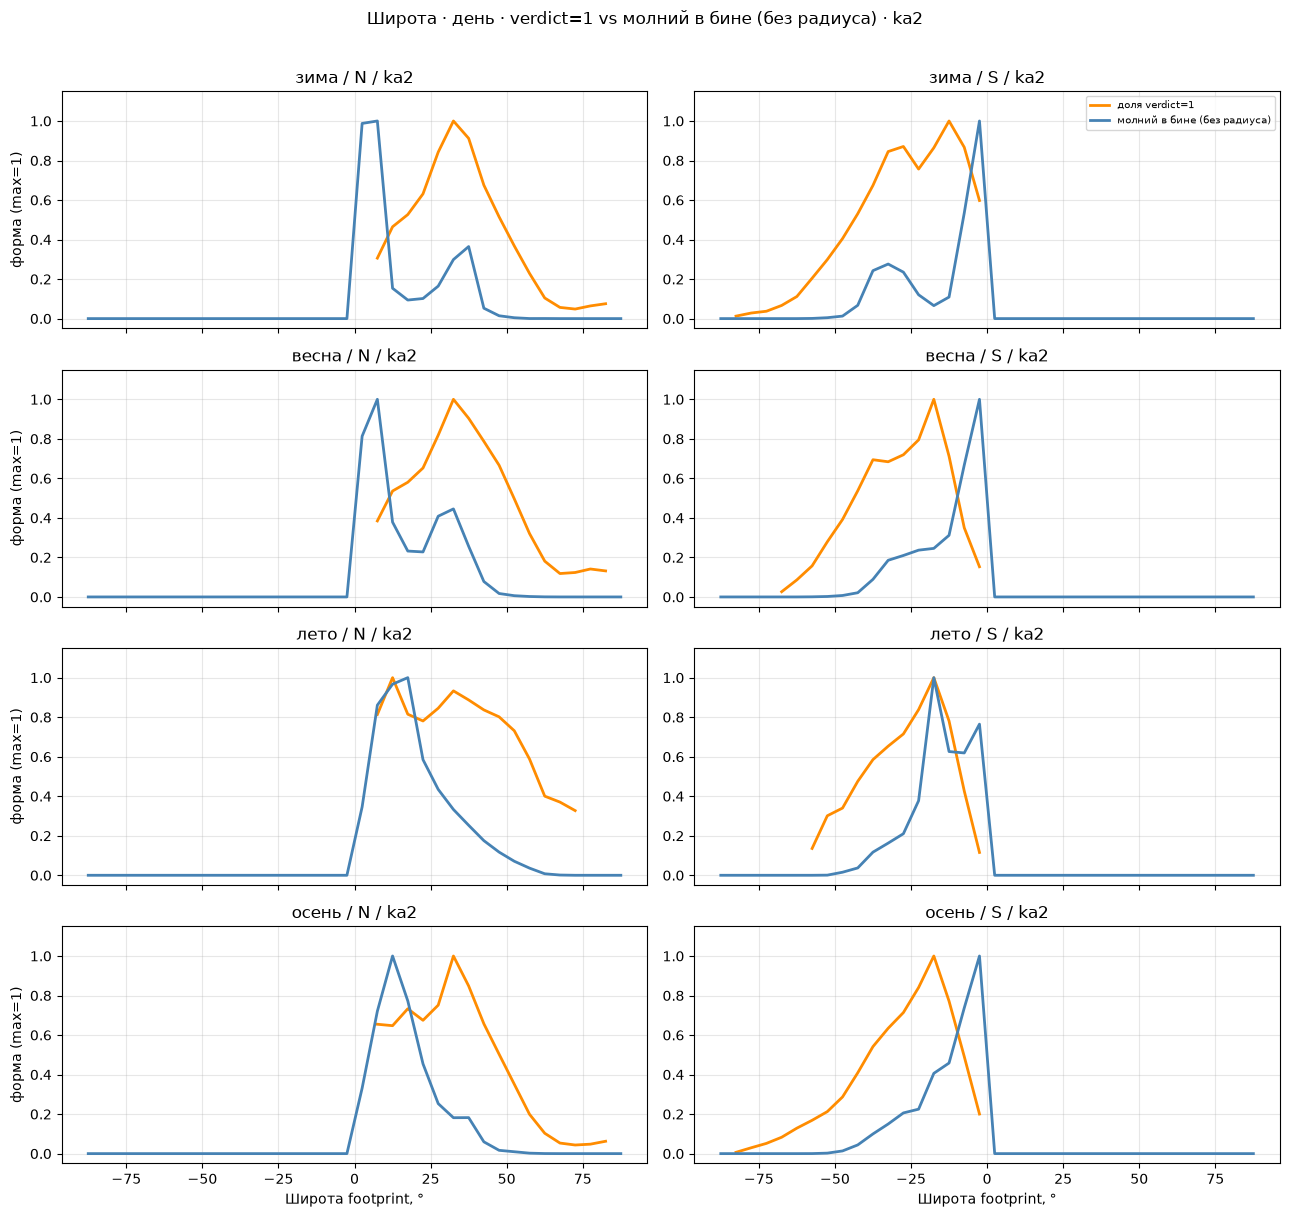

In [9]:
import matplotlib.pyplot as plt


def _maxn(x):
    x = np.asarray(x, dtype=np.float64)
    m = np.nanmax(x) if np.isfinite(x).any() else np.nan
    if not np.isfinite(m) or m <= 0:
        return np.full_like(x, np.nan)
    return x / m


def _rate_masked_fp(pos, exp, min_exp=200):
    out = np.full_like(exp, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = pos[ok] / exp[ok]
    return out


# Широта: доля verdict=1 vs просто число молний в бине (без радиуса) — та же сетка,
# что и в footprint-доза блоке выше, для прямого сравнения "с радиусом" / "без".
for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in DOSE_SC_LIST:
        si = sc_to_i_fp[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lat_fp[si, hi, sei, night_i]
                rate = _rate_masked_fp(pos_lat_fp[si, hi, sei, night_i], exp)
                flash_curve = flash_lat_fp[hi, sei, night_i]

                ln1, = ax.plot(lat_centers_fp, _maxn(rate), color='darkorange', lw=2,
                                label='доля verdict=1')
                ln2, = ax.plot(lat_centers_fp, _maxn(flash_curve), color='steelblue', lw=2,
                                label='молний в бине (без радиуса)')
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2], [l.get_label() for l in (ln1, ln2)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Широта footprint, °')
        fig.suptitle(
            f'Широта · {night_lab} · verdict=1 vs молний в бине (без радиуса) · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


### Долгота, число молний в бине

То же сравнение вдоль долготы.


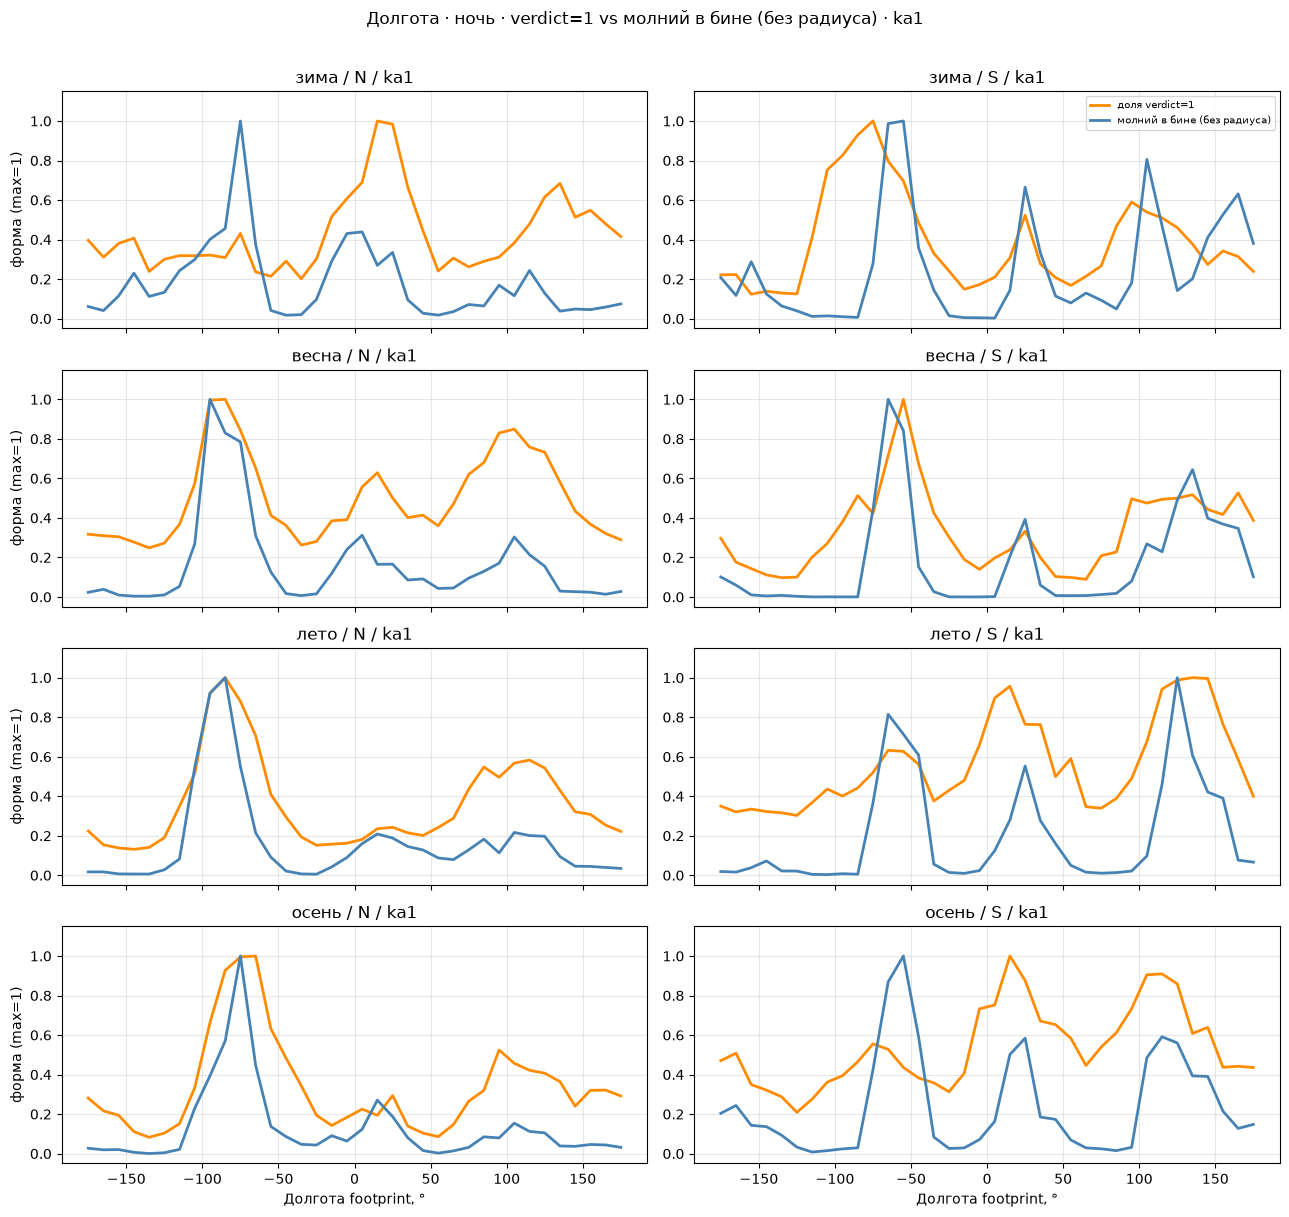

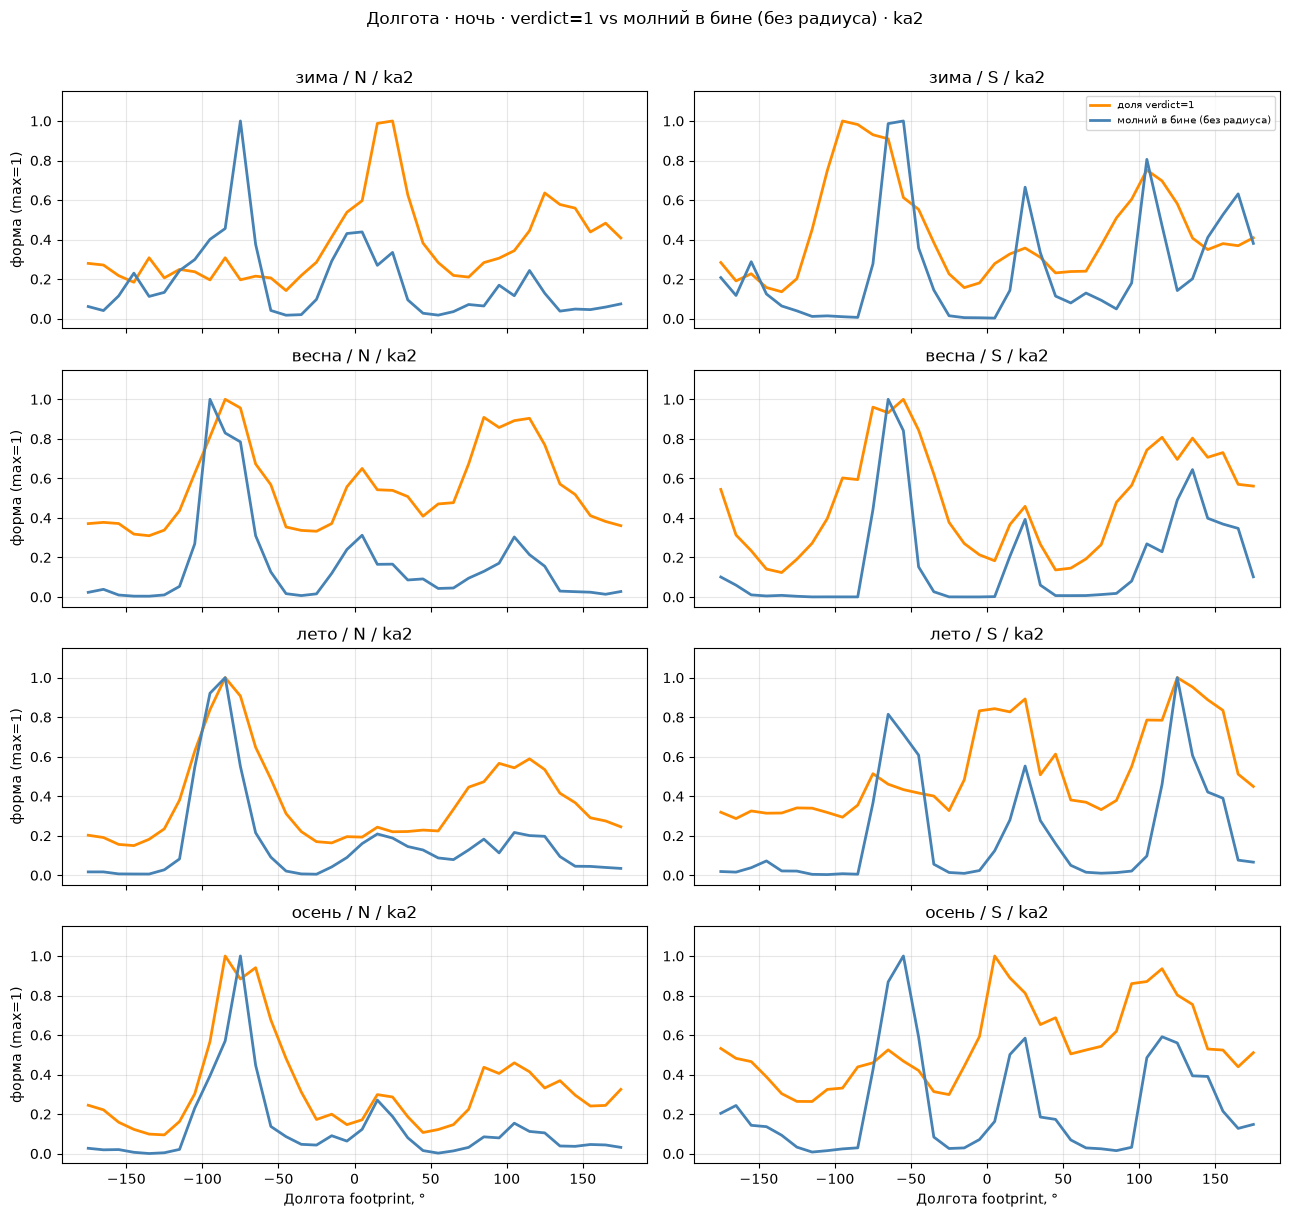

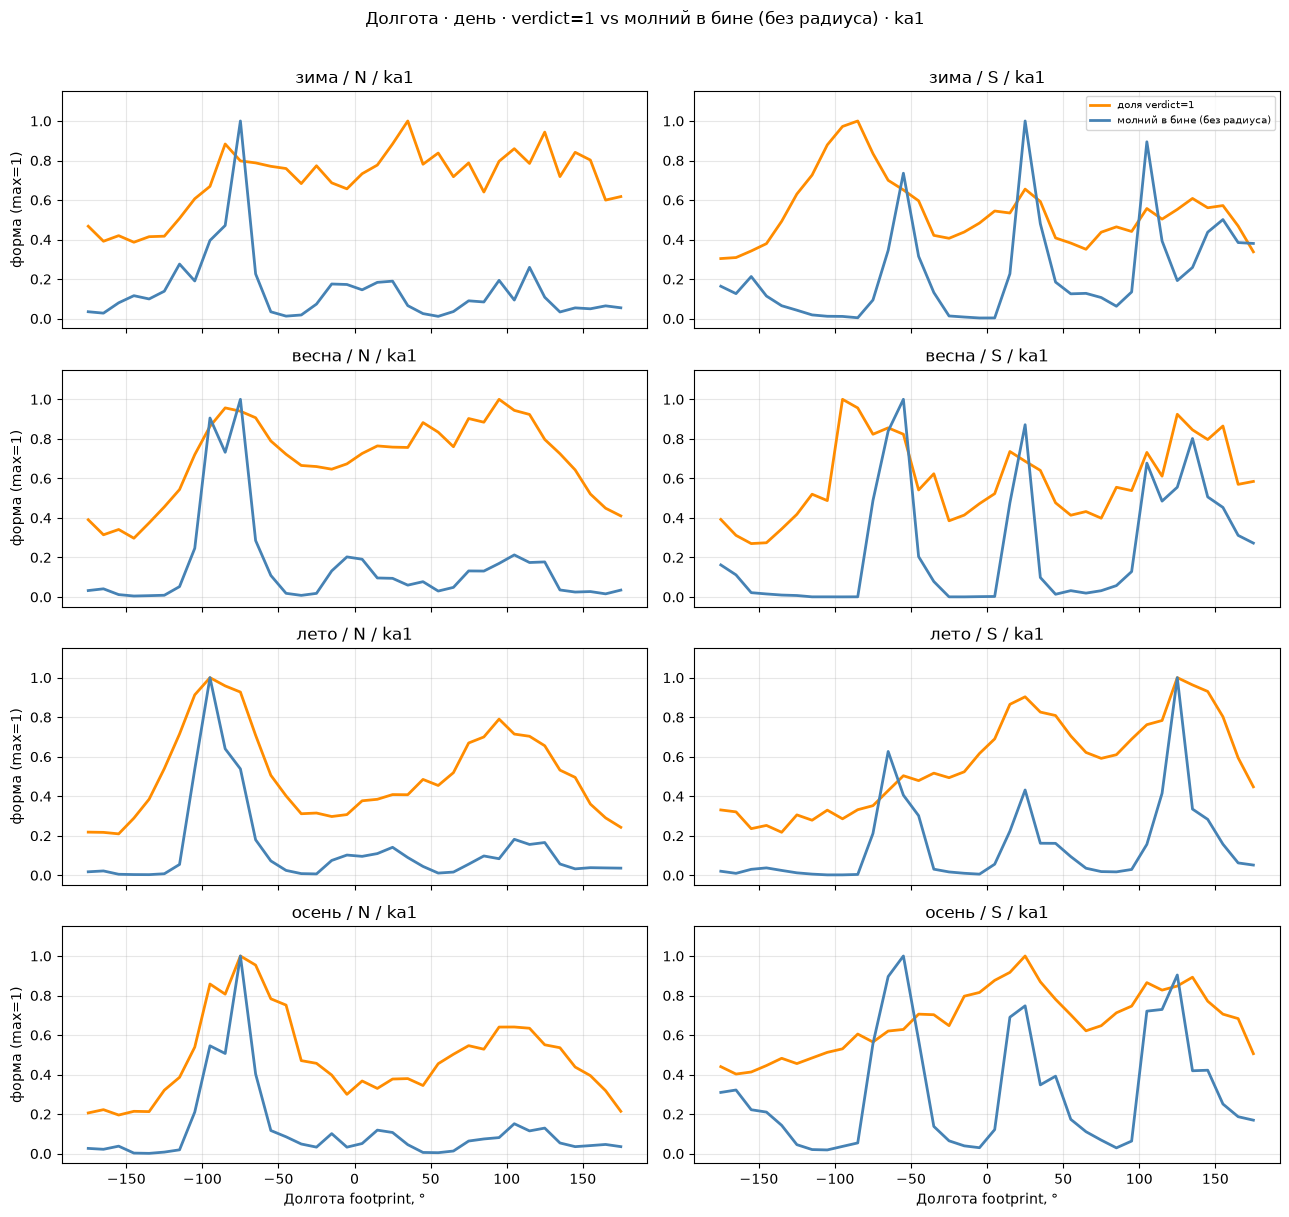

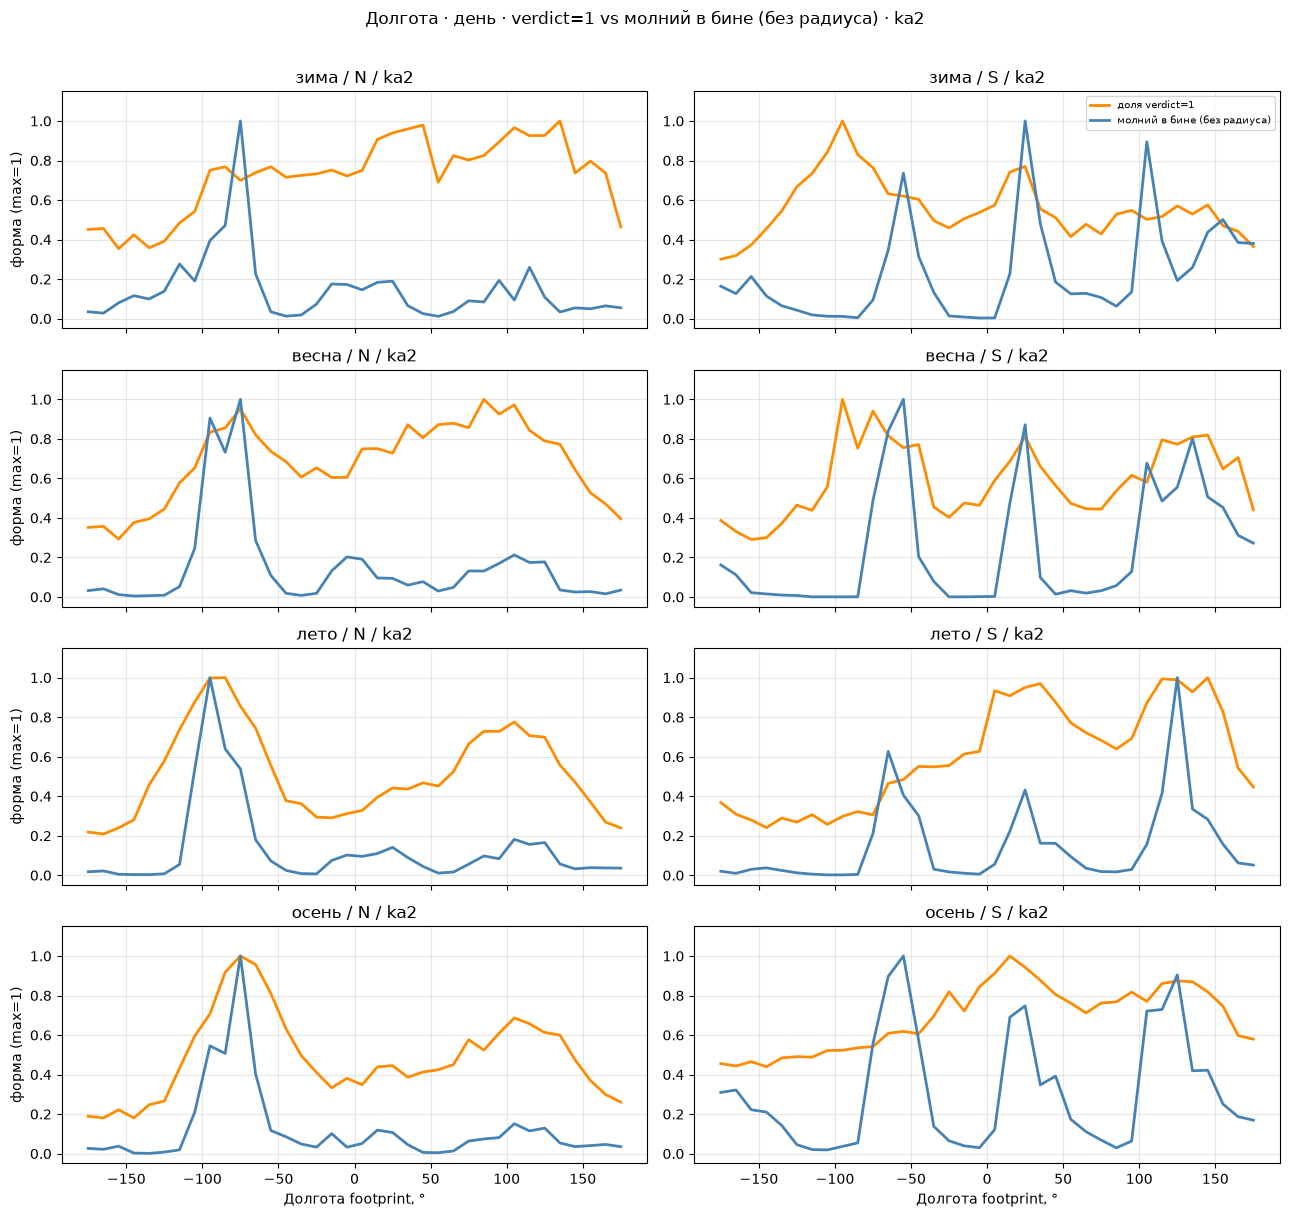

In [10]:
import matplotlib.pyplot as plt

# Долгота: то же самое, но по долготе.
for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in DOSE_SC_LIST:
        si = sc_to_i_fp[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lon_fp[si, hi, sei, night_i]
                rate = _rate_masked_fp(pos_lon_fp[si, hi, sei, night_i], exp)
                flash_curve = flash_lon_fp[hi, sei, night_i]

                ln1, = ax.plot(lon_centers_fp, _maxn(rate), color='darkorange', lw=2,
                                label='доля verdict=1')
                ln2, = ax.plot(lon_centers_fp, _maxn(flash_curve), color='steelblue', lw=2,
                                label='молний в бине (без радиуса)')
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2], [l.get_label() for l in (ln1, ln2)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Долгота footprint, °')
        fig.suptitle(
            f'Долгота · {night_lab} · verdict=1 vs молний в бине (без радиуса) · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)
